# EDA-01 | Exploratory Data Analysis

## Objective

This notebook analyzes the Online Retail II dataset to identify
sales trends, customer purchasing behavior, geographic performance,
and product-level revenue concentration.

### Analytical Scope

- Sales distribution and outlier analysis
- Monthly sales trends and business KPIs
- Country-level sales and customer analysis
- Product performance and Pareto analysis

### Data Source

- Dataset: Online Retail II (UCI / Kaggle)
- Prepared by: Notebook 02 — Data Cleaning
- Analytical dataset: online_retail_positive_sales_v2.csv

### Methodology

Revenue analysis is based on positive sales transactions.
Cancellation-flagged transactions, non-positive quantities,
and non-positive prices are excluded.

Customer-level metrics are calculated using transactions
with valid Customer IDs.

In [1]:
# EDA-01-01: Load & Validate Analytical Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load validated positive-sales dataset
data_path = Path("../data/processed/online_retail_positive_sales_v2.csv")

assert data_path.exists(), f"File not found: {data_path}"

sales_df = pd.read_csv(
    data_path,
    parse_dates=["InvoiceDate"],
    dtype={"Customer ID": "string"},
    low_memory=False
)

# Validate dataset structure
print("Dataset Shape:", sales_df.shape)
print("Columns:", sales_df.columns.tolist())

print("\nData Types:")
print(sales_df.dtypes)

print("\nData Quality Validation:")
print("Missing Customer IDs:", f"{sales_df['Customer ID'].isna().sum():,}")
print("Negative Quantities:", (sales_df["Quantity"] < 0).sum())
print("Non-Positive Prices:", (sales_df["Price"] <= 0).sum())
print(
    "Cancellation Flags:",
    sales_df["Invoice"].astype(str).str.startswith("C").sum()
)

print("\nSales Performance:")
print(f"Total Revenue: £{sales_df['Sales'].sum():,.2f}")
print(f"Unique Customers: {sales_df['Customer ID'].nunique():,}")

# Validation assertions
assert len(sales_df) == 1_007_913
assert (sales_df["Quantity"] > 0).all()
assert (sales_df["Price"] > 0).all()
assert not sales_df["Invoice"].astype(str).str.startswith("C").any()

Dataset Shape: (1007913, 9)
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Sales']

Data Types:
Invoice                   str
StockCode                 str
Description               str
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID            string
Country                   str
Sales                 float64
dtype: object

Data Quality Validation:
Missing Customer IDs: 228,488
Negative Quantities: 0
Non-Positive Prices: 0
Cancellation Flags: 0

Sales Performance:
Total Revenue: £20,476,260.45
Unique Customers: 5,878


### EDA-01-01 | Interpretation

- **Validated Sales Records:** 1,007,913
- **Total Positive Sales Revenue:** £20,476,260.45
- **Unique Identifiable Customers:** 5,878
- **Missing Customer IDs:** 228,488 (22.67%)

The dataset contains only positive-quantity, positive-price transactions without cancellation flags.

**Analytical Implications:**
- Sales trend, geographic performance, and product analysis use the complete positive-sales dataset.
- Customer-level analysis excludes records with missing Customer IDs.
- Revenue represents positive sales only, not net revenue after returns and cancellations.

## EDA-02 | Dataset Overview & Validation

### Objective

This section examines the statistical characteristics and data quality of the validated positive-sales dataset before conducting detailed exploratory analysis.

### Scope

- Descriptive statistics for numerical and categorical variables
- Unique transaction, product, customer, and country counts
- Transaction date range
- Missing value assessment
- Identification of potential outliers for further investigation

### Analytical Approach

All analyses use the validated `sales_df` dataset prepared in EDA-01.

The objective is to understand the dataset's structure, distribution, and analytical limitations without modifying the underlying transaction records.

In [2]:
# EDA-02-01: Descriptive Statistics

# 1. Numerical variables
print("=== Numerical Statistics ===")

numerical_summary = sales_df[
    ["Quantity", "Price", "Sales"]
].describe().round(2)

display(numerical_summary)


# 2. Categorical variables
print("\n=== Categorical Statistics ===")

categorical_summary = sales_df[
    ["Invoice", "StockCode", "Description", "Country"]
].describe()

display(categorical_summary)


# 3. Unique value counts
print("\n=== Unique Value Counts ===")

unique_summary = pd.DataFrame({
    "Column": sales_df.columns,
    "Unique Values": sales_df.nunique().values
})

display(unique_summary)


# 4. Transaction date range
print("\n=== Transaction Date Range ===")

print("Start Date:", sales_df["InvoiceDate"].min())
print("End Date:", sales_df["InvoiceDate"].max())

=== Numerical Statistics ===


,Quantity,Price,Sales
count,1007913.00,1007913.00,1007913.00
mean,11.12,4.07,20.32
std,128.47,50.43,205.72
min,1.00,0.00,0.00
25%,1.00,1.25,4.13
50%,4.00,2.10,10.08
75%,12.00,4.13,17.70
max,80995.00,25111.09,168469.60



=== Categorical Statistics ===


,Invoice,StockCode,Description,Country
count,1007913,1007913,1007913,1007913
unique,40077,4917,5399,43
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,1114,5511,5601,926038



=== Unique Value Counts ===


,Column,Unique Values
0,Invoice,40077
1,StockCode,4917
2,Description,5399
3,Quantity,520
4,InvoiceDate,37212
5,Price,2275
6,Customer ID,5878
7,Country,43
8,Sales,6845



=== Transaction Date Range ===
Start Date: 2009-12-01 07:45:00
End Date: 2011-12-09 12:50:00


### EDA-02-01 | Interpretation

**Dataset Characteristics**
- Total Sales Records: 1,007,913
- Unique Invoices: 40,077
- Unique StockCodes: 4,917
- Unique Product Descriptions: 5,399
- Countries: 43
- Identifiable Customers: 5,878

**Key Findings**
1. Quantity, Price, and Sales exhibit mean values higher than their medians, suggesting positively skewed distributions.
2. Maximum Quantity (80,995) and Maximum Sales (£168,469.60) indicate potential high-value transactions requiring further examination.
3. Product descriptions outnumber unique StockCodes, suggesting possible differences in product naming or code-to-description mappings.
4. The dataset covers 43 countries, providing a basis for geographic sales analysis.

**Analytical Implications**
- Examine sales distributions and potential outliers before interpreting average transaction values.
- Investigate extreme transaction values rather than automatically removing them.
- Validate product identifiers when performing product-level analysis.
- Distinguish line-item revenue from order-level Average Order Value (AOV).

In [3]:
# EDA-02-02: Missing Value Validation

missing_summary = pd.DataFrame({
    "Missing Count": sales_df.isna().sum(),
    "Missing Percentage (%)": (
        sales_df.isna().mean() * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        "Missing Count",
        ascending=False
    )
)

print(f"Total Records: {len(sales_df):,}")
print(
    f"Missing Customer IDs: "
    f"{sales_df['Customer ID'].isna().sum():,}"
)

# Validation
assert sales_df.drop(
    columns=["Customer ID"]
).isna().sum().sum() == 0

print("\nEDA-02-02 Missing Value Validation: PASS")

,Missing Count,Missing Percentage (%)
Customer ID,228488,22.67
Invoice,0,0.00
StockCode,0,0.00
Quantity,0,0.00
Description,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00
Sales,0,0.00


Total Records: 1,007,913
Missing Customer IDs: 228,488

EDA-02-02 Missing Value Validation: PASS


### EDA-02-02 | Interpretation

**Key Findings**
- Total positive-sales records: 1,007,913.
- Missing Customer IDs: 228,488 (22.67%).
- All other analytical columns contain no missing values.
- Missing Customer IDs represent a limitation for customer-level analysis, not necessarily invalid sales transactions.

**Analytical Implications**
- Retain all positive-sales transactions for overall revenue, product, and geographic analysis.
- Use only transactions with valid Customer IDs for customer-level metrics and RFM segmentation.
- Do not impute missing Customer IDs because this could create artificial customer identities.

**Conclusion:** The dataset passes missing-value validation and is suitable for transaction-level EDA, with customer identification limitations explicitly documented.

In [4]:
# EDA-02-03: Sales Data Integrity Validation

integrity_summary = pd.DataFrame({
    "Validation Metric": [
        "Total Records",
        "Duplicate Records",
        "Invalid Invoice Dates",
        "Non-Positive Quantities",
        "Non-Positive Prices",
        "Cancellation Flags",
        "Sales Calculation Mismatches",
        "Missing Customer IDs"
    ],
    "Record Count": [
        len(sales_df),
        sales_df.duplicated().sum(),
        sales_df["InvoiceDate"].isna().sum(),
        (sales_df["Quantity"] <= 0).sum(),
        (sales_df["Price"] <= 0).sum(),
        sales_df["Invoice"].astype(str).str.startswith("C").sum(),
        (
            ~np.isclose(
                sales_df["Sales"],
                sales_df["Quantity"] * sales_df["Price"],
                rtol=1e-9,
                atol=1e-6
            )
        ).sum(),
        sales_df["Customer ID"].isna().sum()
    ]
})

display(integrity_summary)

# Validation assertions
assert sales_df.duplicated().sum() == 0
assert sales_df["InvoiceDate"].notna().all()
assert (sales_df["Quantity"] > 0).all()
assert (sales_df["Price"] > 0).all()
assert not sales_df["Invoice"].astype(str).str.startswith("C").any()

assert np.isclose(
    sales_df["Sales"],
    sales_df["Quantity"] * sales_df["Price"],
    rtol=1e-9,
    atol=1e-6
).all()

print("\nEDA-02-03 Data Integrity Validation: PASS")

,Validation Metric,Record Count
0,Total Records,1007913
1,Duplicate Records,0
2,Invalid Invoice Dates,0
3,Non-Positive Quantities,0
4,Non-Positive Prices,0
5,Cancellation Flags,0
6,Sales Calculation Mismatches,0
7,Missing Customer IDs,228488



EDA-02-03 Data Integrity Validation: PASS


### EDA-02-03 | Interpretation

**Key Findings**
- All 1,007,913 positive-sales records passed the defined data integrity checks.
- No exact duplicate records or invalid invoice dates were detected.
- All transactions have positive quantities and positive prices.
- No cancellation-flagged transactions remain in the analytical dataset.
- Sales calculation validation confirmed that `Sales = Quantity × Price` for all records within the specified numerical tolerance.
- 228,488 records have missing Customer IDs, consistent with the previous missing-value assessment.

**Analytical Implications**
- The validated dataset is suitable for sales trend, product performance, and geographic analysis.
- Revenue calculations are internally consistent with quantity and unit price.
- Customer-level analysis must exclude records without valid Customer IDs.
- Extreme transaction values should be investigated separately during exploratory analysis.

**Conclusion:** The positive-sales dataset passes all defined integrity checks and is ready for further exploratory analysis.

In [5]:
# EDA-02-04: Final Validation Summary

# Calculate final validation metrics
total_records = len(sales_df)
missing_customers = sales_df["Customer ID"].isna().sum()
identified_records = total_records - missing_customers

total_revenue = sales_df["Sales"].sum()
unique_customers = sales_df["Customer ID"].nunique()
unique_invoices = sales_df["Invoice"].nunique()
unique_products = sales_df["StockCode"].nunique()
unique_countries = sales_df["Country"].nunique()

# Create final summary
final_validation_summary = pd.DataFrame({
    "Metric": [
        "Total Positive Sales Records",
        "Total Positive Sales Revenue (£)",
        "Records with Customer ID",
        "Missing Customer IDs",
        "Missing Customer ID Rate (%)",
        "Unique Customers",
        "Unique Invoices",
        "Unique StockCodes",
        "Countries",
        "Duplicate Records",
        "Non-Positive Quantities",
        "Non-Positive Prices",
        "Cancellation Flags"
    ],
    "Value": [
        total_records,
        round(total_revenue, 2),
        identified_records,
        missing_customers,
        round(missing_customers / total_records * 100, 2),
        unique_customers,
        unique_invoices,
        unique_products,
        unique_countries,
        sales_df.duplicated().sum(),
        (sales_df["Quantity"] <= 0).sum(),
        (sales_df["Price"] <= 0).sum(),
        sales_df["Invoice"].astype(str).str.startswith("C").sum()
    ]
})

display(final_validation_summary)

# Final validation
assert total_records == 1_007_913
assert identified_records == 779_425
assert np.isclose(total_revenue, 20_476_260.45, atol=0.01)

print("\nEDA-02 Final Validation: PASS")
print("Dataset is ready for EDA-03.")

,Metric,Value
0,Total Positive Sales Records,1007913.00
1,Total Positive Sales Revenue (£),20476260.45
2,Records with Customer ID,779425.00
3,Missing Customer IDs,228488.00
4,Missing Customer ID Rate (%),22.67
5,Unique Customers,5878.00
6,Unique Invoices,40077.00
7,Unique StockCodes,4917.00
8,Countries,43.00
9,Duplicate Records,0.00



EDA-02 Final Validation: PASS
Dataset is ready for EDA-03.


## EDA-03 | Sales Distribution & Outlier Analysis

### EDA-03-01 | Quantity Distribution Analysis

Analyze the distribution of purchased quantities to identify typical transaction patterns, skewness, and potential outliers.

=== Quantity Distribution Summary ===
Total valid records: 1,007,913
Positive quantity records: 1,007,913
Minimum quantity: 1
Maximum quantity: 80,995
Mean quantity: 11.12
Median quantity: 4.00
P99 threshold: 108.00
Records within P99: 998,112


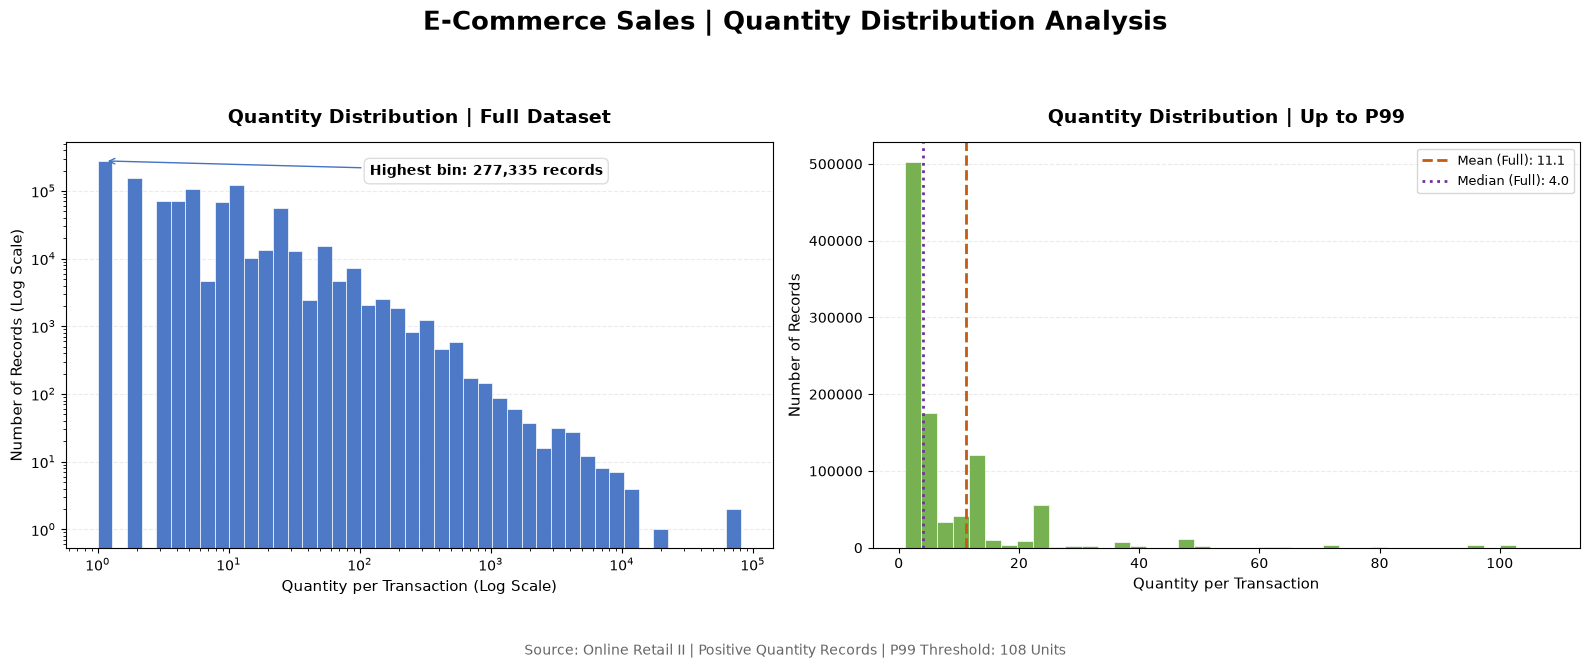


=== Chart Validation ===
Chart saved: images\eda_quantity_distribution_ppt_ready.png
Quantity Distribution Charts: PASS


In [6]:

# ============================================================
# 3. Create improved PPT-ready charts
# Quantity Distribution | Full Dataset vs Up to P99
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. Data Preparation
# ------------------------------------------------------------

assert "sales_df" in globals(), (
    "sales_df is not defined. Run the data preparation cells first."
)

assert "Quantity" in sales_df.columns, (
    "Quantity column is missing from sales_df."
)

# Convert Quantity to numeric
quantity_all = pd.to_numeric(
    sales_df["Quantity"],
    errors="coerce"
).dropna()

# Positive quantities for log-scale analysis
quantity = quantity_all[quantity_all > 0].copy()

assert not quantity.empty, (
    "No positive quantity records available."
)

# ------------------------------------------------------------
# 2. Statistical Benchmarks
# ------------------------------------------------------------

mean_qty = quantity.mean()
median_qty = quantity.median()
p99 = quantity.quantile(0.99)

quantity_99 = quantity[quantity <= p99].copy()

print("=== Quantity Distribution Summary ===")
print(f"Total valid records: {len(quantity_all):,}")
print(f"Positive quantity records: {len(quantity):,}")
print(f"Minimum quantity: {quantity.min():,.0f}")
print(f"Maximum quantity: {quantity.max():,.0f}")
print(f"Mean quantity: {mean_qty:,.2f}")
print(f"Median quantity: {median_qty:,.2f}")
print(f"P99 threshold: {p99:,.2f}")
print(f"Records within P99: {len(quantity_99):,}")

# ------------------------------------------------------------
# 3. Chart Configuration
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

fig.suptitle(
    "E-Commerce Sales | Quantity Distribution Analysis",
    fontsize=19,
    fontweight="bold",
    y=1.04
)

# ------------------------------------------------------------
# 4. Chart A: Full Quantity Distribution
# ------------------------------------------------------------

log_bins = np.logspace(
    np.log10(quantity.min()),
    np.log10(quantity.max()),
    45
)

counts_full, bins_full, patches_full = axes[0].hist(
    quantity,
    bins=log_bins,
    color="#4472C4",
    edgecolor="white",
    linewidth=0.5,
    alpha=0.95
)

axes[0].set_xscale("log")
axes[0].set_yscale("log")

axes[0].set_title(
    "Quantity Distribution | Full Dataset",
    fontsize=14,
    fontweight="bold",
    pad=14
)

axes[0].set_xlabel(
    "Quantity per Transaction (Log Scale)",
    fontsize=11
)

axes[0].set_ylabel(
    "Number of Records (Log Scale)",
    fontsize=11
)

axes[0].grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

axes[0].set_axisbelow(True)

# Highlight highest-frequency bin
max_bin_idx = np.argmax(counts_full)
max_bin_count = int(counts_full[max_bin_idx])
max_bin_center = np.sqrt(
    bins_full[max_bin_idx] * bins_full[max_bin_idx + 1]
)

axes[0].annotate(
    f"Highest bin: {max_bin_count:,} records",
    xy=(max_bin_center, max_bin_count),
    xytext=(0.43, 0.92),
    textcoords="axes fraction",
    fontsize=10,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="->",
        color="#4472C4"
    ),
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="#DDDDDD"
    )
)

# ------------------------------------------------------------
# 5. Chart B: Quantity Distribution up to P99
# ------------------------------------------------------------

counts_99, bins_99, patches_99 = axes[1].hist(
    quantity_99,
    bins=40,
    color="#70AD47",
    edgecolor="white",
    linewidth=0.5,
    alpha=0.95
)

axes[1].set_title(
    "Quantity Distribution | Up to P99",
    fontsize=14,
    fontweight="bold",
    pad=14
)

axes[1].set_xlabel(
    "Quantity per Transaction",
    fontsize=11
)

axes[1].set_ylabel(
    "Number of Records",
    fontsize=11
)

axes[1].grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

axes[1].set_axisbelow(True)

# Statistical reference lines
axes[1].axvline(
    mean_qty,
    color="#C55A11",
    linestyle="--",
    linewidth=2,
    label=f"Mean (Full): {mean_qty:.1f}"
)

axes[1].axvline(
    median_qty,
    color="#7030A0",
    linestyle=":",
    linewidth=2,
    label=f"Median (Full): {median_qty:.1f}"
)

axes[1].legend(
    loc="upper right",
    fontsize=9,
    frameon=True
)

# ------------------------------------------------------------
# 6. Layout and Source Note
# ------------------------------------------------------------

fig.text(
    0.5,
    -0.035,
    (
        "Source: Online Retail II | "
        "Positive Quantity Records | "
        f"P99 Threshold: {p99:,.0f} Units"
    ),
    ha="center",
    fontsize=10,
    color="#666666"
)

plt.tight_layout(rect=[0, 0.04, 1, 0.97])

# ------------------------------------------------------------
# 7. Save Chart
# ------------------------------------------------------------

output_dir = Path("images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir / "eda_quantity_distribution_ppt_ready.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\n=== Chart Validation ===")
print(f"Chart saved: {output_path}")
print("Quantity Distribution Charts: PASS")


### EDA-03-01 | Interpretation

**Key Findings**

- The analysis covers 1,007,913 positive-sales transaction records.
- The mean purchase quantity is 11.12 units, compared with a median of 4 units.
- The distribution is strongly right-skewed, indicating that most transaction lines contain relatively small quantities while a limited number contain substantially larger quantities.
- The 99th percentile is 108 units, highlighting the presence of high-volume transactions in the upper tail.
- Log-scaled visualization reveals transaction patterns that are difficult to observe using a conventional linear-scale histogram.

**Business Implications**

- The median provides a more representative measure of typical transaction-line quantity than the mean.
- High-volume transactions may reflect wholesale purchasing or bulk orders and should be investigated before being classified as outliers.
- Quantity distribution should be considered when evaluating customer purchasing behavior, inventory demand, and product performance.

**Conclusion**

Sales quantities exhibit a pronounced right-skewed distribution. Further outlier assessment is necessary to distinguish potentially valid bulk purchases from unusual transactions.

### EDA-03-02 | Price Distribution Analysis

Analyze the distribution of product unit prices to identify typical price levels, distribution skewness, and unusually high-priced transactions.

The analysis uses the validated positive-sales dataset without removing potential outliers.

,Metric,Value
0,Total Records,1007913.00
1,Mean Unit Price (£),4.07
2,Median Unit Price (£),2.10
3,95th Percentile (£),9.95
4,99th Percentile (£),18.00
5,Maximum Unit Price (£),25111.09
6,Skewness,234.73
7,Records Above P99,9438.00


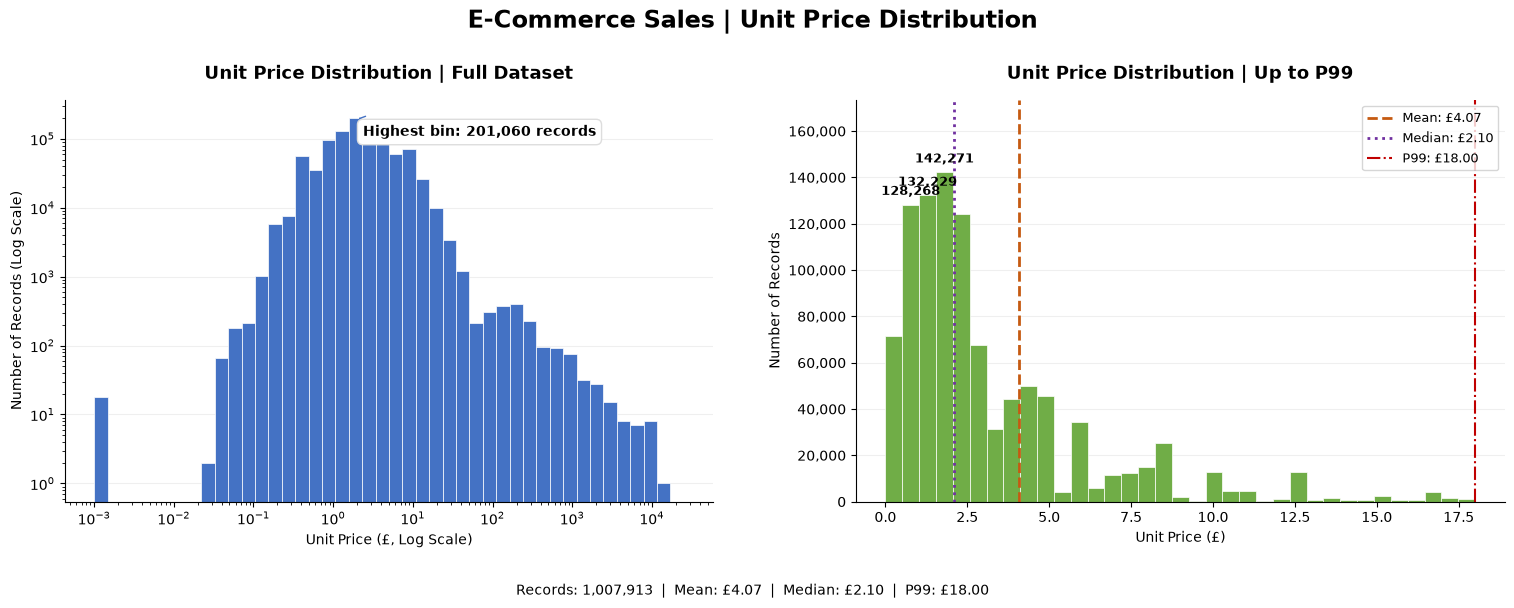

Chart saved: C:\Users\user\OneDrive\Documents\ecommerce-customer_sales-analysis-updated\ecommerce--customer-sales-analysis\images\eda_03_02_price_distribution.png
EDA-03-02 Price Distribution: COMPLETE


In [7]:

# EDA-03-02: Price Distribution Analysis
# PPT-ready charts with data labels

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import FuncFormatter

# 1. Prepare data
price = sales_df["Price"].dropna()

assert (price > 0).all()

mean_price = price.mean()
median_price = price.median()
p95_price = price.quantile(0.95)
p99_price = price.quantile(0.99)
max_price = price.max()

# 2. Summary statistics
price_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Mean Unit Price (£)",
        "Median Unit Price (£)",
        "95th Percentile (£)",
        "99th Percentile (£)",
        "Maximum Unit Price (£)",
        "Skewness",
        "Records Above P99"
    ],
    "Value": [
        len(price),
        round(mean_price, 2),
        round(median_price, 2),
        round(p95_price, 2),
        round(p99_price, 2),
        round(max_price, 2),
        round(price.skew(), 2),
        int((price > p99_price).sum())
    ]
})

display(price_summary)

# 3. Create PPT-ready charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart A: Full distribution with log-scaled bins
log_bins = np.logspace(
    np.log10(price.min()),
    np.log10(price.max()),
    45
)

counts_full, bins_full, patches_full = axes[0].hist(
    price,
    bins=log_bins,
    color="#4472C4",
    edgecolor="white",
    linewidth=0.5
)

axes[0].set_xscale("log")
axes[0].set_yscale("log")

axes[0].set_title(
    "Unit Price Distribution | Full Dataset",
    fontsize=13,
    fontweight="bold",
    pad=15
)
axes[0].set_xlabel("Unit Price (£, Log Scale)")
axes[0].set_ylabel("Number of Records (Log Scale)")

# Annotate the most frequent bin
max_idx = np.argmax(counts_full)

axes[0].annotate(
    f"Highest bin: {int(counts_full[max_idx]):,} records",
    xy=(
        np.sqrt(bins_full[max_idx] * bins_full[max_idx + 1]),
        counts_full[max_idx]
    ),
    xytext=(0.46, 0.91),
    textcoords="axes fraction",
    arrowprops=dict(
        arrowstyle="->",
        color="#4472C4"
    ),
    fontsize=10,
    fontweight="bold",
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="#DDDDDD"
    )
)

# Chart B: Distribution up to P99
price_99 = price[price <= p99_price]

counts_99, bins_99, patches_99 = axes[1].hist(
    price_99,
    bins=35,
    color="#70AD47",
    edgecolor="white",
    linewidth=0.5
)

axes[1].set_title(
    "Unit Price Distribution | Up to P99",
    fontsize=13,
    fontweight="bold",
    pad=15
)
axes[1].set_xlabel("Unit Price (£)")
axes[1].set_ylabel("Number of Records")

axes[1].yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

# Statistical reference lines
axes[1].axvline(
    mean_price,
    color="#C55A11",
    linestyle="--",
    linewidth=2,
    label=f"Mean: £{mean_price:,.2f}"
)

axes[1].axvline(
    median_price,
    color="#7030A0",
    linestyle=":",
    linewidth=2,
    label=f"Median: £{median_price:,.2f}"
)

axes[1].axvline(
    p99_price,
    color="#C00000",
    linestyle="-.",
    linewidth=1.5,
    label=f"P99: £{p99_price:,.2f}"
)

# Add labels to the three highest bins
top_indices = np.argsort(counts_99)[-3:]

for i in top_indices:
    if counts_99[i] <= 0:
        continue

    patch = patches_99[i]
    x = patch.get_x() + patch.get_width() / 2
    y = counts_99[i]

    axes[1].annotate(
        f"{int(y):,}",
        xy=(x, y),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

axes[1].set_ylim(0, max(counts_99) * 1.22)
axes[1].legend(loc="upper right", fontsize=9)

# 4. Styling
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "E-Commerce Sales | Unit Price Distribution",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

fig.text(
    0.5, 0.015,
    f"Records: {len(price):,}  |  "
    f"Mean: £{mean_price:,.2f}  |  "
    f"Median: £{median_price:,.2f}  |  "
    f"P99: £{p99_price:,.2f}",
    ha="center",
    fontsize=10
)

fig.subplots_adjust(
    left=0.07,
    right=0.97,
    top=0.84,
    bottom=0.17,
    wspace=0.22
)

# 5. Save image
output_dir = Path("../images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "eda_03_02_price_distribution.png"

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Chart saved: {output_path.resolve()}")
print("EDA-03-02 Price Distribution: COMPLETE")


### EDA-03-02 | Interpretation

**Key Findings**

- The analysis covers 1,007,913 validated positive-sales transaction records.
- The mean unit price is £4.07, while the median is £2.10, indicating a right-skewed price distribution.
- Transaction records are concentrated in relatively low-price ranges, particularly around £1–£3.
- The 99th percentile is £18.00, meaning approximately 99% of transaction records have unit prices at or below this threshold.
- The log-scaled histogram reveals a long upper tail containing relatively infrequent high-priced transactions.

**Business Implications**

- The median unit price provides a more representative measure of the typical transaction-line price than the mean.
- Low-priced products account for a substantial share of transaction records, but their revenue contribution requires separate evaluation.
- High-priced transactions should be examined alongside purchased quantities before drawing conclusions about revenue concentration.
- Price distribution can support product assortment analysis, pricing segmentation, and further investigation of unusual transactions.

**Conclusion**

The unit price distribution is positively skewed, with transaction records concentrated at lower price points and a relatively small proportion of high-priced transactions. Further sales-value analysis is needed to determine how price and quantity jointly influence revenue.

### EDA-03-03 | Sales Value Distribution Analysis

**Objective**

Analyze transaction-line sales values to understand revenue distribution, identify high-value transaction lines, and evaluate revenue concentration.

**Analytical Approach**

- Calculate descriptive statistics for Sales (Quantity × Price).
- Compare mean, median, and upper percentiles.
- Visualize the full distribution and the distribution up to P99.
- Measure the revenue contribution of transaction lines above the 99th percentile.
- Preserve valid high-value transactions for further outlier assessment.

**Dataset:** Validated Positive Sales Dataset (1,007,913 records)

,Metric,Value
0,Total Sales Records,1007913.00
1,Total Positive Sales Revenue (£),20476260.45
2,Mean Sales Value (£),20.32
3,Median Sales Value (£),10.08
4,95th Percentile (£),60.00
5,99th Percentile (£),184.59
6,Maximum Sales Value (£),168469.60
7,Skewness,608.61
8,Records Above P99,10080.00
9,Revenue Above P99 (£),5013543.35


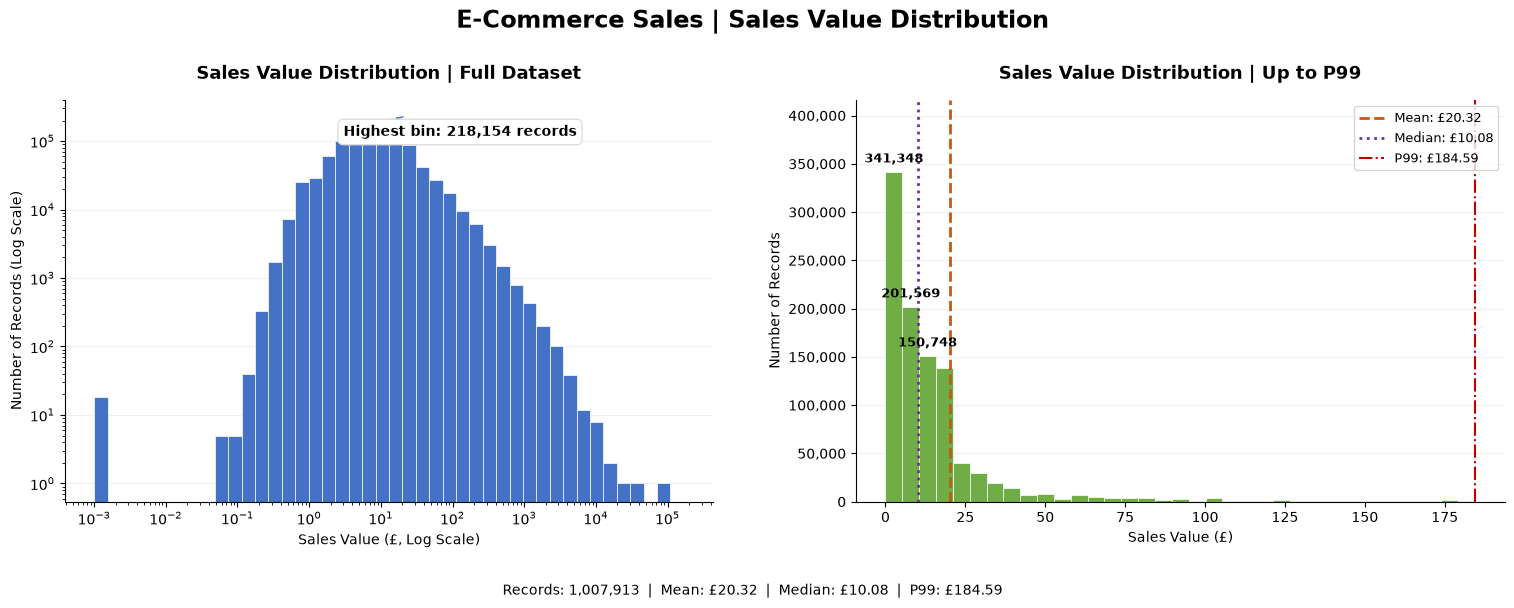

Total Revenue: £20,476,260.45
Records Above P99: 10,080
Revenue Share Above P99: 24.48%
Chart saved: C:\Users\user\OneDrive\Documents\ecommerce-customer_sales-analysis-updated\ecommerce--customer-sales-analysis\images\eda_03_03_sales_value_distribution.png
EDA-03-03 Sales Value Distribution: COMPLETE


In [8]:

# EDA-03-03 | Sales Value Distribution Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import FuncFormatter

# 1. Prepare sales data
sales = sales_df["Sales"].dropna()

assert len(sales) == 1_007_913
assert (sales > 0).all()

# 2. Calculate statistics
mean_sales = sales.mean()
median_sales = sales.median()
p95_sales = sales.quantile(0.95)
p99_sales = sales.quantile(0.99)
max_sales = sales.max()
total_revenue = sales.sum()

# Revenue concentration above P99
high_value_sales = sales[sales > p99_sales]

high_value_count = len(high_value_sales)
high_value_revenue = high_value_sales.sum()

high_value_revenue_share = (
    high_value_revenue / total_revenue * 100
)

# 3. Summary table
sales_summary = pd.DataFrame({
    "Metric": [
        "Total Sales Records",
        "Total Positive Sales Revenue (£)",
        "Mean Sales Value (£)",
        "Median Sales Value (£)",
        "95th Percentile (£)",
        "99th Percentile (£)",
        "Maximum Sales Value (£)",
        "Skewness",
        "Records Above P99",
        "Revenue Above P99 (£)",
        "Revenue Share Above P99 (%)"
    ],
    "Value": [
        len(sales),
        round(total_revenue, 2),
        round(mean_sales, 2),
        round(median_sales, 2),
        round(p95_sales, 2),
        round(p99_sales, 2),
        round(max_sales, 2),
        round(sales.skew(), 2),
        high_value_count,
        round(high_value_revenue, 2),
        round(high_value_revenue_share, 2)
    ]
})

display(sales_summary)

# 4. Create PPT-ready charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart A: Full distribution (log scale)
log_bins = np.logspace(
    np.log10(sales.min()),
    np.log10(sales.max()),
    45
)

counts_full, bins_full, _ = axes[0].hist(
    sales,
    bins=log_bins,
    color="#4472C4",
    edgecolor="white",
    linewidth=0.5
)

axes[0].set_xscale("log")
axes[0].set_yscale("log")

axes[0].set_title(
    "Sales Value Distribution | Full Dataset",
    fontsize=13,
    fontweight="bold",
    pad=15
)

axes[0].set_xlabel("Sales Value (£, Log Scale)")
axes[0].set_ylabel("Number of Records (Log Scale)")

# Label highest-frequency bin
max_idx = np.argmax(counts_full)

axes[0].annotate(
    f"Highest bin: {int(counts_full[max_idx]):,} records",
    xy=(
        np.sqrt(
            bins_full[max_idx] * bins_full[max_idx + 1]
        ),
        counts_full[max_idx]
    ),
    xytext=(0.43, 0.91),
    textcoords="axes fraction",
    arrowprops=dict(
        arrowstyle="->",
        color="#4472C4"
    ),
    fontsize=10,
    fontweight="bold",
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="#DDDDDD"
    )
)

# Chart B: Distribution up to P99
sales_99 = sales[sales <= p99_sales]

counts_99, bins_99, patches_99 = axes[1].hist(
    sales_99,
    bins=35,
    color="#70AD47",
    edgecolor="white",
    linewidth=0.5
)

axes[1].set_title(
    "Sales Value Distribution | Up to P99",
    fontsize=13,
    fontweight="bold",
    pad=15
)

axes[1].set_xlabel("Sales Value (£)")
axes[1].set_ylabel("Number of Records")

axes[1].yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

# Statistical reference lines
axes[1].axvline(
    mean_sales,
    color="#C55A11",
    linestyle="--",
    linewidth=2,
    label=f"Mean: £{mean_sales:,.2f}"
)

axes[1].axvline(
    median_sales,
    color="#7030A0",
    linestyle=":",
    linewidth=2,
    label=f"Median: £{median_sales:,.2f}"
)

axes[1].axvline(
    p99_sales,
    color="#C00000",
    linestyle="-.",
    linewidth=1.5,
    label=f"P99: £{p99_sales:,.2f}"
)

# Label top 3 frequency bins
top_indices = np.argsort(counts_99)[-3:]

for i in top_indices:
    if counts_99[i] <= 0:
        continue

    patch = patches_99[i]
    x = patch.get_x() + patch.get_width() / 2
    y = counts_99[i]

    axes[1].annotate(
        f"{int(y):,}",
        xy=(x, y),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

axes[1].set_ylim(0, max(counts_99) * 1.22)
axes[1].legend(loc="upper right", fontsize=9)

# 5. Chart styling
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "E-Commerce Sales | Sales Value Distribution",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

fig.text(
    0.5, 0.015,
    f"Records: {len(sales):,}  |  "
    f"Mean: £{mean_sales:,.2f}  |  "
    f"Median: £{median_sales:,.2f}  |  "
    f"P99: £{p99_sales:,.2f}",
    ha="center",
    fontsize=10
)

fig.subplots_adjust(
    left=0.07,
    right=0.97,
    top=0.84,
    bottom=0.17,
    wspace=0.22
)

# 6. Save high-resolution image
output_dir = Path("../images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir /
    "eda_03_03_sales_value_distribution.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 7. Final validation
assert np.isclose(total_revenue, 20_476_260.45, atol=0.01)

print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Records Above P99: {high_value_count:,}")
print(
    f"Revenue Share Above P99: "
    f"{high_value_revenue_share:.2f}%"
)
print(f"Chart saved: {output_path.resolve()}")
print("EDA-03-03 Sales Value Distribution: COMPLETE")


### EDA-03-03 | Interpretation

**Key Findings**

- The analysis covers 1,007,913 validated positive-sales transaction records, generating total positive sales revenue of £20,476,260.45.
- The mean transaction-line sales value is £20.32, while the median is £10.08.
- The distribution is strongly right-skewed, indicating that most transaction lines generate relatively small sales values, while a limited number contribute substantially larger amounts.
- The 99th percentile is £184.59, meaning approximately 99% of transaction lines have sales values at or below this threshold.
- The full-distribution chart reveals a long upper tail of high-value transaction lines.

**Business Implications**

- Median sales value provides a more representative measure of typical transaction-line revenue than the mean.
- High-value transaction lines may reflect bulk purchases, high-priced products, or a combination of both.
- Revenue concentration should be assessed by calculating the contribution of transaction lines above the 99th percentile.
- High-value transactions should not automatically be classified as anomalies without additional business-context validation.

**Conclusion**

Transaction-line sales values exhibit a pronounced right-skewed distribution. Further analysis of high-value transactions and their revenue contribution will help distinguish normal purchasing behavior from potentially unusual transactions.

### EDA-03-04 | Outlier Assessment

**Objective**

Identify and assess unusually high values in Quantity, Price, and Sales without automatically excluding potentially valid business transactions.

**Analytical Approach**

- Calculate outlier thresholds using the Interquartile Range (IQR) method.
- Compare IQR-based thresholds with the 99th percentile (P99).
- Measure the number and percentage of records exceeding each threshold.
- Investigate high-value transactions to distinguish potential business events from data quality issues.
- Document outlier handling decisions to ensure analytical transparency.

**Business Rule**

Outliers will be flagged for investigation rather than automatically removed. Valid bulk purchases and high-value transactions will be retained unless there is sufficient evidence of data errors.

In [9]:

# EDA-03-04-01 | Outlier Threshold Assessment

import numpy as np
import pandas as pd

# 1. Select analytical variables
outlier_columns = ["Quantity", "Price", "Sales"]

# 2. Calculate outlier thresholds
outlier_results = []

for col in outlier_columns:

    data = sales_df[col].dropna()

    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1

    iqr_upper = q3 + 1.5 * iqr
    p99 = data.quantile(0.99)

    # IQR outliers
    iqr_outliers = data > iqr_upper

    # P99 outliers
    p99_outliers = data > p99

    outlier_results.append({
        "Variable": col,
        "Total Records": len(data),
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "IQR Upper Bound": round(iqr_upper, 2),
        "P99 Threshold": round(p99, 2),
        "IQR Outlier Count": int(iqr_outliers.sum()),
        "IQR Outlier (%)": round(
            iqr_outliers.mean() * 100, 2
        ),
        "Above P99 Count": int(p99_outliers.sum()),
        "Above P99 (%)": round(
            p99_outliers.mean() * 100, 2
        ),
        "Maximum Value": round(data.max(), 2)
    })

# 3. Create summary table
outlier_summary = pd.DataFrame(outlier_results)

display(
    outlier_summary.set_index("Variable").T
)

# 4. Validation
assert len(sales_df) == 1_007_913
assert (sales_df[outlier_columns] > 0).all().all()
assert outlier_summary["IQR Outlier Count"].ge(0).all()
assert outlier_summary["Above P99 Count"].ge(0).all()

print("EDA-03-04-01 Outlier Threshold Assessment: PASS")


Variable,Quantity,Price,Sales
Total Records,1007913.00,1007913.00,1007913.00
Q1,1.00,1.25,4.13
Q3,12.00,4.13,17.70
IQR,11.00,2.88,13.57
IQR Upper Bound,28.50,8.45,38.06
P99 Threshold,108.00,18.00,184.59
IQR Outlier Count,53061.00,78999.00,84954.00
IQR Outlier (%),5.26,7.84,8.43
Above P99 Count,9801.00,9438.00,10080.00
Above P99 (%),0.97,0.94,1.00


EDA-03-04-01 Outlier Threshold Assessment: PASS


### Statistical Concepts | IQR and P99

**1. Interquartile Range (IQR, 사분위범위)**

IQR measures the spread of the middle 50% of a dataset and is commonly used to identify potential outliers.

- **Q1 (First Quartile, 제1사분위수):** The 25th percentile of the data.
- **Q3 (Third Quartile, 제3사분위수):** The 75th percentile of the data.
- **IQR:** The difference between Q3 and Q1.

**Formula:**

\[
IQR = Q3 - Q1
\]

The conventional upper outlier threshold is calculated as:

\[
Upper\ Bound = Q3 + 1.5 \times IQR
\]

Values exceeding this threshold are flagged as potential outliers, not automatically classified as data errors.

**2. 99th Percentile (P99, 99백분위수)**

P99 represents the value at or below which approximately 99% of observations fall.

- Values above P99 represent approximately the highest 1% of observations.
- P99 is useful for investigating extreme transactions without assuming that they are invalid.
- The actual percentage above P99 may differ slightly from 1% due to repeated values.

**3. Application to This Project**

Both IQR and P99 are applied to Quantity, Price, and Sales to compare outlier detection thresholds.

For example, the Sales variable has:

- Q1: £4.13
- Q3: £17.70
- IQR: £13.57
- IQR Upper Bound: £38.06
- P99 Threshold: £184.59

The IQR method flags 8.43% of Sales records, whereas the P99 threshold identifies approximately 1%.

**Analytical Decision**

Outliers will be investigated rather than automatically removed because extreme values may represent legitimate bulk purchases, wholesale transactions, or high-value customer orders.

In [10]:

# EDA-03-04-02 | High-Value Transaction Investigation

import pandas as pd

# 1. Select columns for investigation
investigation_cols = [
    "Invoice",
    "StockCode",
    "Description",
    "Quantity",
    "Price",
    "Sales",
    "Customer ID",
    "Country"
]

# 2. Top 10 records by each variable
top_quantity = sales_df.nlargest(
    10, "Quantity"
)[investigation_cols].copy()

top_price = sales_df.nlargest(
    10, "Price"
)[investigation_cols].copy()

top_sales = sales_df.nlargest(
    10, "Sales"
)[investigation_cols].copy()

print("=== Top 10 by Quantity ===")
display(top_quantity)

print("=== Top 10 by Unit Price ===")
display(top_price)

print("=== Top 10 by Sales Value ===")
display(top_sales)

# 3. Revenue concentration above Sales P99
sales_p99 = sales_df["Sales"].quantile(0.99)

high_value_records = sales_df[
    sales_df["Sales"] > sales_p99
].copy()

total_revenue = sales_df["Sales"].sum()
high_value_revenue = high_value_records["Sales"].sum()

high_value_share = (
    high_value_revenue / total_revenue * 100
)

# 4. Summary
investigation_summary = pd.DataFrame({
    "Metric": [
        "Total Positive Sales Records",
        "Total Positive Sales Revenue (£)",
        "Sales P99 Threshold (£)",
        "Records Above Sales P99",
        "Revenue Above Sales P99 (£)",
        "Revenue Share Above Sales P99 (%)"
    ],
    "Value": [
        len(sales_df),
        round(total_revenue, 2),
        round(sales_p99, 2),
        len(high_value_records),
        round(high_value_revenue, 2),
        round(high_value_share, 2)
    ]
})

print("=== High-Value Revenue Concentration ===")
display(investigation_summary)

# 5. Validation
assert len(sales_df) == 1_007_913
assert len(high_value_records) == 10_080
assert high_value_share >= 0
assert high_value_share <= 100

print("EDA-03-04-02 Investigation: PASS")


=== Top 10 by Quantity ===


,Invoice,StockCode,Description,Quantity,Price,Sales,Customer ID,Country
1006438,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,16446,United Kingdom
542683,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,12346,United Kingdom
87082,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,1915.2,13902,Denmark
121863,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,1296.0,13902,Denmark
121865,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,1296.0,13902,Denmark
121866,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,0.10,1274.4,13902,Denmark
121864,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.10,1248.0,13902,Denmark
129395,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,0.25,2500.0,17940,United Kingdom
129396,502269,21982,PACK OF 12 SUKI TISSUES,10000,0.25,2500.0,17940,United Kingdom
129397,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,0.25,2500.0,17940,United Kingdom


=== Top 10 by Unit Price ===


,Invoice,StockCode,Description,Quantity,Price,Sales,Customer ID,Country
231523,512771,M,Manual,1,25111.09,25111.09,<NA>,United Kingdom
497490,537632,AMAZONFEE,AMAZON FEE,1,13541.33,13541.33,<NA>,United Kingdom
773540,A563185,B,Adjust bad debt,1,11062.06,11062.06,<NA>,United Kingdom
129382,502263,M,Manual,1,10953.50,10953.50,12918,United Kingdom
129383,502265,M,Manual,1,10953.50,10953.50,<NA>,United Kingdom
328158,522796,M,Manual,1,10468.80,10468.80,<NA>,United Kingdom
344133,524159,M,Manual,1,10468.80,10468.80,14063,United Kingdom
357810,525399,M,Manual,1,10468.80,10468.80,<NA>,United Kingdom
71433,496115,M,Manual,1,8985.60,8985.60,17949,United Kingdom
650643,551697,POST,POSTAGE,1,8142.75,8142.75,16029,United Kingdom


=== Top 10 by Sales Value ===


,Invoice,StockCode,Description,Quantity,Price,Sales,Customer ID,Country
1006438,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,16446,United Kingdom
542683,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,12346,United Kingdom
698499,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,15098,United Kingdom
231523,512771,M,Manual,1,25111.09,25111.09,<NA>,United Kingdom
414827,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,15818.40,15838,United Kingdom
497490,537632,AMAZONFEE,AMAZON FEE,1,13541.33,13541.33,<NA>,United Kingdom
773540,A563185,B,Adjust bad debt,1,11062.06,11062.06,<NA>,United Kingdom
129382,502263,M,Manual,1,10953.50,10953.50,12918,United Kingdom
129383,502265,M,Manual,1,10953.50,10953.50,<NA>,United Kingdom
328158,522796,M,Manual,1,10468.80,10468.80,<NA>,United Kingdom


=== High-Value Revenue Concentration ===


,Metric,Value
0,Total Positive Sales Records,1007913.00
1,Total Positive Sales Revenue (£),20476260.45
2,Sales P99 Threshold (£),184.59
3,Records Above Sales P99,10080.00
4,Revenue Above Sales P99 (£),5013543.35
5,Revenue Share Above Sales P99 (%),24.48


EDA-03-04-02 Investigation: PASS


### EDA-03-04-02 | Interpretation

**Key Findings**

- The top 1% of transaction lines, consisting of 10,080 records above the Sales P99 threshold (£184.59), contributed £5,013,543.35, representing 24.48% of total positive sales revenue.
- Extremely high quantities were observed in several identifiable product transactions, suggesting potential bulk or wholesale purchasing activity.
- High-value records also included non-standard entries such as Manual (M), AMAZON FEE (AMAZONFEE), Adjust bad debt (B), and POSTAGE (POST).
- These findings indicate that statistical outliers may represent different types of business activity rather than a single category of data errors.

**Business Implications**

- Legitimate high-volume product transactions should generally be retained to preserve revenue and purchasing behavior information.
- Accounting adjustments, platform fees, and shipping-related records require separate classification before product sales performance analysis.
- The current revenue concentration figure should be treated as provisional until non-product transaction types are assessed.
- Statistical thresholds alone are insufficient to distinguish valid product sales from operational or accounting entries.

**Conclusion**

High-value transaction investigation reveals a combination of potential wholesale purchases and non-standard business records. Transaction-type validation is necessary before finalizing outlier treatment and revenue analysis.

In [11]:

# EDA-03-04-03 | Special Transaction Code Assessment

special_codes = ["M", "AMAZONFEE", "B", "POST"]

special_records = sales_df[
    sales_df["StockCode"].astype(str).str.upper().isin(special_codes)
].copy()

special_summary = (
    special_records
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Records=("Sales", "size"),
        Total_Sales=("Sales", "sum"),
        Unique_Invoices=("Invoice", "nunique")
    )
    .reset_index()
    .sort_values("Total_Sales", ascending=False)
)

special_summary["Revenue_Share_Pct"] = (
    special_summary["Total_Sales"]
    / sales_df["Sales"].sum()
    * 100
).round(4)

print("=== Special Transaction Code Summary ===")
display(special_summary)

print("\n=== Overall Impact ===")
print(f"Special Records: {len(special_records):,}")
print(f"Special Sales Value: £{special_records['Sales'].sum():,.2f}")
print(
    "Share of Total Positive Sales: "
    f"{special_records['Sales'].sum() / sales_df['Sales'].sum() * 100:.2f}%"
)

# Validation
assert len(special_records) <= len(sales_df)
assert special_records["Sales"].gt(0).all()

print("\nEDA-03-04-03 Special Code Assessment: PASS")


=== Special Transaction Code Summary ===


,StockCode,Description,Records,Total_Sales,Unique_Invoices,Revenue_Share_Pct
2,M,Manual,846,339226.24,784,1.6567
3,POST,POSTAGE,1851,125682.42,1851,0.6138
0,AMAZONFEE,AMAZON FEE,3,20467.80,3,0.1000
1,B,Adjust bad debt,1,11062.06,1,0.0540
4,m,Manual,5,15.05,4,0.0001



=== Overall Impact ===
Special Records: 2,706
Special Sales Value: £496,453.57
Share of Total Positive Sales: 2.42%

EDA-03-04-03 Special Code Assessment: PASS


### EDA-03-04-03 | Interpretation

**Key Findings**

- A total of 2,706 records were identified under four special transaction code categories, including case variations of Manual (M/m).
- These records represent £496,453.57, accounting for 2.42% of total positive sales value.
- Manual entries contributed the largest share, followed by postage, Amazon fees, and bad debt adjustments.
- The relatively small number of special records has a disproportionate impact on the reported positive sales value.

**Business Implications**

- Positive Quantity and Price values alone do not guarantee that a transaction represents a product sale.
- Shipping fees, platform charges, and accounting adjustments should be distinguished from merchandise revenue.
- Manual transactions require further validation before being classified as product or non-product transactions.
- Legitimate bulk purchases should be retained even when they exceed statistical outlier thresholds.

**Outlier Handling Decision**

- **Retain:** Valid product transactions, including legitimate high-volume and high-value purchases.
- **Separate:** Identified operational and accounting-related records for dedicated analysis.
- **Review:** Manual transactions and other ambiguous transaction types.
- **Preserve:** The original positive-sales dataset for traceability and comparison.

**Conclusion**

The assessment indicates that transaction classification is more appropriate than automatic statistical outlier removal. Further validation is required before creating a product-sales-only analytical dataset.

In [12]:

# EDA-03-04-04 | Additional Special Code Discovery

# Identify stock codes containing alphabetic characters
code_series = sales_df["StockCode"].astype("string").str.upper()

alpha_code_mask = code_series.str.contains(
    r"[A-Z]", regex=True, na=False
)

alpha_records = sales_df.loc[alpha_code_mask].copy()

# Summarize by StockCode and Description
alpha_summary = (
    alpha_records
    .groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Records=("Sales", "size"),
        Total_Sales=("Sales", "sum")
    )
    .reset_index()
    .sort_values("Total_Sales", ascending=False)
)

print("=== Alphabetic StockCode Investigation ===")
display(alpha_summary.head(30))

print("\n=== Summary ===")
print(f"Records with alphabetic StockCodes: {len(alpha_records):,}")
print(f"Unique StockCodes: {alpha_records['StockCode'].nunique():,}")
print(f"Sales Value: £{alpha_records['Sales'].sum():,.2f}")

print("\nEDA-03-04-04 Discovery: PASS")


=== Alphabetic StockCode Investigation ===


,StockCode,Description,Records,Total_Sales
1629,M,Manual,846,339226.24
1628,DOT,DOTCOM POSTAGE,1415,309854.11
1171,85123A,WHITE HANGING HEART T-LIGHT HOLDER,5502,257546.20
1153,85099B,JUMBO BAG RED RETROSPOT,3287,145961.83
1631,POST,POSTAGE,1851,125682.42
1157,85099F,JUMBO BAG STRAWBERRY,1850,67985.77
1156,85099C,JUMBO BAG BAROQUE BLACK WHITE,1891,59057.61
10,15056N,EDWARDIAN PARASOL NATURAL,1040,57975.45
9,15056BL,EDWARDIAN PARASOL BLACK,869,47267.45
627,84078A,SET/4 WHITE RETRO STORAGE CUBES,328,43844.96



=== Summary ===
Records with alphabetic StockCodes: 125,868
Unique StockCodes: 1,526
Sales Value: £3,200,131.15

EDA-03-04-04 Discovery: PASS


### EDA-03-04-04 | Interpretation

**Key Findings**

- A total of 125,868 records contained alphabetic characters in their StockCodes, representing approximately 12.49% of positive-sales records.
- These records represented £3,200,131.15, or approximately 15.63% of total positive sales value.
- Many alphabetic StockCodes, such as 85123A and 85099B, corresponded to identifiable retail products.
- DOT (DOTCOM POSTAGE) was identified as an additional shipping-related transaction category, contributing £309,854.11.
- Alphabetic characters in StockCodes are therefore insufficient to distinguish merchandise from non-merchandise transactions.

**Business Implications**

- StockCode format should not be used as an automatic exclusion criterion.
- Transaction classification should consider both StockCode and Description.
- Shipping charges, platform fees, and accounting adjustments require separate treatment from merchandise sales.
- Manual entries should remain under review until their business meaning is confirmed.

**Conclusion**

The investigation supports a business-rule-based transaction classification approach rather than automatic exclusion based on StockCode patterns or statistical outlier thresholds.

In [13]:

# EDA-03-04-05 | Transaction Classification Validation

import numpy as np
import pandas as pd

# 1. Normalize StockCode
stock_code = (
    sales_df["StockCode"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# 2. Define provisional business categories
conditions = [
    stock_code.isin(["POST", "DOT"]).fillna(False),
    stock_code.eq("AMAZONFEE").fillna(False),
    stock_code.eq("B").fillna(False),
    stock_code.eq("M").fillna(False)
]

categories = [
    "Shipping",
    "Platform Fee",
    "Accounting Adjustment",
    "Manual Review"
]

# 3. Create a separate classified dataset
sales_classified = sales_df.copy()

sales_classified["Transaction_Type"] = np.select(
    conditions,
    categories,
    default="Other / Unreviewed"
)

# 4. Classification summary
classification_summary = (
    sales_classified
    .groupby("Transaction_Type")
    .agg(
        Records=("Sales", "size"),
        Sales_Value=("Sales", "sum")
    )
    .reset_index()
)

classification_summary["Record_Share_Pct"] = (
    classification_summary["Records"]
    / len(sales_classified) * 100
).round(2)

classification_summary["Sales_Share_Pct"] = (
    classification_summary["Sales_Value"]
    / sales_classified["Sales"].sum() * 100
).round(2)

classification_summary["Sales_Value"] = (
    classification_summary["Sales_Value"].round(2)
)

print("=== Transaction Classification Summary ===")
display(classification_summary)

# 5. Validation
assert len(sales_classified) == len(sales_df)
assert classification_summary["Records"].sum() == len(sales_df)
assert np.isclose(
    classification_summary["Sales_Value"].sum(),
    sales_df["Sales"].sum(),
    atol=0.05
)

print("\nEDA-03-04-05 Classification Validation: PASS")


=== Transaction Classification Summary ===


,Transaction_Type,Records,Sales_Value,Record_Share_Pct,Sales_Share_Pct
0,Accounting Adjustment,1,11062.06,0.00,0.05
1,Manual Review,851,339241.29,0.08,1.66
2,Other / Unreviewed,1003792,19669952.77,99.59,96.06
3,Platform Fee,3,20467.80,0.00,0.10
4,Shipping,3266,435536.53,0.32,2.13



EDA-03-04-05 Classification Validation: PASS


### EDA-03-04-05 | Interpretation

**Key Findings**

- All 1,007,913 positive-sales records were successfully assigned to provisional transaction categories.
- Shipping-related transactions accounted for 3,266 records and £435,536.53.
- Manual entries accounted for 851 records and £339,241.29.
- Platform fees and accounting adjustments represented smaller but identifiable non-merchandise categories.
- The remaining 1,003,792 records, representing 96.06% of positive sales value, were classified as Other / Unreviewed.

**Business Implications**

- Positive sales values include both merchandise-related and operational transactions.
- Shipping fees and accounting-related entries should be separately reported when evaluating merchandise revenue.
- Manual entries require further investigation before a final inclusion or exclusion decision.
- The Other / Unreviewed category should not automatically be interpreted as verified merchandise sales.

**Outlier Handling Decision**

- **Retain:** Potentially legitimate bulk purchases and high-value product transactions.
- **Separate:** Identified shipping, platform fee, and accounting adjustment records.
- **Review:** Manual entries and other ambiguous transaction types.
- **Preserve:** The original positive-sales dataset without modifying its underlying records.

**Conclusion**

Transaction classification provides a more business-relevant approach to handling extreme values than automatic statistical outlier removal. The classification results establish a preliminary framework for merchandise-focused analysis while preserving the original dataset for auditability.

In [14]:

# EDA-03-04-06 | Final Outlier Handling Summary

import pandas as pd
import numpy as np

# 1. Outlier Threshold Summary
final_outlier_summary = outlier_summary[
    [
        "Variable",
        "IQR Upper Bound",
        "P99 Threshold",
        "IQR Outlier Count",
        "IQR Outlier (%)",
        "Above P99 Count",
        "Above P99 (%)"
    ]
].copy()

print("=== 1. Outlier Threshold Summary ===")
display(final_outlier_summary)


# 2. Revenue Concentration Summary
sales_p99 = sales_df["Sales"].quantile(0.99)

p99_records = sales_df[
    sales_df["Sales"] > sales_p99
]

revenue_concentration = pd.DataFrame({
    "Metric": [
        "Total Positive Sales Records",
        "Total Positive Sales Revenue (£)",
        "Sales P99 Threshold (£)",
        "Records Above Sales P99",
        "Revenue Above Sales P99 (£)",
        "Revenue Share Above P99 (%)"
    ],
    "Value": [
        len(sales_df),
        round(sales_df["Sales"].sum(), 2),
        round(sales_p99, 2),
        len(p99_records),
        round(p99_records["Sales"].sum(), 2),
        round(
            p99_records["Sales"].sum()
            / sales_df["Sales"].sum() * 100, 2
        )
    ]
})

print("\n=== 2. Revenue Concentration Summary ===")
display(revenue_concentration)


# 3. Transaction Classification Summary
final_classification_summary = (
    sales_classified
    .groupby("Transaction_Type")
    .agg(
        Records=("Sales", "size"),
        Sales_Value=("Sales", "sum")
    )
    .reset_index()
)

final_classification_summary["Sales_Share_Pct"] = (
    final_classification_summary["Sales_Value"]
    / sales_df["Sales"].sum() * 100
).round(2)

final_classification_summary["Sales_Value"] = (
    final_classification_summary["Sales_Value"].round(2)
)

print("\n=== 3. Transaction Classification Summary ===")
display(final_classification_summary)


# 4. Outlier Handling Decision Table
handling_decisions = pd.DataFrame({
    "Transaction Category": [
        "Potentially Valid Merchandise",
        "Shipping",
        "Platform Fee",
        "Accounting Adjustment",
        "Manual Entry",
        "Other Unreviewed Records"
    ],
    "Decision": [
        "RETAIN",
        "SEPARATE",
        "SEPARATE",
        "SEPARATE",
        "REVIEW",
        "REVIEW"
    ],
    "Rationale": [
        "Preserve potentially legitimate product sales",
        "Report shipping separately from merchandise",
        "Separate platform-related charges",
        "Separate accounting-related adjustments",
        "Verify business purpose before final treatment",
        "Requires further classification before confirmation"
    ]
})

print("\n=== 4. Outlier Handling Decision Table ===")
display(handling_decisions)


# 5. Final Data Preservation Validation
original_records = len(sales_df)
classified_records = len(sales_classified)

original_revenue = sales_df["Sales"].sum()
classified_revenue = sales_classified["Sales"].sum()

assert original_records == classified_records
assert np.isclose(
    original_revenue,
    classified_revenue,
    rtol=0,
    atol=0.01
)

assert (
    final_classification_summary["Records"].sum()
    == original_records
)

assert np.isclose(
    final_classification_summary["Sales_Value"].sum(),
    original_revenue,
    rtol=0,
    atol=0.05
)

print("\n=== 5. Final Validation ===")
print(f"Original Records: {original_records:,}")
print(f"Classified Records: {classified_records:,}")
print(f"Original Revenue: £{original_revenue:,.2f}")
print(f"Classified Revenue: £{classified_revenue:,.2f}")

print("\nEDA-03-04-06 Final Outlier Assessment: PASS")


=== 1. Outlier Threshold Summary ===


,Variable,IQR Upper Bound,P99 Threshold,IQR Outlier Count,IQR Outlier (%),Above P99 Count,Above P99 (%)
0,Quantity,28.50,108.00,53061,5.26,9801,0.97
1,Price,8.45,18.00,78999,7.84,9438,0.94
2,Sales,38.06,184.59,84954,8.43,10080,1.00



=== 2. Revenue Concentration Summary ===


,Metric,Value
0,Total Positive Sales Records,1007913.00
1,Total Positive Sales Revenue (£),20476260.45
2,Sales P99 Threshold (£),184.59
3,Records Above Sales P99,10080.00
4,Revenue Above Sales P99 (£),5013543.35
5,Revenue Share Above P99 (%),24.48



=== 3. Transaction Classification Summary ===


,Transaction_Type,Records,Sales_Value,Sales_Share_Pct
0,Accounting Adjustment,1,11062.06,0.05
1,Manual Review,851,339241.29,1.66
2,Other / Unreviewed,1003792,19669952.77,96.06
3,Platform Fee,3,20467.80,0.10
4,Shipping,3266,435536.53,2.13



=== 4. Outlier Handling Decision Table ===


,Transaction Category,Decision,Rationale
0,Potentially Valid Merchandise,RETAIN,Preserve potentially legitimate product sales
1,Shipping,SEPARATE,Report shipping separately from merchandise
2,Platform Fee,SEPARATE,Separate platform-related charges
3,Accounting Adjustment,SEPARATE,Separate accounting-related adjustments
4,Manual Entry,REVIEW,Verify business purpose before final treatment
5,Other Unreviewed Records,REVIEW,Requires further classification before confirm...



=== 5. Final Validation ===
Original Records: 1,007,913
Classified Records: 1,007,913
Original Revenue: £20,476,260.45
Classified Revenue: £20,476,260.45

EDA-03-04-06 Final Outlier Assessment: PASS


### EDA-03-04-06 | Interpretation

**Key Findings**

- **Outlier Detection:** IQR-based outlier rates were 5.26% for Quantity, 7.84% for Price, and 8.43% for Sales.
- **Revenue Concentration:** The 10,080 transactions above the Sales P99 threshold (£184.59) contributed £5,013,543.35, representing 24.48% of total positive sales revenue.
- **Transaction Classification:** Shipping accounted for 2.13% of revenue, Manual Review for 1.66%, Platform Fee for 0.10%, and Accounting Adjustment for 0.05%.
- **Classification Limitation:** Other / Unreviewed transactions accounted for 96.06% of revenue and should not be considered fully validated merchandise sales.
- **Data Integrity:** All 1,007,913 records and £20,476,260.45 in positive sales revenue were preserved after classification.

**Outlier Handling Decisions**

- **RETAIN:** Potentially legitimate high-value merchandise transactions should not be removed solely because they exceed statistical thresholds.
- **SEPARATE:** Shipping, platform fees, and accounting adjustments should be distinguished from merchandise sales.
- **REVIEW:** Manual entries and unreviewed transactions require additional business-rule validation before final classification.

**Business Implications**

The results indicate substantial revenue concentration among high-value transactions. Statistical outliers may represent legitimate wholesale orders or special business transactions rather than data errors.

For subsequent sales performance analysis, Positive Sales Revenue should be distinguished from Merchandise Sales Revenue to avoid overstating product-related sales.

**Final Assessment: PASS**

The outlier assessment and transaction classification reconciliation were completed successfully. No records or revenue were lost during classification. Further transaction-level review is required before finalizing merchandise-only revenue.

## EDA-03-05 | Merchandise Sales Dataset Preparation

### Objective

Prepare a merchandise sales dataset for subsequent sales performance analysis by separating identifiable non-merchandise transactions from positive sales records.

The analysis will preserve the original Positive Sales Dataset while applying transparent business rules to create a provisional Merchandise Sales Dataset.

### EDA-03-05-01 | Transaction Classification Review

**Classification Principles**

- **Merchandise Candidates:** Retain transactions not identified as special non-merchandise records, subject to further validation.
- **Shipping:** Separate shipping and postage charges from merchandise revenue.
- **Platform Fees:** Separate platform-related fees.
- **Accounting Adjustments:** Exclude identifiable accounting adjustments from merchandise revenue.
- **Manual Review:** Keep manual entries separate until their business purpose is verified.

**Validation Requirements**

- Preserve all original records.
- Ensure that each transaction belongs to exactly one classification category.
- Reconcile total record counts and revenue.
- Clearly distinguish provisional merchandise revenue from validated merchandise revenue.

In [15]:

# EDA-03-05-01 | Transaction Classification Review

classification_review = (
    sales_classified
    .groupby("Transaction_Type", dropna=False)
    .agg(
        Records=("Sales", "size"),
        Revenue=("Sales", "sum")
    )
    .reset_index()
)

classification_review["Record_Share_Pct"] = (
    classification_review["Records"]
    / len(sales_classified) * 100
).round(2)

classification_review["Revenue_Share_Pct"] = (
    classification_review["Revenue"]
    / sales_classified["Sales"].sum() * 100
).round(2)

classification_review["Revenue"] = (
    classification_review["Revenue"].round(2)
)

display(
    classification_review.sort_values(
        "Revenue", ascending=False
    )
)

# Validation
assert len(sales_classified) == len(sales_df)
assert sales_classified["Transaction_Type"].notna().all()

print("\nEDA-03-05-01 Classification Review: PASS")


,Transaction_Type,Records,Revenue,Record_Share_Pct,Revenue_Share_Pct
2,Other / Unreviewed,1003792,19669952.77,99.59,96.06
4,Shipping,3266,435536.53,0.32,2.13
1,Manual Review,851,339241.29,0.08,1.66
3,Platform Fee,3,20467.80,0.00,0.10
0,Accounting Adjustment,1,11062.06,0.00,0.05



EDA-03-05-01 Classification Review: PASS


In [16]:

# EDA-03-05-02 | Provisional Merchandise Sales Dataset

import numpy as np
import pandas as pd

# 1. Preserve original classified dataset
merchandise_sales_df = sales_classified.loc[
    sales_classified["Transaction_Type"] == "Other / Unreviewed"
].copy()

# 2. Separate special transactions
excluded_sales_df = sales_classified.loc[
    sales_classified["Transaction_Type"] != "Other / Unreviewed"
].copy()

# 3. Dataset comparison
dataset_comparison = pd.DataFrame({
    "Dataset": [
        "Positive Sales",
        "Provisional Merchandise Sales",
        "Separated Special Transactions"
    ],
    "Records": [
        len(sales_df),
        len(merchandise_sales_df),
        len(excluded_sales_df)
    ],
    "Revenue_GBP": [
        sales_df["Sales"].sum(),
        merchandise_sales_df["Sales"].sum(),
        excluded_sales_df["Sales"].sum()
    ]
})

dataset_comparison["Record_Share_Pct"] = (
    dataset_comparison["Records"]
    / len(sales_df) * 100
).round(2)

dataset_comparison["Revenue_Share_Pct"] = (
    dataset_comparison["Revenue_GBP"]
    / sales_df["Sales"].sum() * 100
).round(2)

dataset_comparison["Revenue_GBP"] = (
    dataset_comparison["Revenue_GBP"].round(2)
)

print("=== Dataset Comparison ===")
display(dataset_comparison)

# 4. Data integrity validation
assert (
    len(merchandise_sales_df) + len(excluded_sales_df)
    == len(sales_df)
)

assert np.isclose(
    merchandise_sales_df["Sales"].sum()
    + excluded_sales_df["Sales"].sum(),
    sales_df["Sales"].sum(),
    rtol=0,
    atol=0.01
)

assert merchandise_sales_df["Transaction_Type"].eq(
    "Other / Unreviewed"
).all()

print("\nEDA-03-05-02 Dataset Creation: PASS")


=== Dataset Comparison ===


,Dataset,Records,Revenue_GBP,Record_Share_Pct,Revenue_Share_Pct
0,Positive Sales,1007913,20476260.45,100.00,100.00
1,Provisional Merchandise Sales,1003792,19669952.77,99.59,96.06
2,Separated Special Transactions,4121,806307.68,0.41,3.94



EDA-03-05-02 Dataset Creation: PASS


=== Revenue Impact Summary ===


,Metric,Value
0,Positive Sales Revenue,20476260.45
1,Provisional Merchandise Revenue,19669952.77
2,Separated Special Transaction Value,806307.68
3,Revenue Difference (%),3.94


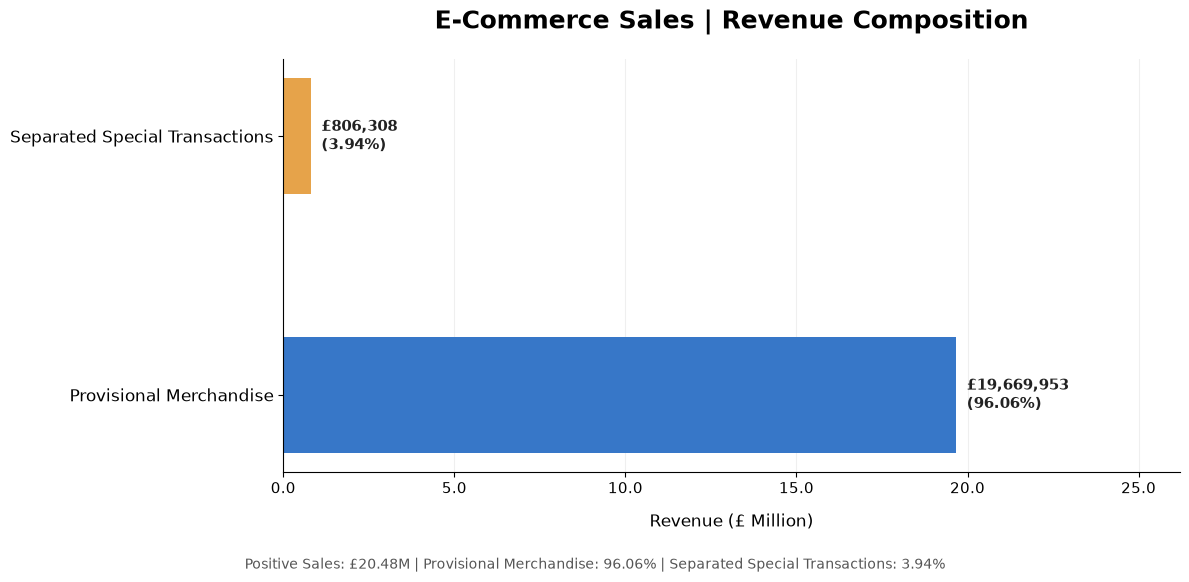


Chart saved: ..\images\eda_03_05_revenue_composition.png

EDA-03-05-03 Revenue Impact Analysis: PASS


In [17]:


# EDA-03-05-03 | Revenue Impact Analysis
# Revised Version: PPT-ready chart with GBP Million axis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path

# --------------------------------------------------
# 1. Revenue Impact Summary
# --------------------------------------------------

positive_revenue = sales_df["Sales"].sum()
provisional_revenue = merchandise_sales_df["Sales"].sum()
separated_revenue = excluded_sales_df["Sales"].sum()

revenue_impact = pd.DataFrame({
    "Metric": [
        "Positive Sales Revenue",
        "Provisional Merchandise Revenue",
        "Separated Special Transaction Value",
        "Revenue Difference (%)"
    ],
    "Value": [
        round(positive_revenue, 2),
        round(provisional_revenue, 2),
        round(separated_revenue, 2),
        round(separated_revenue / positive_revenue * 100, 2)
    ]
})

print("=== Revenue Impact Summary ===")
display(revenue_impact)


# --------------------------------------------------
# 2. Revenue Composition Chart
# --------------------------------------------------

categories = [
    "Provisional Merchandise",
    "Separated Special Transactions"
]

values = [
    provisional_revenue,
    separated_revenue
]

colors = ["#3777C8", "#E6A34A"]

fig, ax = plt.subplots(figsize=(12, 5.8))

bars = ax.barh(
    categories,
    values,
    color=colors,
    height=0.45
)

# Data labels: Revenue and Percentage
for bar, value in zip(bars, values):

    revenue_label = f"£{value:,.0f}"
    percentage_label = (
        f"{value / positive_revenue * 100:.2f}%"
    )

    ax.text(
        bar.get_width() + positive_revenue * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{revenue_label}\n({percentage_label})",
        va="center",
        ha="left",
        fontsize=11,
        fontweight="bold",
        color="#222222"
    )

# --------------------------------------------------
# 3. Axis Formatting
# --------------------------------------------------

ax.set_xlim(
    0,
    positive_revenue * 1.28
)

# Convert axis values to GBP Million
ax.xaxis.set_major_formatter(
    FuncFormatter(
        lambda x, pos: f"{x / 1_000_000:.1f}"
    )
)

ax.set_xlabel(
    "Revenue (£ Million)",
    fontsize=12,
    labelpad=12
)

ax.tick_params(
    axis="x",
    labelsize=11
)

ax.tick_params(
    axis="y",
    labelsize=12
)

# --------------------------------------------------
# 4. Chart Styling
# --------------------------------------------------

ax.set_title(
    "E-Commerce Sales | Revenue Composition",
    fontsize=18,
    fontweight="bold",
    pad=22
)

ax.grid(
    axis="x",
    linestyle="-",
    alpha=0.20
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Add summary note
fig.text(
    0.5,
    0.01,
    "Positive Sales: £20.48M | "
    "Provisional Merchandise: 96.06% | "
    "Separated Special Transactions: 3.94%",
    ha="center",
    fontsize=10,
    color="#555555"
)

plt.tight_layout(
    rect=[0, 0.05, 1, 1]
)


# --------------------------------------------------
# 5. Save Chart for PPT
# --------------------------------------------------

output_dir = Path("../images")
output_dir.mkdir(
    parents=True,
    exist_ok=True
)

chart_path = (
    output_dir /
    "eda_03_05_revenue_composition.png"
)

plt.savefig(
    chart_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"\nChart saved: {chart_path}")


# --------------------------------------------------
# 6. Revenue Reconciliation Validation
# --------------------------------------------------

assert np.isclose(
    provisional_revenue + separated_revenue,
    positive_revenue,
    rtol=0,
    atol=0.01
)

assert (
    len(merchandise_sales_df)
    + len(excluded_sales_df)
    == len(sales_df)
)

print(
    "\nEDA-03-05-03 Revenue Impact Analysis: PASS"
)


In [18]:

# EDA-03-05-04 | Data Integrity Validation

import pandas as pd
import numpy as np

# 1. Record Reconciliation
record_check = (
    len(merchandise_sales_df)
    + len(excluded_sales_df)
    == len(sales_df)
)

# 2. Revenue Reconciliation
revenue_check = np.isclose(
    merchandise_sales_df["Sales"].sum()
    + excluded_sales_df["Sales"].sum(),
    sales_df["Sales"].sum(),
    rtol=0,
    atol=0.01
)

# 3. Dataset Partition Validation
overlap_count = len(
    merchandise_sales_df.index.intersection(
        excluded_sales_df.index
    )
)

partition_check = (
    overlap_count == 0
    and merchandise_sales_df.index.is_unique
    and excluded_sales_df.index.is_unique
    and sales_classified.index.is_unique
)

# 4. Positive Quantity and Price
quantity_check = (
    merchandise_sales_df["Quantity"] > 0
).all()

price_check = (
    merchandise_sales_df["Price"] > 0
).all()

# 5. Sales Calculation Validation
sales_check = np.isclose(
    merchandise_sales_df["Sales"],
    merchandise_sales_df["Quantity"]
    * merchandise_sales_df["Price"],
    rtol=1e-9,
    atol=0.01
).all()

# 6. Customer ID Completeness
missing_customer_ids = (
    merchandise_sales_df["Customer ID"].isna().sum()
)

missing_customer_pct = (
    missing_customer_ids
    / len(merchandise_sales_df) * 100
)

# 7. Validation Summary
validation_results = pd.DataFrame({
    "Validation": [
        "Record Reconciliation",
        "Revenue Reconciliation",
        "Dataset Partition",
        "Positive Quantity",
        "Positive Price",
        "Sales Calculation"
    ],
    "Status": [
        record_check,
        revenue_check,
        partition_check,
        quantity_check,
        price_check,
        sales_check
    ]
})

validation_results["Result"] = (
    validation_results["Status"]
    .map({True: "PASS", False: "FAIL"})
)

print("=== Data Integrity Validation ===")
display(validation_results[["Validation", "Result"]])

print("\n=== Customer ID Completeness ===")
print(f"Missing Customer IDs: {missing_customer_ids:,}")
print(f"Missing Customer ID Rate: {missing_customer_pct:.2f}%")
print(f"Overlapping Records: {overlap_count:,}")

assert validation_results["Status"].all(), (
    "EDA-03-05-04: One or more validations failed."
)

print("\nEDA-03-05-04 Data Integrity Validation: PASS")


=== Data Integrity Validation ===


,Validation,Result
0,Record Reconciliation,PASS
1,Revenue Reconciliation,PASS
2,Dataset Partition,PASS
3,Positive Quantity,PASS
4,Positive Price,PASS
5,Sales Calculation,PASS



=== Customer ID Completeness ===
Missing Customer IDs: 226,867
Missing Customer ID Rate: 22.60%
Overlapping Records: 0

EDA-03-05-04 Data Integrity Validation: PASS


### EDA-03-05-04 | Interpretation

**Key Findings**

- All six data integrity validation checks passed successfully.
- Record and revenue reconciliation confirmed consistency between the original positive-sales dataset and the separated datasets.
- No overlapping records were detected between the merchandise and special transaction datasets.
- All merchandise records contain positive quantities and unit prices, and their Sales values match the calculated transaction values.
- A total of **226,867 records (22.60%)** have missing Customer IDs.

**Analytical Implications**

- The separated datasets maintain numerical consistency with the original positive-sales dataset.
- The provisional merchandise dataset can be used for subsequent exploratory analysis, subject to further review of unclassified transactions.
- Customer-level analyses, including RFM segmentation, should exclude records with missing Customer IDs.
- Special transactions should remain separately identifiable to avoid mixing merchandise revenue with shipping fees, platform charges, and accounting adjustments.

**Conclusion**

EDA-03-05-04 Data Integrity Validation: **PASS**

The dataset reconciliation and integrity checks were completed successfully.

In [19]:

# EDA-03-05-05 | Final Dataset Summary & Readiness Assessment

import pandas as pd
import numpy as np

# 1. Dataset Summary
final_dataset_summary = pd.DataFrame({
    "Dataset": [
        "Positive Sales",
        "Provisional Merchandise",
        "Separated Special Transactions"
    ],
    "Records": [
        len(sales_df),
        len(merchandise_sales_df),
        len(excluded_sales_df)
    ],
    "Revenue_GBP": [
        sales_df["Sales"].sum(),
        merchandise_sales_df["Sales"].sum(),
        excluded_sales_df["Sales"].sum()
    ]
})

total_records = len(sales_df)
total_revenue = sales_df["Sales"].sum()

final_dataset_summary["Record_Share_Pct"] = (
    final_dataset_summary["Records"]
    / total_records * 100
).round(2)

final_dataset_summary["Revenue_Share_Pct"] = (
    final_dataset_summary["Revenue_GBP"]
    / total_revenue * 100
).round(2)

print("=== 1. Final Dataset Summary ===")
display(
    final_dataset_summary.style.format({
        "Records": "{:,.0f}",
        "Revenue_GBP": "£{:,.2f}",
        "Record_Share_Pct": "{:.2f}%",
        "Revenue_Share_Pct": "{:.2f}%"
    })
)

# 2. Customer ID Readiness
customer_readiness = pd.DataFrame({
    "Metric": [
        "Merchandise Records",
        "Records with Customer ID",
        "Missing Customer IDs",
        "Missing Customer ID Rate (%)",
        "Unique Identifiable Customers"
    ],
    "Value": [
        len(merchandise_sales_df),
        merchandise_sales_df["Customer ID"].notna().sum(),
        merchandise_sales_df["Customer ID"].isna().sum(),
        round(
            merchandise_sales_df["Customer ID"].isna().mean()
            * 100, 2
        ),
        merchandise_sales_df["Customer ID"].nunique()
    ]
})

print("\n=== 2. Customer Analysis Readiness ===")
display(customer_readiness)

# 3. Final Reconciliation
records_pass = (
    len(merchandise_sales_df)
    + len(excluded_sales_df)
    == len(sales_df)
)

revenue_pass = np.isclose(
    merchandise_sales_df["Sales"].sum()
    + excluded_sales_df["Sales"].sum(),
    sales_df["Sales"].sum(),
    rtol=0,
    atol=0.01
)

final_pass = records_pass and revenue_pass

print("\n=== 3. Final Readiness Assessment ===")
print(f"Record Reconciliation: {'PASS' if records_pass else 'FAIL'}")
print(f"Revenue Reconciliation: {'PASS' if revenue_pass else 'FAIL'}")

assert final_pass, "Final dataset reconciliation failed."

print("\nEDA-03-05-05 Final Dataset Readiness: PASS")
print("Ready for EDA-04, subject to provisional classification.")


=== 1. Final Dataset Summary ===


,Dataset,Records,Revenue_GBP,Record_Share_Pct,Revenue_Share_Pct
0,Positive Sales,"1,007,913","£20,476,260.45",100.00%,100.00%
1,Provisional Merchandise,"1,003,792","£19,669,952.77",99.59%,96.06%
2,Separated Special Transactions,"4,121","£806,307.68",0.41%,3.94%



=== 2. Customer Analysis Readiness ===


,Metric,Value
0,Merchandise Records,1003792.0
1,Records with Customer ID,776925.0
2,Missing Customer IDs,226867.0
3,Missing Customer ID Rate (%),22.6
4,Unique Identifiable Customers,5862.0



=== 3. Final Readiness Assessment ===
Record Reconciliation: PASS
Revenue Reconciliation: PASS

EDA-03-05-05 Final Dataset Readiness: PASS
Ready for EDA-04, subject to provisional classification.


### EDA-03-05-05 | Final Interpretation

**Key Findings**

- The positive-sales dataset contains **1,007,913 records**, representing **£20.48 million** in positive transaction value.
- Provisional merchandise transactions account for **96.06%** of positive sales value.
- Special transactions account for **3.94%**, including shipping, platform fees, manual entries, and accounting adjustments.
- Record-level and revenue reconciliation checks confirmed that the separated datasets preserve the original positive-sales totals.
- Missing Customer IDs remain an important limitation for customer-level analysis.

**Analytical Decisions**

1. **Sales Performance Analysis:** Use the provisional merchandise dataset to analyze product-related sales performance.
2. **Special Transaction Analysis:** Keep shipping, platform fees, accounting adjustments, and manual-review transactions separately identifiable.
3. **Customer Segmentation:** Exclude transactions with missing Customer IDs when conducting RFM analysis.
4. **Outlier Treatment:** Retain extreme values unless there is sufficient evidence that they represent invalid transactions.
5. **Classification Limitation:** Treat unreviewed transactions as provisionally classified rather than confirmed merchandise sales.

**Business Implications**

- Separating identifiable non-merchandise transactions reduces distortion in product-related revenue analysis.
- Preserving high-value transactions allows the analysis to capture potential wholesale and bulk-purchasing behavior.
- Customer ID completeness determines which records can be used for customer-level segmentation.
- Further transaction classification would improve the reliability of merchandise revenue reporting.

**Conclusion**

EDA-03-05 provides a reconciled and documented foundation for subsequent sales performance analysis.

The provisional merchandise dataset is ready for exploratory analysis, with classification limitations explicitly documented.

## EDA-04 | Sales Performance Analysis

### EDA-04-01 | Monthly Sales Trend

**Objective**

Analyze monthly merchandise sales performance to identify revenue trends, seasonal patterns, and potential growth opportunities.

**Analysis Scope**

- Monthly sales revenue (£)
- Monthly transaction counts (unique invoices)
- Month-over-Month (MoM) revenue growth
- Peak and lowest revenue months
- Seasonal patterns and potential anomalies

**Dataset**

The analysis uses the `merchandise_sales_df` dataset created in EDA-03-05.

This dataset excludes separately classified special transactions but retains provisionally classified merchandise records.

**Methodology**

1. Aggregate sales revenue by calendar month.
2. Calculate monthly unique invoice counts.
3. Calculate Month-over-Month revenue growth.
4. Visualize monthly revenue trends with data labels.
5. Interpret seasonal patterns and business implications.

In [20]:

# EDA-04-01-01 | Monthly Sales Aggregation

import pandas as pd
import numpy as np

# 1. Prepare analysis dataset
monthly_df = merchandise_sales_df.copy()

# Ensure datetime format
monthly_df["InvoiceDate"] = pd.to_datetime(
    monthly_df["InvoiceDate"],
    errors="coerce"
)

# Validate dates
assert monthly_df["InvoiceDate"].notna().all(), (
    "Invalid InvoiceDate values detected."
)

# 2. Create monthly period
monthly_df["YearMonth"] = (
    monthly_df["InvoiceDate"].dt.to_period("M")
)

# 3. Aggregate monthly performance
monthly_sales = (
    monthly_df.groupby("YearMonth")
    .agg(
        Revenue_GBP=("Sales", "sum"),
        Unique_Invoices=("Invoice", "nunique"),
        Records=("Sales", "size")
    )
    .reset_index()
    .sort_values("YearMonth")
)

# 4. Calculate MoM growth
monthly_sales["MoM_Growth_Pct"] = (
    monthly_sales["Revenue_GBP"]
    .pct_change() * 100
).round(2)

# 5. Format date for reporting
monthly_sales["YearMonth"] = (
    monthly_sales["YearMonth"].astype(str)
)

# 6. Display results
print("=== EDA-04-01-01 | Monthly Sales Summary ===")

display(
    monthly_sales.style.format({
        "Revenue_GBP": "£{:,.2f}",
        "Unique_Invoices": "{:,.0f}",
        "Records": "{:,.0f}",
        "MoM_Growth_Pct": "{:+.2f}%",
    }, na_rep="N/A")
)

print("\n=== Validation ===")
print(f"Total Months: {len(monthly_sales)}")
print(f"Total Revenue: £{monthly_sales['Revenue_GBP'].sum():,.2f}")

revenue_check = np.isclose(
    monthly_sales["Revenue_GBP"].sum(),
    merchandise_sales_df["Sales"].sum(),
    rtol=0,
    atol=0.01
)

assert revenue_check, "Monthly revenue reconciliation failed."

print("EDA-04-01-01 Monthly Sales Aggregation: PASS")


=== EDA-04-01-01 | Monthly Sales Summary ===


,YearMonth,Revenue_GBP,Unique_Invoices,Records,MoM_Growth_Pct
0,2009-12,"£798,747.03","1,672","43,343",N/A
1,2010-01,"£621,503.43","1,089","30,224",-22.19%
2,2010-02,"£538,141.70","1,190","27,823",-13.41%
3,2010-03,"£762,148.53","1,647","39,621",+41.63%
4,2010-04,"£647,000.49","1,441","32,685",-15.11%
5,2010-05,"£644,006.87","1,488","33,239",-0.46%
6,2010-06,"£697,862.32","1,617","38,227",+8.36%
7,2010-07,"£633,899.42","1,513","31,964",-9.17%
8,2010-08,"£675,079.89","1,406","31,978",+6.50%
9,2010-09,"£869,772.16","1,792","40,429",+28.84%



=== Validation ===
Total Months: 25
Total Revenue: £19,669,952.77
EDA-04-01-01 Monthly Sales Aggregation: PASS


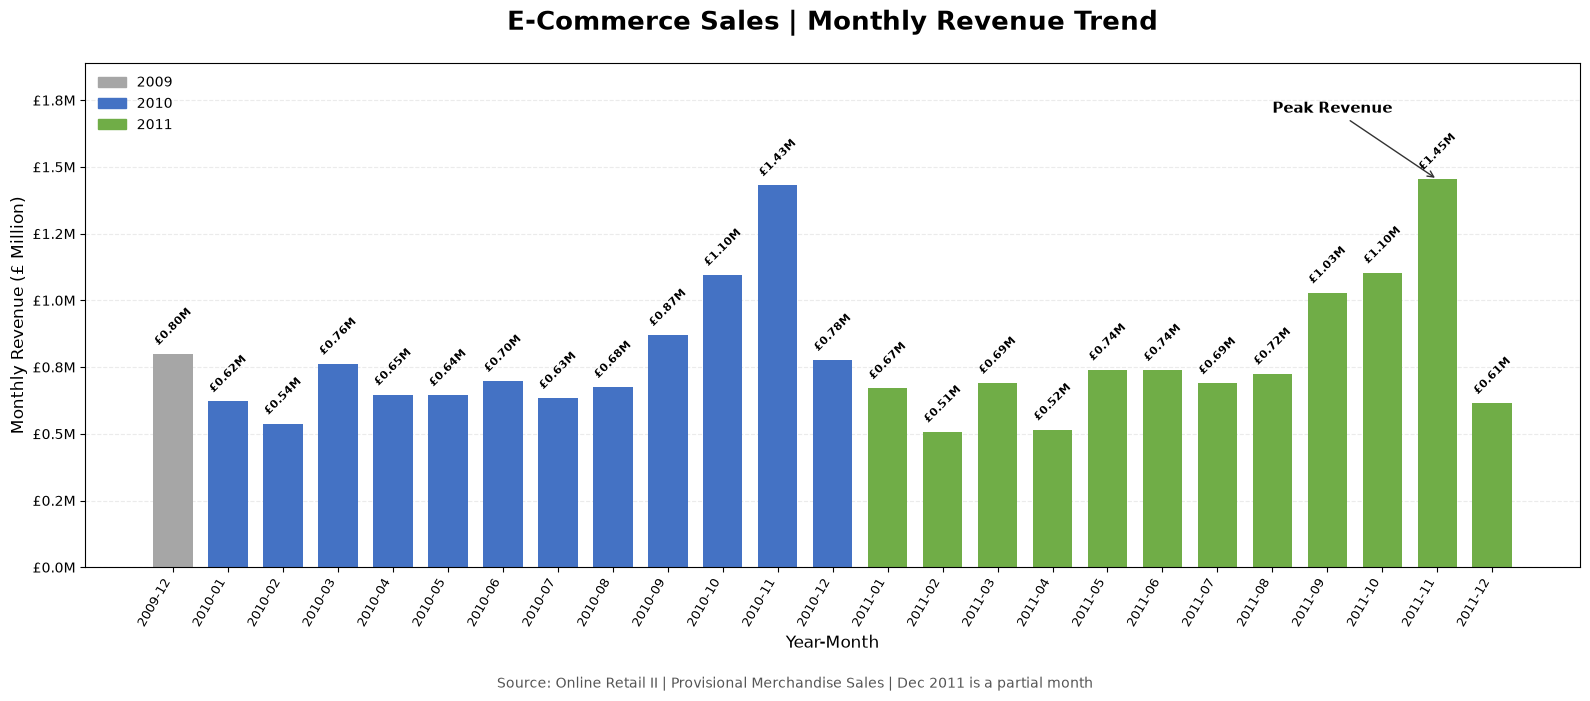

Chart saved: ..\images\eda_04_01_monthly_revenue_trend.png
EDA-04-01-02 Visualization: PASS


In [21]:

# EDA-04-01-02 | Monthly Revenue Trend Visualization

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
from pathlib import Path

plot_df = monthly_sales.copy()
plot_df["Date"] = pd.to_datetime(
    plot_df["YearMonth"] + "-01"
)

plot_df["Year"] = plot_df["Date"].dt.year
plot_df["Month"] = plot_df["Date"].dt.month
plot_df["Revenue_Million"] = (
    plot_df["Revenue_GBP"] / 1_000_000
)

fig, ax = plt.subplots(figsize=(16, 7))

colors = [
    "#4472C4" if year == 2010
    else "#70AD47" if year == 2011
    else "#A6A6A6"
    for year in plot_df["Year"]
]

bars = ax.bar(
    np.arange(len(plot_df)),
    plot_df["Revenue_Million"],
    color=colors,
    width=0.72
)

# Revenue labels for PPT
for bar, value in zip(
    bars, plot_df["Revenue_Million"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.025,
        f"£{value:.2f}M",
        ha="center",
        va="bottom",
        fontsize=8,
        rotation=45,
        fontweight="bold"
    )

# Peak month
peak_idx = plot_df["Revenue_GBP"].idxmax()
peak_pos = plot_df.index.get_loc(peak_idx)
peak_value = plot_df.loc[
    peak_idx, "Revenue_Million"
]

ax.annotate(
    "Peak Revenue",
    xy=(peak_pos, peak_value),
    xytext=(peak_pos - 3, peak_value + 0.25),
    arrowprops=dict(
        arrowstyle="->",
        color="#333333"
    ),
    fontsize=11,
    fontweight="bold"
)

ax.set_title(
    "E-Commerce Sales | Monthly Revenue Trend",
    fontsize=19,
    fontweight="bold",
    pad=24
)

ax.set_ylabel(
    "Monthly Revenue (£ Million)",
    fontsize=12
)

ax.set_xlabel(
    "Year-Month",
    fontsize=12
)

ax.set_xticks(np.arange(len(plot_df)))
ax.set_xticklabels(
    plot_df["YearMonth"],
    rotation=60,
    ha="right",
    fontsize=9
)

ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda x, pos: f"£{x:.1f}M"
    )
)

ax.set_ylim(
    0,
    plot_df["Revenue_Million"].max() * 1.3
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(color="#A6A6A6", label="2009"),
        Patch(color="#4472C4", label="2010"),
        Patch(color="#70AD47", label="2011")
    ],
    loc="upper left",
    frameon=False
)

fig.text(
    0.5, 0.01,
    "Source: Online Retail II | "
    "Provisional Merchandise Sales | "
    "Dec 2011 is a partial month",
    ha="center",
    fontsize=10,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

# Save PPT-ready image
output_dir = Path("../images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir /
    "eda_04_01_monthly_revenue_trend.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Chart saved: {output_path}")
print("EDA-04-01-02 Visualization: PASS")


### EDA-04-01-02 | Interpretation

**Key Findings**

- Monthly provisional merchandise revenue shows substantial fluctuations across the observation period.
- November recorded the highest monthly revenue in both 2010 (£1.43M) and 2011 (£1.45M).
- Revenue increased noticeably during September–November in both years, suggesting a recurring seasonal pattern.
- The highest monthly revenue occurred in November 2011, reaching approximately £1.45M.
- December 2011 represents a partial month and should not be directly compared with complete months.

**Analytical Implications**

- The recurring September–November revenue increase suggests potential seasonal demand, possibly associated with year-end purchasing.
- Inventory planning, promotional campaigns, and sales forecasting could benefit from incorporating seasonal demand patterns.
- Month-over-Month changes alone are insufficient to distinguish seasonal fluctuations from underlying business growth.
- Year-over-Year comparisons are needed to evaluate whether revenue performance improved between 2010 and 2011.

**Conclusion**

Monthly revenue analysis identifies a potential seasonal pattern, with revenue peaking in November in both complete observation years.

Further Year-over-Year analysis is required to assess underlying growth while accounting for seasonality.

In [22]:

# EDA-04-01-03-01 | Year-over-Year Revenue Calculation

import pandas as pd
import numpy as np

# Prepare monthly revenue data
yoy_df = monthly_sales.copy()

yoy_df["Date"] = pd.to_datetime(
    yoy_df["YearMonth"].astype(str) + "-01"
)

yoy_df["Year"] = yoy_df["Date"].dt.year
yoy_df["Month"] = yoy_df["Date"].dt.month

# Compare equivalent months: Jan-Nov 2010 vs 2011
yoy_df = yoy_df[
    (yoy_df["Year"].isin([2010, 2011])) &
    (yoy_df["Month"].between(1, 11))
].copy()

# Monthly revenue comparison
yoy_comparison = (
    yoy_df.pivot_table(
        index="Month",
        columns="Year",
        values="Revenue_GBP",
        aggfunc="sum"
    )
    .reindex(columns=[2010, 2011])
)

yoy_comparison.columns = [
    "Revenue_2010",
    "Revenue_2011"
]

# Calculate YoY growth
yoy_comparison["YoY_Growth_Pct"] = (
    (
        yoy_comparison["Revenue_2011"] /
        yoy_comparison["Revenue_2010"]
    ) - 1
) * 100

# Calculate cumulative revenue growth
total_2010 = yoy_comparison["Revenue_2010"].sum()
total_2011 = yoy_comparison["Revenue_2011"].sum()

cumulative_growth = (
    (total_2011 / total_2010) - 1
) * 100

# Display formatted results
display(
    yoy_comparison.style.format({
        "Revenue_2010": "£{:,.2f}",
        "Revenue_2011": "£{:,.2f}",
        "YoY_Growth_Pct": "{:+.2f}%"
    })
)

print("\n=== Jan-Nov Revenue Comparison ===")
print(f"2010 Revenue: £{total_2010:,.2f}")
print(f"2011 Revenue: £{total_2011:,.2f}")
print(f"YoY Growth: {cumulative_growth:+.2f}%")

# Validation
assert len(yoy_comparison) == 11
assert yoy_comparison[
    ["Revenue_2010", "Revenue_2011"]
].notna().all().all()
assert (yoy_comparison["Revenue_2010"] > 0).all()

print(
    "\nEDA-04-01-03-01 YoY Revenue Calculation: PASS"
)


,Revenue_2010,Revenue_2011,YoY_Growth_Pct
Month,,,
1,"£621,503.43","£670,654.46",+7.91%
2,"£538,141.70","£508,081.54",-5.59%
3,"£762,148.53","£690,591.84",-9.39%
4,"£647,000.49","£515,914.66",-20.26%
5,"£644,006.87","£740,487.33",+14.98%
6,"£697,862.32","£738,233.99",+5.79%
7,"£633,899.42","£688,802.67",+8.66%
8,"£675,079.89","£724,708.16",+7.35%
9,"£869,772.16","£1,029,275.38",+18.34%



=== Jan-Nov Revenue Comparison ===
2010 Revenue: £8,616,021.55
2011 Revenue: £8,864,139.98
YoY Growth: +2.88%

EDA-04-01-03-01 YoY Revenue Calculation: PASS


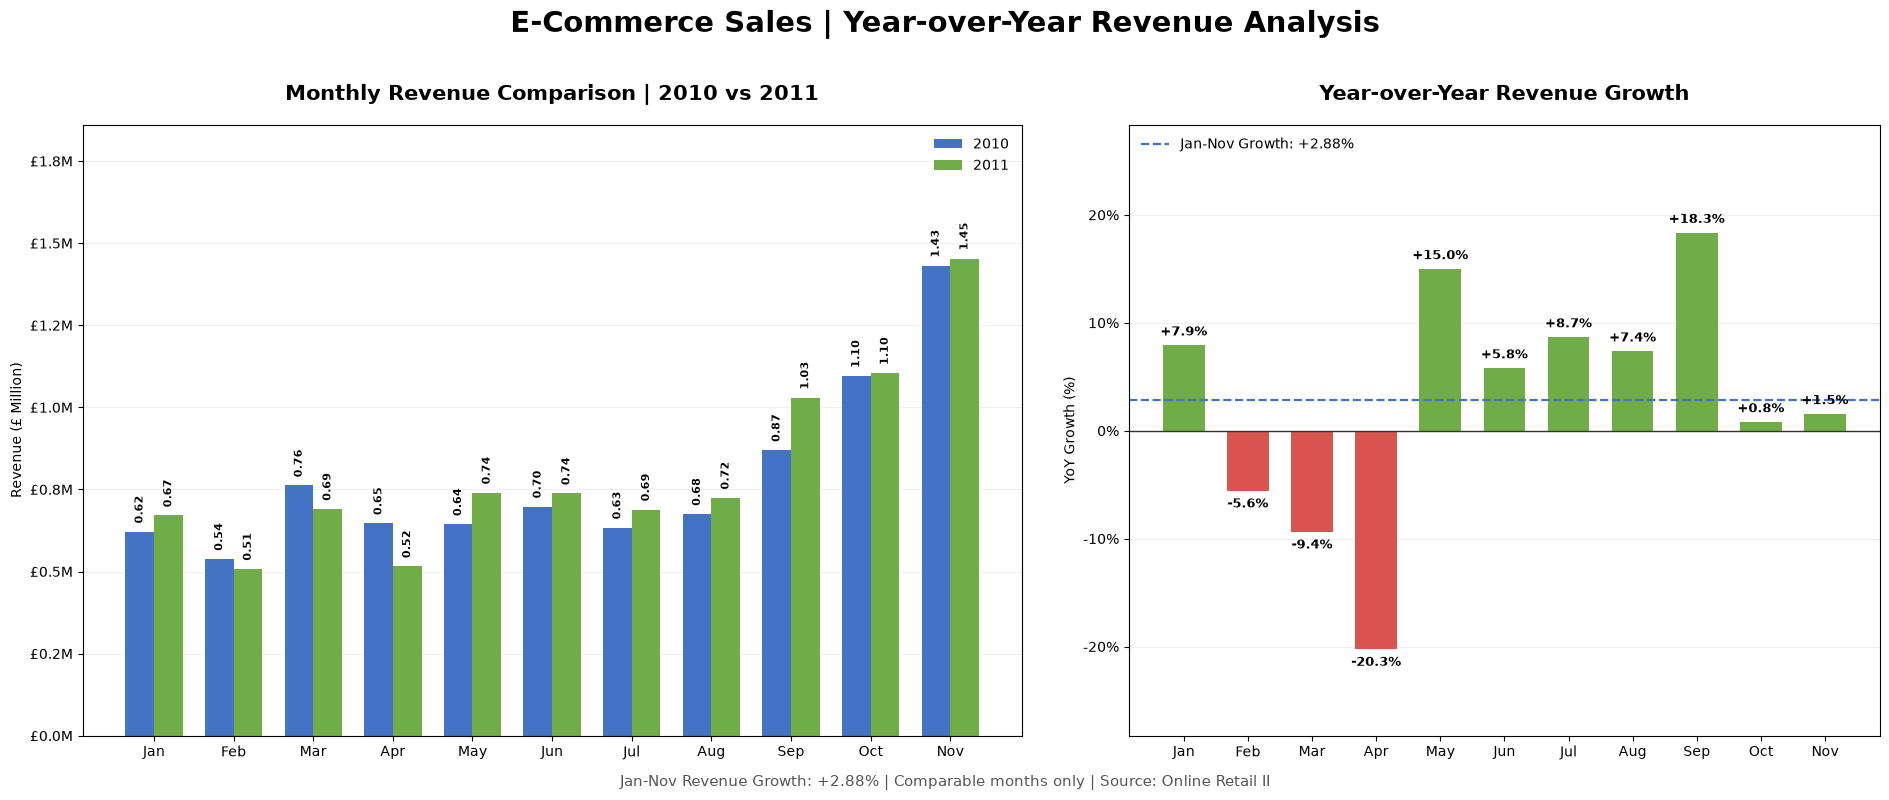

Chart saved: ..\images\eda_04_01_yoy_revenue_comparison.png
EDA-04-01-03-02 YoY Visualization: PASS


In [23]:

# EDA-04-01-03-02 | YoY Revenue Visualization

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
from pathlib import Path

months = np.arange(1, 12)
month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov"
]

revenue_2010 = (
    yoy_comparison["Revenue_2010"].to_numpy() / 1_000_000
)
revenue_2011 = (
    yoy_comparison["Revenue_2011"].to_numpy() / 1_000_000
)
growth = yoy_comparison["YoY_Growth_Pct"].to_numpy()

fig, axes = plt.subplots(
    1, 2, figsize=(19, 7.5),
    gridspec_kw={"width_ratios": [1.25, 1]}
)

# Chart A: Monthly Revenue Comparison
ax1 = axes[0]
width = 0.36

bars_2010 = ax1.bar(
    months - width / 2,
    revenue_2010,
    width,
    label="2010",
    color="#4472C4"
)

bars_2011 = ax1.bar(
    months + width / 2,
    revenue_2011,
    width,
    label="2011",
    color="#70AD47"
)

for bars in [bars_2010, bars_2011]:
    for bar in bars:
        height = bar.get_height()
        ax1.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.025,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            rotation=90,
            fontsize=8,
            fontweight="bold"
        )

ax1.set_title(
    "Monthly Revenue Comparison | 2010 vs 2011",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax1.set_ylabel("Revenue (£ Million)")
ax1.set_xticks(months)
ax1.set_xticklabels(month_labels)
ax1.set_ylim(0, max(revenue_2010.max(), revenue_2011.max()) * 1.28)
ax1.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, pos: f"£{x:.1f}M")
)
ax1.legend(frameon=False)
ax1.grid(axis="y", alpha=0.2)
ax1.set_axisbelow(True)

# Chart B: YoY Growth
ax2 = axes[1]

growth_colors = [
    "#70AD47" if value >= 0 else "#D9534F"
    for value in growth
]

bars_growth = ax2.bar(
    months,
    growth,
    color=growth_colors,
    width=0.65
)

for bar, value in zip(bars_growth, growth):
    ax2.annotate(
        f"{value:+.1f}%",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            value
        ),
        xytext=(0, 5 if value >= 0 else -5),
        textcoords="offset points",
        ha="center",
        va="bottom" if value >= 0 else "top",
        fontsize=9,
        fontweight="bold"
    )

ax2.axhline(0, color="#333333", linewidth=1)
ax2.axhline(
    cumulative_growth,
    color="#4472C4",
    linestyle="--",
    linewidth=1.6,
    label=f"Jan-Nov Growth: {cumulative_growth:+.2f}%"
)

ax2.set_title(
    "Year-over-Year Revenue Growth",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax2.set_ylabel("YoY Growth (%)")
ax2.set_xticks(months)
ax2.set_xticklabels(month_labels)
ax2.set_ylim(
    min(growth.min() - 8, -10),
    max(growth.max() + 10, 25)
)
ax2.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, pos: f"{x:.0f}%")
)
ax2.legend(loc="upper left", frameon=False)
ax2.grid(axis="y", alpha=0.2)
ax2.set_axisbelow(True)

fig.suptitle(
    "E-Commerce Sales | Year-over-Year Revenue Analysis",
    fontsize=21,
    fontweight="bold",
    y=1.02
)

fig.text(
    0.5, -0.015,
    f"Jan-Nov Revenue Growth: {cumulative_growth:+.2f}%"
    " | Comparable months only | "
    "Source: Online Retail II",
    ha="center",
    fontsize=11,
    color="#555555"
)

plt.tight_layout(w_pad=3)

output_dir = Path("../images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir / "eda_04_01_yoy_revenue_comparison.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Chart saved: {output_path}")
print("EDA-04-01-03-02 YoY Visualization: PASS")


### EDA-04-01-03 | Interpretation

**Key Findings**

- Total provisional merchandise revenue increased from £8.62M in January–November 2010 to £8.86M during the same period in 2011, representing **+2.88% Year-over-Year growth**.
- Revenue increased in 8 of the 11 comparable months, while February, March, and April recorded negative growth.
- September achieved the strongest YoY growth at **+18.34%**, followed by May at **+14.98%**.
- April experienced the largest decline at **-20.26%**.
- November remained the highest-revenue month in both years, although its YoY growth was relatively modest at **+1.54%**.

**Analytical Implications**

- Overall revenue growth was positive but modest, indicating relatively stable aggregate sales performance.
- Monthly growth rates varied considerably, suggesting that revenue performance was not uniform throughout the year.
- The recurring revenue increase during September–November supports the presence of a potential seasonal sales pattern.
- Stronger performance in selected months did not translate into equally strong full-period growth.
- Further analysis of transaction volume, average order value (AOV), and customer purchasing behavior is needed to identify the drivers of revenue changes.

**Methodological Notes**

- The comparison covers January–November 2010 and January–November 2011 to ensure equivalent observation periods.
- December 2011 was excluded because the dataset contains only a partial month.
- The cumulative YoY growth rate was calculated using total revenue for the comparable 11-month periods, rather than the arithmetic average of monthly growth rates.

**Conclusion**

The business achieved modest revenue growth of **2.88%** between the comparable periods in 2010 and 2011, while showing substantial month-to-month variation.

The results suggest that understanding revenue performance requires examining both seasonal demand patterns and underlying transaction-level drivers.

In [24]:

# EDA-04-02-01 | Monthly Orders & AOV Calculation

import pandas as pd
import numpy as np

# Use provisional merchandise sales
orders_df = merchandise_sales_df.copy()

# Ensure correct datetime format
orders_df["InvoiceDate"] = pd.to_datetime(
    orders_df["InvoiceDate"]
)

orders_df["YearMonth"] = (
    orders_df["InvoiceDate"]
    .dt.to_period("M")
    .astype(str)
)

# Calculate monthly revenue and unique orders
monthly_orders = (
    orders_df
    .groupby("YearMonth")
    .agg(
        Revenue_GBP=("Sales", "sum"),
        Unique_Orders=("Invoice", "nunique"),
        Records=("Invoice", "size")
    )
    .reset_index()
    .sort_values("YearMonth")
)

# Calculate Average Order Value
monthly_orders["AOV_GBP"] = (
    monthly_orders["Revenue_GBP"] /
    monthly_orders["Unique_Orders"]
)

# Format output
display(
    monthly_orders.style.format({
        "Revenue_GBP": "£{:,.2f}",
        "Unique_Orders": "{:,.0f}",
        "Records": "{:,.0f}",
        "AOV_GBP": "£{:,.2f}"
    })
)

# Validation
assert len(monthly_orders) == 25
assert monthly_orders["Unique_Orders"].gt(0).all()
assert np.isclose(
    monthly_orders["Revenue_GBP"].sum(),
    orders_df["Sales"].sum()
)

print("\n=== Monthly Orders & AOV Summary ===")
print(f"Total Months: {len(monthly_orders)}")
print(
    f"Total Revenue: "
    f"£{monthly_orders['Revenue_GBP'].sum():,.2f}"
)
print(
    f"Unique Invoices: "
    f"{orders_df['Invoice'].nunique():,}"
)
print(
    f"Overall AOV: "
    f"£{orders_df['Sales'].sum() / orders_df['Invoice'].nunique():,.2f}"
)

print(
    "\nEDA-04-02-01 Monthly Orders & AOV: PASS"
)



,YearMonth,Revenue_GBP,Unique_Orders,Records,AOV_GBP
0,2009-12,"£798,747.03","1,672","43,343",£477.72
1,2010-01,"£621,503.43","1,089","30,224",£570.71
2,2010-02,"£538,141.70","1,190","27,823",£452.22
3,2010-03,"£762,148.53","1,647","39,621",£462.75
4,2010-04,"£647,000.49","1,441","32,685",£448.99
5,2010-05,"£644,006.87","1,488","33,239",£432.80
6,2010-06,"£697,862.32","1,617","38,227",£431.58
7,2010-07,"£633,899.42","1,513","31,964",£418.97
8,2010-08,"£675,079.89","1,406","31,978",£480.14
9,2010-09,"£869,772.16","1,792","40,429",£485.36



=== Monthly Orders & AOV Summary ===
Total Months: 25
Total Revenue: £19,669,952.77
Unique Invoices: 39,613
Overall AOV: £496.55

EDA-04-02-01 Monthly Orders & AOV: PASS


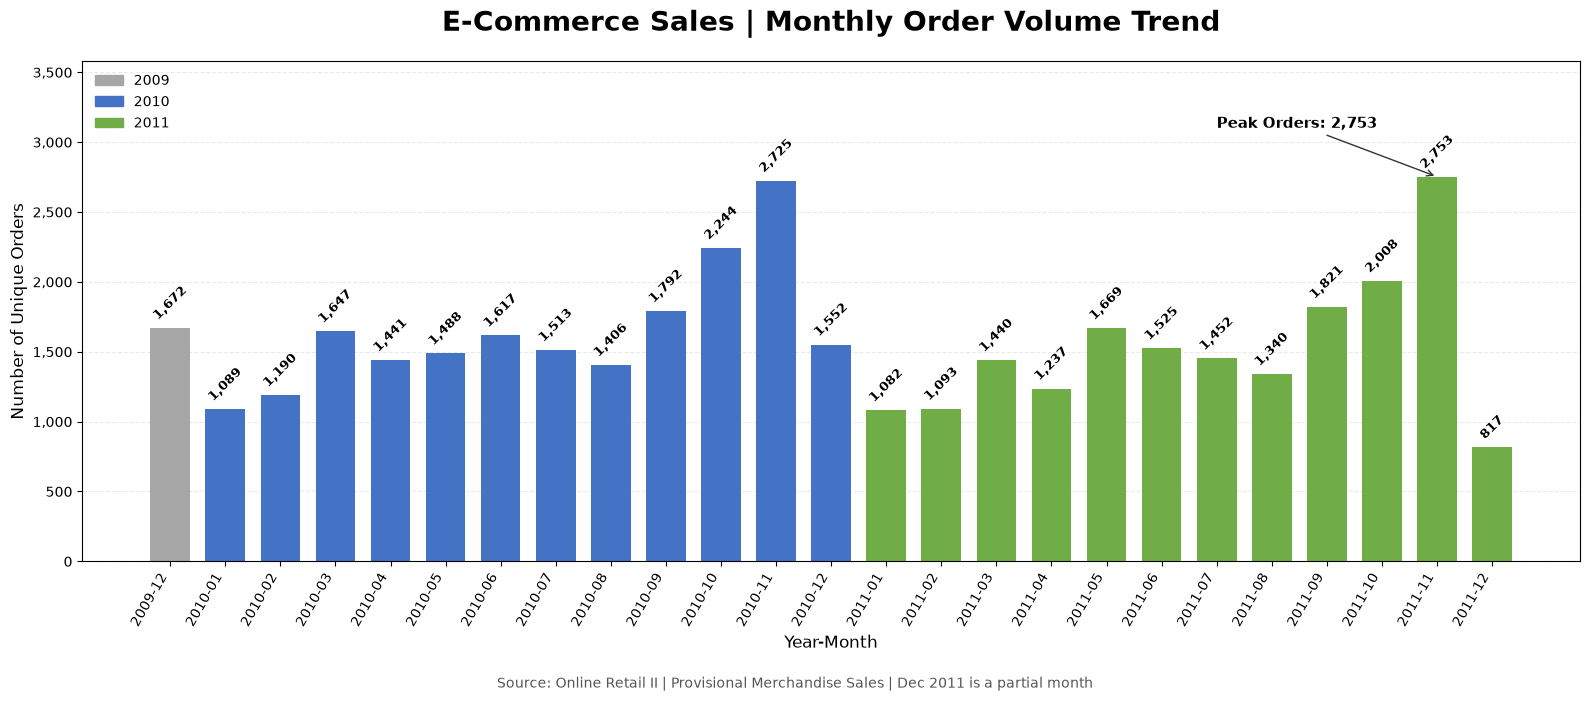

Chart saved: ..\images\eda_04_02_monthly_order_volume.png
EDA-04-02-02 Monthly Order Volume: PASS


In [25]:

# EDA-04-02-02 | Monthly Order Volume Trend

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
from pathlib import Path

plot_df = monthly_orders.copy()

plot_df["Date"] = pd.to_datetime(
    plot_df["YearMonth"] + "-01"
)
plot_df["Year"] = plot_df["Date"].dt.year

colors = [
    "#A6A6A6" if year == 2009
    else "#4472C4" if year == 2010
    else "#70AD47"
    for year in plot_df["Year"]
]

fig, ax = plt.subplots(figsize=(16, 7))

x = np.arange(len(plot_df))

bars = ax.bar(
    x,
    plot_df["Unique_Orders"],
    color=colors,
    width=0.72
)

# Data labels
for bar in bars:
    value = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 40,
        f"{int(value):,}",
        ha="center",
        va="bottom",
        rotation=45,
        fontsize=9,
        fontweight="bold"
    )

# Peak order month
peak_idx = plot_df["Unique_Orders"].idxmax()
peak_pos = plot_df.index.get_loc(peak_idx)
peak_orders = plot_df.loc[peak_idx, "Unique_Orders"]

ax.annotate(
    f"Peak Orders: {peak_orders:,}",
    xy=(peak_pos, peak_orders),
    xytext=(peak_pos - 4, peak_orders + 350),
    arrowprops=dict(
        arrowstyle="->",
        color="#333333"
    ),
    fontsize=11,
    fontweight="bold"
)

ax.set_title(
    "E-Commerce Sales | Monthly Order Volume Trend",
    fontsize=20,
    fontweight="bold",
    pad=22
)

ax.set_xlabel("Year-Month", fontsize=12)
ax.set_ylabel("Number of Unique Orders", fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(
    plot_df["YearMonth"],
    rotation=60,
    ha="right"
)

ax.yaxis.set_major_formatter(
    mticker.StrMethodFormatter("{x:,.0f}")
)

ax.set_ylim(
    0,
    plot_df["Unique_Orders"].max() * 1.30
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)
ax.set_axisbelow(True)

from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(color="#A6A6A6", label="2009"),
        Patch(color="#4472C4", label="2010"),
        Patch(color="#70AD47", label="2011")
    ],
    loc="upper left",
    frameon=False
)

fig.text(
    0.5, 0.01,
    "Source: Online Retail II | "
    "Provisional Merchandise Sales | "
    "Dec 2011 is a partial month",
    ha="center",
    fontsize=10,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

output_dir = Path("../images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir /
    "eda_04_02_monthly_order_volume.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Chart saved: {output_path}")
print("EDA-04-02-02 Monthly Order Volume: PASS")


### EDA-04-02-02 | Interpretation | Monthly Order Volume Trend

**Key Findings**

- **Seasonal Order Concentration:** Monthly order volume shows a clear seasonal pattern, with order activity increasing significantly during September–November in both 2010 and 2011.
- **Peak Order Volume:** November 2011 recorded the highest monthly order volume at **2,753 unique orders**, slightly exceeding November 2010 (2,725 orders).
- **Early-Year Slowdown:** January and February generally recorded lower order volumes compared with the fourth-quarter peak.
- **Year-End Comparison:** December 2011 recorded only 817 orders. However, this month contains partial data and should not be directly compared with complete months.

**Business Implications**

- The recurring increase in orders during September–November suggests that inventory planning, promotional campaigns, and fulfillment capacity should be strengthened ahead of the year-end shopping season.
- Comparing monthly order volume with Average Order Value (AOV) will help determine whether revenue fluctuations are primarily driven by transaction frequency or spending per order.
- Seasonal patterns observed across two years should be treated as preliminary findings rather than definitive evidence of long-term seasonality.

**Conclusion**

Monthly order volume demonstrates a recurring year-end peak, particularly in November. Further AOV analysis is needed to distinguish order-driven revenue growth from changes in average transaction value.

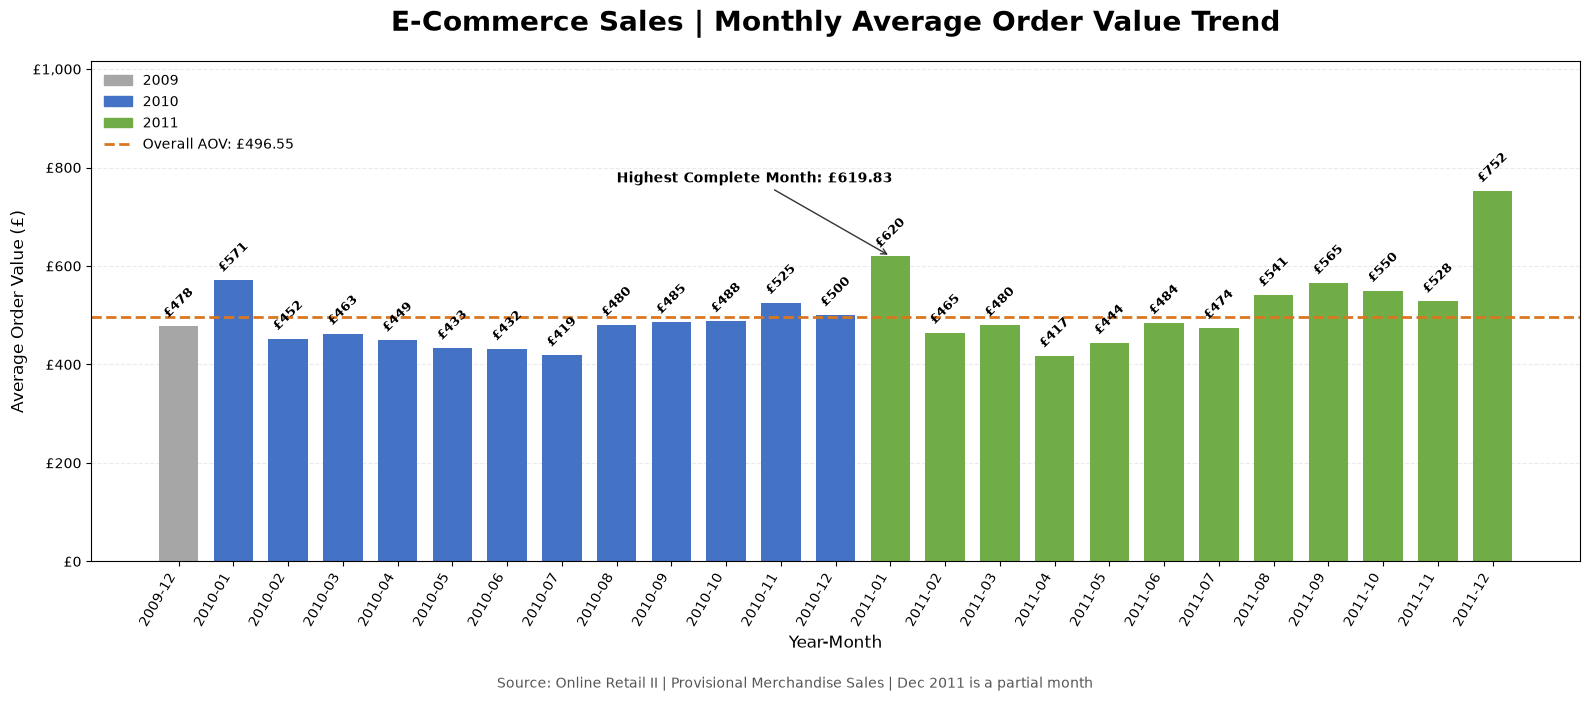

Overall AOV: £496.55
Chart saved: ..\images\eda_04_02_monthly_aov_trend.png
EDA-04-02-03 Monthly AOV Trend: PASS


In [26]:

# EDA-04-02-03 | Monthly Average Order Value Trend

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
from pathlib import Path

# 1. Prepare monthly AOV data
aov_df = monthly_orders.copy()

aov_df["Date"] = pd.to_datetime(
    aov_df["YearMonth"].astype(str) + "-01"
)
aov_df["Year"] = aov_df["Date"].dt.year

aov_df = aov_df.sort_values("Date").reset_index(drop=True)

# 2. Calculate overall AOV
overall_aov = (
    aov_df["Revenue_GBP"].sum()
    / aov_df["Unique_Orders"].sum()
)

# 3. Define colors
colors = [
    "#A6A6A6" if year == 2009
    else "#4472C4" if year == 2010
    else "#70AD47"
    for year in aov_df["Year"]
]

# 4. Create chart
fig, ax = plt.subplots(figsize=(16, 7))

x = np.arange(len(aov_df))

bars = ax.bar(
    x,
    aov_df["AOV_GBP"],
    color=colors,
    width=0.72
)

# 5. Add value labels
for bar in bars:
    value = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 12,
        f"£{value:,.0f}",
        ha="center",
        va="bottom",
        rotation=45,
        fontsize=9,
        fontweight="bold"
    )

# 6. Overall AOV reference line
ax.axhline(
    overall_aov,
    color="#D97721",
    linestyle="--",
    linewidth=2,
    label=f"Overall AOV: £{overall_aov:,.2f}"
)

# 7. Highlight peak complete month
complete_df = aov_df[
    aov_df["YearMonth"] != "2011-12"
]

peak_idx = complete_df["AOV_GBP"].idxmax()
peak_aov = aov_df.loc[peak_idx, "AOV_GBP"]

ax.annotate(
    f"Highest Complete Month: £{peak_aov:,.2f}",
    xy=(peak_idx, peak_aov),
    xytext=(peak_idx - 5, peak_aov + 150),
    arrowprops=dict(
        arrowstyle="->",
        color="#333333"
    ),
    fontsize=10,
    fontweight="bold"
)

# 8. Chart formatting
ax.set_title(
    "E-Commerce Sales | Monthly Average Order Value Trend",
    fontsize=20,
    fontweight="bold",
    pad=22
)

ax.set_xlabel("Year-Month", fontsize=12)
ax.set_ylabel("Average Order Value (£)", fontsize=12)

ax.set_xticks(x)
ax.set_xticklabels(
    aov_df["YearMonth"],
    rotation=60,
    ha="right"
)

ax.yaxis.set_major_formatter(
    mticker.StrMethodFormatter("£{x:,.0f}")
)

ax.set_ylim(
    0,
    aov_df["AOV_GBP"].max() * 1.35
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)
ax.set_axisbelow(True)

legend_handles = [
    Patch(color="#A6A6A6", label="2009"),
    Patch(color="#4472C4", label="2010"),
    Patch(color="#70AD47", label="2011"),
    plt.Line2D(
        [0], [0],
        color="#D97721",
        linestyle="--",
        linewidth=2,
        label=f"Overall AOV: £{overall_aov:,.2f}"
    )
]

ax.legend(
    handles=legend_handles,
    loc="upper left",
    frameon=False
)

# 9. Source note
fig.text(
    0.5, 0.01,
    "Source: Online Retail II | "
    "Provisional Merchandise Sales | "
    "Dec 2011 is a partial month",
    ha="center",
    fontsize=10,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

# 10. Save chart
output_dir = Path("../images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir /
    "eda_04_02_monthly_aov_trend.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 11. Validation
print(f"Overall AOV: £{overall_aov:,.2f}")
print(f"Chart saved: {output_path}")
print("EDA-04-02-03 Monthly AOV Trend: PASS")


### Interpretation | Monthly Average Order Value (AOV) Trend

**Key Findings**

- **Overall AOV:** The overall Average Order Value was **£496.55**, calculated by dividing total merchandise revenue by the number of unique invoices.
- **Monthly AOV Variation:** Monthly AOV fluctuated throughout the analysis period, indicating changes in average spending per order.
- **Highest Complete Month:** January 2011 recorded the highest AOV among complete months at **£619.83**, while April 2011 recorded the lowest at **£417.07**.
- **Order Volume vs. AOV:** November 2011 recorded the highest monthly order volume (2,753 orders), but its AOV (£527.90) remained below the January 2011 peak.
- **Partial-Month Limitation:** December 2011 recorded an AOV of £752.40. However, the dataset covers only part of December, so this result should be interpreted cautiously.

**Business Implications**

- Revenue performance should be evaluated using both order volume and AOV rather than relying on either metric independently.
- Higher order volume does not necessarily correspond to higher spending per order.
- Further investigation into product mix, bulk purchasing, and customer purchasing behavior may help explain monthly AOV fluctuations.

**Conclusion**

Monthly AOV shows meaningful variation across the analysis period. Combining AOV with order volume provides a more comprehensive understanding of revenue performance and helps identify potential drivers of sales growth.

In [27]:

# EDA-04-02-04-01 | Revenue Growth Decomposition
# Comparable Period: January–November, 2010 vs 2011

import pandas as pd
import numpy as np

# 1. Prepare data
growth_df = monthly_orders.copy()

growth_df["Date"] = pd.to_datetime(
    growth_df["YearMonth"].astype(str) + "-01"
)

growth_df["Year"] = growth_df["Date"].dt.year
growth_df["Month"] = growth_df["Date"].dt.month

# 2. Select comparable months
comparison_df = growth_df[
    (growth_df["Year"].isin([2010, 2011])) &
    (growth_df["Month"].between(1, 11))
].copy()

# 3. Annual summary
annual_summary = (
    comparison_df
    .groupby("Year")
    .agg(
        Revenue_GBP=("Revenue_GBP", "sum"),
        Unique_Orders=("Unique_Orders", "sum")
    )
)

annual_summary["AOV_GBP"] = (
    annual_summary["Revenue_GBP"] /
    annual_summary["Unique_Orders"]
)

# 4. Extract values
r0 = annual_summary.loc[2010, "Revenue_GBP"]
r1 = annual_summary.loc[2011, "Revenue_GBP"]

o0 = annual_summary.loc[2010, "Unique_Orders"]
o1 = annual_summary.loc[2011, "Unique_Orders"]

a0 = annual_summary.loc[2010, "AOV_GBP"]
a1 = annual_summary.loc[2011, "AOV_GBP"]

# 5. Growth rates
revenue_growth = (r1 / r0 - 1) * 100
order_growth = (o1 / o0 - 1) * 100
aov_growth = (a1 / a0 - 1) * 100

# 6. Revenue decomposition
order_effect = (o1 - o0) * a0
aov_effect = o1 * (a1 - a0)

total_change = r1 - r0

# 7. Contribution percentages
order_contribution_pct = (
    order_effect / total_change * 100
)

aov_contribution_pct = (
    aov_effect / total_change * 100
)

# 8. Display annual comparison
annual_display = annual_summary.copy()

annual_display["Revenue_GBP"] = (
    annual_display["Revenue_GBP"].map("£{:,.2f}".format)
)

annual_display["Unique_Orders"] = (
    annual_display["Unique_Orders"].map("{:,.0f}".format)
)

annual_display["AOV_GBP"] = (
    annual_display["AOV_GBP"].map("£{:,.2f}".format)
)

print("=== Jan-Nov Annual Comparison ===")
display(annual_display)

# 9. Growth summary
growth_summary = pd.DataFrame({
    "Metric": [
        "Revenue Growth (%)",
        "Order Volume Growth (%)",
        "AOV Growth (%)",
        "Revenue Change (£)",
        "Order Volume Effect (£)",
        "AOV Effect (£)",
        "Order Contribution (%)",
        "AOV Contribution (%)"
    ],
    "Value": [
        f"{revenue_growth:+.2f}%",
        f"{order_growth:+.2f}%",
        f"{aov_growth:+.2f}%",
        f"£{total_change:,.2f}",
        f"£{order_effect:,.2f}",
        f"£{aov_effect:,.2f}",
        f"{order_contribution_pct:+.2f}%",
        f"{aov_contribution_pct:+.2f}%"
    ]
})

print("\n=== Revenue Growth Decomposition ===")
display(growth_summary)

# 10. Validation
assert len(comparison_df) == 22
assert set(annual_summary.index) == {2010, 2011}
assert np.isclose(
    order_effect + aov_effect,
    total_change,
    atol=0.01
)

assert np.isclose(
    (1 + order_growth / 100) *
    (1 + aov_growth / 100) - 1,
    revenue_growth / 100
)

print(
    "\nEDA-04-02-04-01 "
    "Revenue Growth Decomposition: PASS"
)


=== Jan-Nov Annual Comparison ===


,Revenue_GBP,Unique_Orders,AOV_GBP
Year,,,
2010,"£8,616,021.55","18,152",£474.66
2011,"£8,864,139.98","17,420",£508.85



=== Revenue Growth Decomposition ===


,Metric,Value
0,Revenue Growth (%),+2.88%
1,Order Volume Growth (%),-4.03%
2,AOV Growth (%),+7.20%
3,Revenue Change (£),"£248,118.43"
4,Order Volume Effect (£),"£-347,450.85"
5,AOV Effect (£),"£595,569.28"
6,Order Contribution (%),-140.03%
7,AOV Contribution (%),+240.03%



EDA-04-02-04-01 Revenue Growth Decomposition: PASS


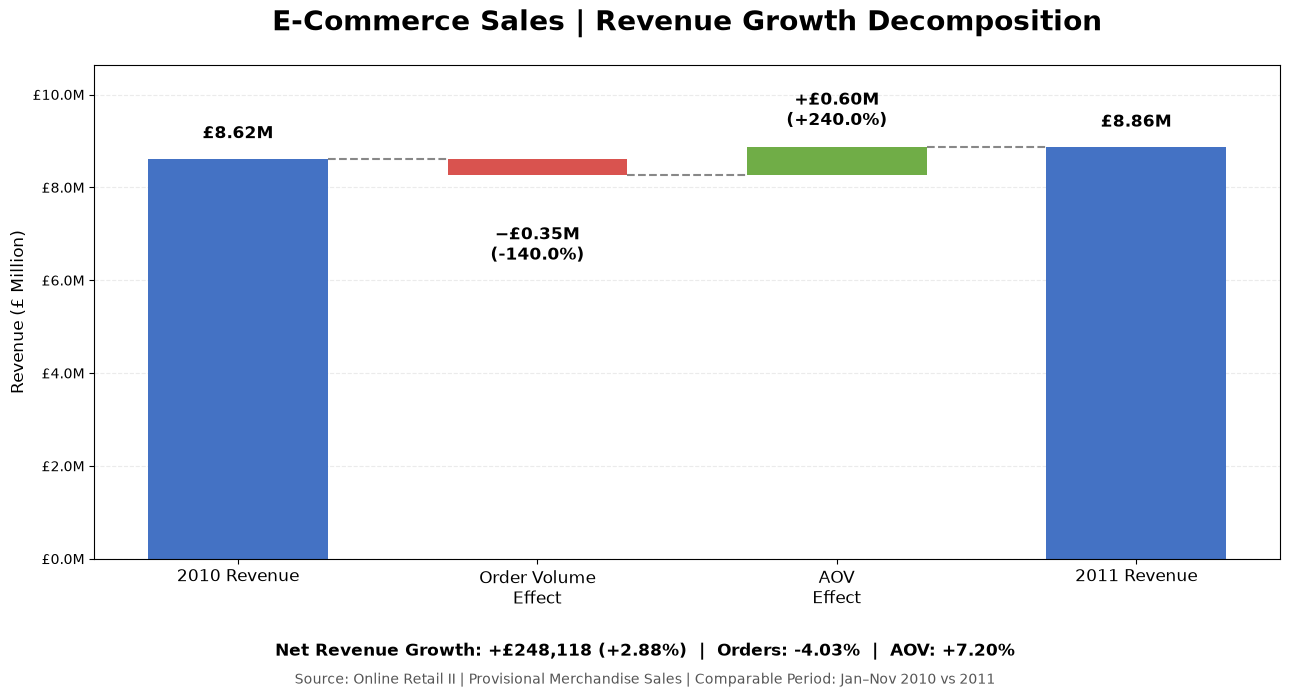

Chart saved: ..\images\eda_04_02_revenue_growth_decomposition.png
EDA-04-02-04-02 Revenue Growth Waterfall: PASS


In [28]:

# EDA-04-02-04-02 | Revenue Growth Waterfall Chart

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path
import numpy as np

# Values from EDA-04-02-04-01
start_revenue = r0
end_revenue = r1

effects = [order_effect, aov_effect]

# Convert GBP to millions
start_m = start_revenue / 1e6
end_m = end_revenue / 1e6
effects_m = [v / 1e6 for v in effects]

fig, ax = plt.subplots(figsize=(13, 7))

x = np.arange(4)
width = 0.60

# Starting revenue
ax.bar(
    x[0], start_m,
    width=width,
    color="#4472C4"
)

# Order volume effect
ax.bar(
    x[1],
    effects_m[0],
    bottom=start_m,
    width=width,
    color="#D9534F"
)

# AOV effect
intermediate_m = start_m + effects_m[0]

ax.bar(
    x[2],
    effects_m[1],
    bottom=intermediate_m,
    width=width,
    color="#70AD47"
)

# Ending revenue
ax.bar(
    x[3], end_m,
    width=width,
    color="#4472C4"
)

# Connector lines
ax.plot(
    [x[0] + width/2, x[1] - width/2],
    [start_m, start_m],
    color="#888888",
    linestyle="--"
)

ax.plot(
    [x[1] + width/2, x[2] - width/2],
    [intermediate_m, intermediate_m],
    color="#888888",
    linestyle="--"
)

ax.plot(
    [x[2] + width/2, x[3] - width/2],
    [end_m, end_m],
    color="#888888",
    linestyle="--"
)

# Data labels
labels = [
    f"£{start_m:.2f}M",
    f"−£{abs(effects_m[0]):.2f}M\n({order_contribution_pct:+.1f}%)",
    f"+£{effects_m[1]:.2f}M\n({aov_contribution_pct:+.1f}%)",
    f"£{end_m:.2f}M"
]

positions = [
    start_m,
    intermediate_m,
    end_m,
    end_m
]

for i, (label, pos) in enumerate(zip(labels, positions)):
    ax.annotate(
        label,
        xy=(x[i], pos),
        xytext=(0, 12 if i != 1 else -36),
        textcoords="offset points",
        ha="center",
        va="bottom" if i != 1 else "top",
        fontsize=12,
        fontweight="bold"
    )

ax.set_xticks(x)
ax.set_xticklabels([
    "2010 Revenue",
    "Order Volume\nEffect",
    "AOV\nEffect",
    "2011 Revenue"
], fontsize=12)

ax.set_title(
    "E-Commerce Sales | Revenue Growth Decomposition",
    fontsize=20,
    fontweight="bold",
    pad=25
)

ax.set_ylabel("Revenue (£ Million)", fontsize=12)

ax.yaxis.set_major_formatter(
    mticker.StrMethodFormatter("£{x:.1f}M")
)

ax.set_ylim(0, max(start_m, end_m) * 1.20)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)
ax.set_axisbelow(True)

# Summary annotation
fig.text(
    0.5, 0.055,
    f"Net Revenue Growth: +£{total_change:,.0f} "
    f"({revenue_growth:+.2f}%)  |  "
    f"Orders: {order_growth:+.2f}%  |  "
    f"AOV: {aov_growth:+.2f}%",
    ha="center",
    fontsize=12,
    fontweight="bold"
)

fig.text(
    0.5, 0.015,
    "Source: Online Retail II | Provisional Merchandise Sales "
    "| Comparable Period: Jan–Nov 2010 vs 2011",
    ha="center",
    fontsize=10,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.10, 1, 1])

# Save for PPT
output_dir = Path("../images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir /
    "eda_04_02_revenue_growth_decomposition.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Chart saved: {output_path}")
print(
    "EDA-04-02-04-02 Revenue Growth Waterfall: PASS"
)


### EDA-04-02-04 | Interpretation | Revenue Growth Decomposition | 

**Key Findings**

- **Revenue Growth:** Merchandise revenue increased by **2.88%**, from £8.62M in January–November 2010 to £8.86M in the corresponding period of 2011.
- **Declining Order Volume:** Unique order volume decreased by **4.03%**, generating a negative revenue contribution of approximately **£347K**.
- **Increasing Average Order Value:** AOV increased by **7.20%**, from £474.66 to £508.85, contributing approximately **£596K** to revenue growth.
- **Net Revenue Impact:** The positive AOV effect more than offset the negative order volume effect, resulting in a net revenue increase of approximately **£248K**.
- **Growth Contribution:** Order volume accounted for **−140.03%** and AOV for **+240.03%** of the net revenue change, using a sequential decomposition method.

**Business Implications**

- **AOV-Driven Growth:** Revenue growth was primarily driven by higher spending per order rather than an increase in order volume.
- **Order Volume Risk:** The decline in unique orders may indicate weakening transaction activity and warrants further investigation.
- **Customer Purchasing Behavior:** Changes in product mix, order quantities, or customer purchasing patterns may explain the increase in AOV. These factors require additional analysis before drawing conclusions.
- **Growth Strategy:** Future initiatives should balance maintaining higher AOV with improving order volume.

**Methodological Note**

The analysis compares January–November 2010 and 2011 to ensure consistent reporting periods. Revenue changes were decomposed sequentially into order volume and AOV effects. Contribution percentages represent shares of the net revenue change, not the growth rates of the underlying metrics.

**Conclusion**

Despite a 4.03% decline in order volume, merchandise revenue grew by 2.88% due to a 7.20% increase in AOV. This indicates that average transaction value was the primary driver of revenue growth during the comparison period.


## EDA-04-03 | Geographic Sales Performance Analysis

### EDA-04-03-01 | Country Sales Aggregation

**Objective**

Analyze merchandise revenue distribution across countries to identify major markets, measure geographic revenue concentration, and establish a baseline for international market performance comparisons.

**Methodology**

- Use the provisional merchandise sales dataset (`merchandise_sales_df`).
- Aggregate revenue, unique invoices, and transaction records by country.
- Calculate each country's contribution to total merchandise revenue.
- Rank countries by revenue and validate aggregated totals.

**Scope**

This analysis covers positive merchandise sales and excludes previously separated special transactions. Geographic performance is measured by transaction country, not necessarily the customer's country of residence.


In [29]:

# EDA-04-03-01-01 | Country Sales Aggregation

import pandas as pd
import numpy as np

# 1. Use provisional merchandise sales dataset
geo_df = merchandise_sales_df.copy()

# 2. Aggregate country-level performance
country_sales_df = (
    geo_df.groupby("Country", dropna=False)
    .agg(
        Revenue_GBP=("Sales", "sum"),
        Unique_Invoices=("Invoice", "nunique"),
        Records=("Invoice", "size")
    )
    .reset_index()
)

# 3. Calculate revenue share
total_revenue = geo_df["Sales"].sum()

country_sales_df["Revenue_Share_Pct"] = (
    country_sales_df["Revenue_GBP"]
    / total_revenue * 100
)

# 4. Sort by revenue
country_sales_df = (
    country_sales_df
    .sort_values("Revenue_GBP", ascending=False)
    .reset_index(drop=True)
)

# 5. Display formatted summary
display(
    country_sales_df.head(15).style.format({
        "Revenue_GBP": "£{:,.2f}",
        "Unique_Invoices": "{:,}",
        "Records": "{:,}",
        "Revenue_Share_Pct": "{:.2f}%"
    })
)

# 6. Validation
aggregated_revenue = country_sales_df["Revenue_GBP"].sum()
aggregated_records = country_sales_df["Records"].sum()

revenue_check = np.isclose(
    aggregated_revenue, total_revenue
)

record_check = (
    aggregated_records == len(geo_df)
)

share_check = np.isclose(
    country_sales_df["Revenue_Share_Pct"].sum(),
    100.0
)

print("\n=== Geographic Sales Summary ===")
print(f"Total Countries: {len(country_sales_df):,}")
print(f"Total Records: {aggregated_records:,}")
print(f"Total Revenue: £{aggregated_revenue:,.2f}")

print("\n=== Validation ===")
print(f"Revenue Reconciliation: {revenue_check}")
print(f"Record Reconciliation: {record_check}")
print(f"Revenue Share Reconciliation: {share_check}")

if all([revenue_check, record_check, share_check]):
    print("\nEDA-04-03-01 Country Sales Aggregation: PASS")
else:
    print("\nEDA-04-03-01 Country Sales Aggregation: REVIEW")


,Country,Revenue_GBP,Unique_Invoices,Records,Revenue_Share_Pct
0,United Kingdom,"£16,814,257.98","36,249","923,786",85.48%
1,EIRE,"£634,907.53",599,"17,126",3.23%
2,Netherlands,"£549,773.41",216,"4,981",2.79%
3,Germany,"£383,419.24",756,"15,791",1.95%
4,France,"£311,543.02",602,"13,165",1.58%
5,Australia,"£167,800.01",89,"1,783",0.85%
6,Spain,"£97,994.50",147,"3,563",0.50%
7,Switzerland,"£94,024.59",85,"3,068",0.48%
8,Sweden,"£86,319.14",99,"1,285",0.44%
9,Denmark,"£67,422.69",42,756,0.34%



=== Geographic Sales Summary ===
Total Countries: 43
Total Records: 1,003,792
Total Revenue: £19,669,952.77

=== Validation ===
Revenue Reconciliation: True
Record Reconciliation: True
Revenue Share Reconciliation: True

EDA-04-03-01 Country Sales Aggregation: PASS


### EDA-04-03-01 | Interpretation | Country Sales Aggregation

**Key Findings**

- The dataset contains **1,003,792 merchandise sales records** across **43 countries**, generating approximately **£19.67M** in revenue.
- The **United Kingdom** dominates merchandise sales, contributing **85.48%** of total revenue (£16.81M).
- International markets excluding the UK account for approximately **14.52%** of total merchandise revenue.
- The leading non-UK markets are **EIRE (3.23%)**, **Netherlands (2.79%)**, **Germany (1.95%)**, and **France (1.58%)**.
- All revenue, record, and revenue-share reconciliation checks passed.

**Business Implications**

- **Market Concentration:** Revenue is highly concentrated in the UK, indicating substantial dependence on the domestic market.
- **International Opportunities:** European markets represent potential opportunities for geographic diversification.
- **Strategic Priority:** Further analysis should evaluate the revenue contribution and purchasing patterns of non-UK markets before making expansion recommendations.

**Conclusion**

Geographic sales performance reveals a strong concentration in the UK market, highlighting the importance of balancing domestic market performance with international revenue diversification.


### EDA-04-03-02 | Top 10 Countries by Revenue

**Objective**

Visualize geographic revenue concentration and compare the leading international markets.

**Methodology**

- Rank countries by merchandise revenue.
- Compare the top 10 countries overall.
- Separately visualize the top 10 non-UK countries.
- Display revenue values and percentage contributions.
- Export the visualization for presentation use.


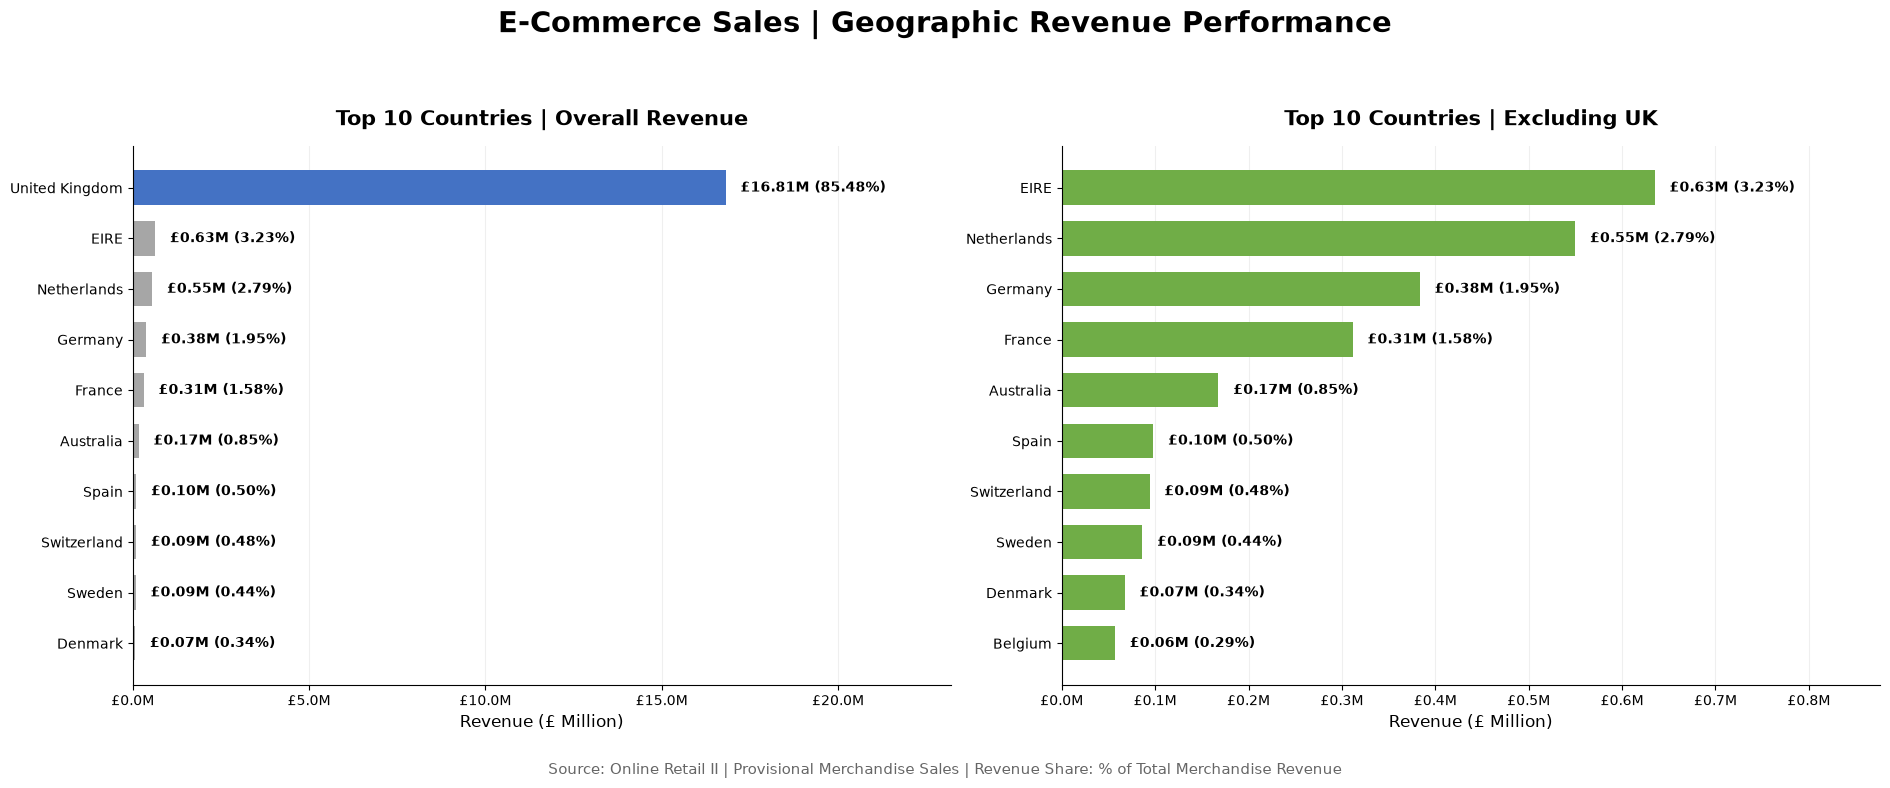

Chart saved: images\eda_04_03_02_geographic_revenue.png
EDA-04-03-02-01 Geographic Revenue Chart: PASS


In [30]:

# EDA-04-03-02-01 | Top 10 Countries by Revenue

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
from pathlib import Path

# 1. Prepare datasets
top10_countries = country_sales_df.head(10).copy()

top10_non_uk = (
    country_sales_df[
        country_sales_df["Country"] != "United Kingdom"
    ]
    .head(10)
    .copy()
)

# 2. Colors
BLUE = "#4472C4"
GREEN = "#70AD47"
GRAY = "#A6A6A6"

# 3. Create figure
fig, axes = plt.subplots(1, 2, figsize=(19, 8))

fig.suptitle(
    "E-Commerce Sales | Geographic Revenue Performance",
    fontsize=21,
    fontweight="bold",
    y=0.98
)

def plot_country_revenue(ax, data, title, color):

    plot_data = data.iloc[::-1]

    colors = [
        BLUE if country == "United Kingdom" else color
        for country in plot_data["Country"]
    ]

    bars = ax.barh(
        plot_data["Country"],
        plot_data["Revenue_GBP"] / 1_000_000,
        color=colors,
        height=0.68
    )

    max_value = (
        plot_data["Revenue_GBP"].max() / 1_000_000
    )

    ax.set_xlim(0, max_value * 1.38)

    ax.set_title(
        title,
        fontsize=15,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("Revenue (£ Million)", fontsize=12)

    ax.xaxis.set_major_formatter(
        mticker.FuncFormatter(
            lambda x, pos: f"£{x:.1f}M"
        )
    )

    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Data labels
    for bar, (_, row) in zip(bars, plot_data.iterrows()):

        value_m = row["Revenue_GBP"] / 1_000_000
        share = row["Revenue_Share_Pct"]

        label = (
            f"£{value_m:.2f}M "
            f"({share:.2f}%)"
        )

        ax.text(
            bar.get_width() + max_value * 0.025,
            bar.get_y() + bar.get_height() / 2,
            label,
            va="center",
            ha="left",
            fontsize=10,
            fontweight="bold"
        )

# 4. Left panel
plot_country_revenue(
    axes[0],
    top10_countries,
    "Top 10 Countries | Overall Revenue",
    GRAY
)

# 5. Right panel
plot_country_revenue(
    axes[1],
    top10_non_uk,
    "Top 10 Countries | Excluding UK",
    GREEN
)

# 6. Layout
fig.text(
    0.5, 0.025,
    "Source: Online Retail II | "
    "Provisional Merchandise Sales | "
    "Revenue Share: % of Total Merchandise Revenue",
    ha="center",
    fontsize=11,
    color="#666666"
)

plt.tight_layout(rect=[0, 0.06, 1, 0.93])

# 7. Save chart
output_dir = Path("images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir / "eda_04_03_02_geographic_revenue.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Chart saved: {output_path}")
print(
    "EDA-04-03-02-01 Geographic Revenue Chart: PASS"
)


### EDA-04-03-02 | Interpretation | Top 10 Countries by Revenue

**Key Findings**

- **UK Market Dominance:** The United Kingdom generated approximately **£16.81M**, accounting for **85.48%** of total merchandise revenue.
- **Leading International Markets:** EIRE (Ireland) ranked first among non-UK markets with **£0.63M (3.23%)**, followed by the Netherlands (**£0.55M, 2.79%**), Germany (**£0.38M, 1.95%**), and France (**£0.31M, 1.58%**).
- **Geographic Concentration:** The substantial difference between UK and non-UK revenue indicates a highly concentrated geographic sales structure.
- **International Market Distribution:** Revenue outside the UK is distributed across multiple markets, with no individual non-UK country contributing more than 3.23% of total revenue.

**Business Implications**

- **Domestic Market Dependence:** The business relies heavily on the UK market, creating potential exposure to country-specific economic and demand fluctuations.
- **International Growth Opportunities:** Ireland, the Netherlands, Germany, and France are established revenue-generating markets that may warrant further evaluation for expansion.
- **Market Diversification:** Developing international markets could help reduce geographic revenue concentration over time.
- **Further Investigation:** Revenue performance alone does not establish market attractiveness. Order frequency, AOV, customer activity, and growth trends should also be evaluated.

**Conclusion**

The geographic revenue analysis confirms that the UK is the dominant market, contributing 85.48% of merchandise revenue. Although international sales remain relatively limited, several


### EDA-04-03-03 | Geographic Revenue Concentration Analysis

**Objective**

Evaluate geographic revenue concentration by calculating cumulative revenue shares and identifying the countries that contribute most significantly to total merchandise revenue.

**Methodology**

- Rank countries by merchandise revenue.
- Calculate cumulative revenue and cumulative revenue share.
- Measure Top 1, Top 5, and Top 10 revenue concentration.
- Identify the number of countries required to reach 80% of total revenue.
- Validate cumulative revenue calculations.

**Key Metrics**

- **Revenue Share (%):** Individual country revenue divided by total merchandise revenue.
- **Cumulative Revenue Share (%):** Running total of revenue contributions from countries ranked by revenue.
- **Concentration Ratio (CR):** Combined revenue share of the top N countries.
- **Pareto Threshold (80%):** Minimum number of countries needed to account for at least 80% of total merchandise revenue.


In [31]:

# EDA-04-03-03-01 | Geographic Revenue Concentration

import pandas as pd
import numpy as np

# 1. Prepare ranked country data
concentration_df = (
    country_sales_df
    .sort_values("Revenue_GBP", ascending=False)
    .reset_index(drop=True)
    .copy()
)

# 2. Calculate cumulative revenue
concentration_df["Cumulative_Revenue_GBP"] = (
    concentration_df["Revenue_GBP"].cumsum()
)

total_revenue = concentration_df["Revenue_GBP"].sum()

# 3. Calculate cumulative revenue share
concentration_df["Cumulative_Share_Pct"] = (
    concentration_df["Cumulative_Revenue_GBP"]
    / total_revenue * 100
)

# 4. Calculate concentration ratios
cr1 = concentration_df.head(1)["Revenue_Share_Pct"].sum()
cr5 = concentration_df.head(5)["Revenue_Share_Pct"].sum()
cr10 = concentration_df.head(10)["Revenue_Share_Pct"].sum()

# 5. Identify Pareto 80% threshold
pareto_80_count = int(
    (concentration_df["Cumulative_Share_Pct"] < 80).sum() + 1
)

# 6. Create concentration summary
concentration_summary_df = pd.DataFrame({
    "Metric": [
        "Total Countries",
        "Top 1 Revenue Share (%)",
        "Top 5 Revenue Share (%)",
        "Top 10 Revenue Share (%)",
        "Countries to Reach 80% Revenue",
        "Final Cumulative Share (%)"
    ],
    "Value": [
        len(concentration_df),
        round(cr1, 2),
        round(cr5, 2),
        round(cr10, 2),
        pareto_80_count,
        round(
            concentration_df["Cumulative_Share_Pct"].iloc[-1],
            2
        )
    ]
})

print("=== Geographic Revenue Concentration Summary ===")
display(concentration_summary_df)

print("\n=== Top 15 Countries | Cumulative Revenue ===")

display(
    concentration_df[
        [
            "Country",
            "Revenue_GBP",
            "Revenue_Share_Pct",
            "Cumulative_Share_Pct"
        ]
    ]
    .head(15)
    .style.format({
        "Revenue_GBP": "£{:,.2f}",
        "Revenue_Share_Pct": "{:.2f}%",
        "Cumulative_Share_Pct": "{:.2f}%"
    })
)

# 7. Validation
revenue_check = np.isclose(
    concentration_df["Revenue_GBP"].sum(),
    merchandise_sales_df["Sales"].sum()
)

share_check = np.isclose(
    concentration_df["Cumulative_Share_Pct"].iloc[-1],
    100.0
)

monotonic_check = (
    concentration_df["Cumulative_Share_Pct"]
    .is_monotonic_increasing
)

print("\n=== Validation ===")
print(f"Revenue Reconciliation: {revenue_check}")
print(f"Cumulative Share Reconciliation: {share_check}")
print(f"Cumulative Share Monotonicity: {monotonic_check}")

if all([revenue_check, share_check, monotonic_check]):
    print("\nEDA-04-03-03-01 Revenue Concentration: PASS")
else:
    print("\nEDA-04-03-03-01 Revenue Concentration: REVIEW")


=== Geographic Revenue Concentration Summary ===


,Metric,Value
0,Total Countries,43.00
1,Top 1 Revenue Share (%),85.48
2,Top 5 Revenue Share (%),95.04
3,Top 10 Revenue Share (%),97.65
4,Countries to Reach 80% Revenue,1.00
5,Final Cumulative Share (%),100.00



=== Top 15 Countries | Cumulative Revenue ===


,Country,Revenue_GBP,Revenue_Share_Pct,Cumulative_Share_Pct
0,United Kingdom,"£16,814,257.98",85.48%,85.48%
1,EIRE,"£634,907.53",3.23%,88.71%
2,Netherlands,"£549,773.41",2.79%,91.50%
3,Germany,"£383,419.24",1.95%,93.45%
4,France,"£311,543.02",1.58%,95.04%
5,Australia,"£167,800.01",0.85%,95.89%
6,Spain,"£97,994.50",0.50%,96.39%
7,Switzerland,"£94,024.59",0.48%,96.87%
8,Sweden,"£86,319.14",0.44%,97.31%
9,Denmark,"£67,422.69",0.34%,97.65%



=== Validation ===
Revenue Reconciliation: True
Cumulative Share Reconciliation: True
Cumulative Share Monotonicity: True

EDA-04-03-03-01 Revenue Concentration: PASS



#### EDA-04-03-03-02 | Geographic Revenue Pareto Chart

**Objective**

Visualize the concentration of merchandise revenue across countries and identify the cumulative contribution of the leading markets.

**Methodology**

- Display the top 15 countries by revenue.
- Combine the remaining countries into an Others category.
- Plot individual revenue shares as bars.
- Plot cumulative revenue shares as a line.
- Add an 80% Pareto reference line.
- Annotate major revenue contributions for presentation use.


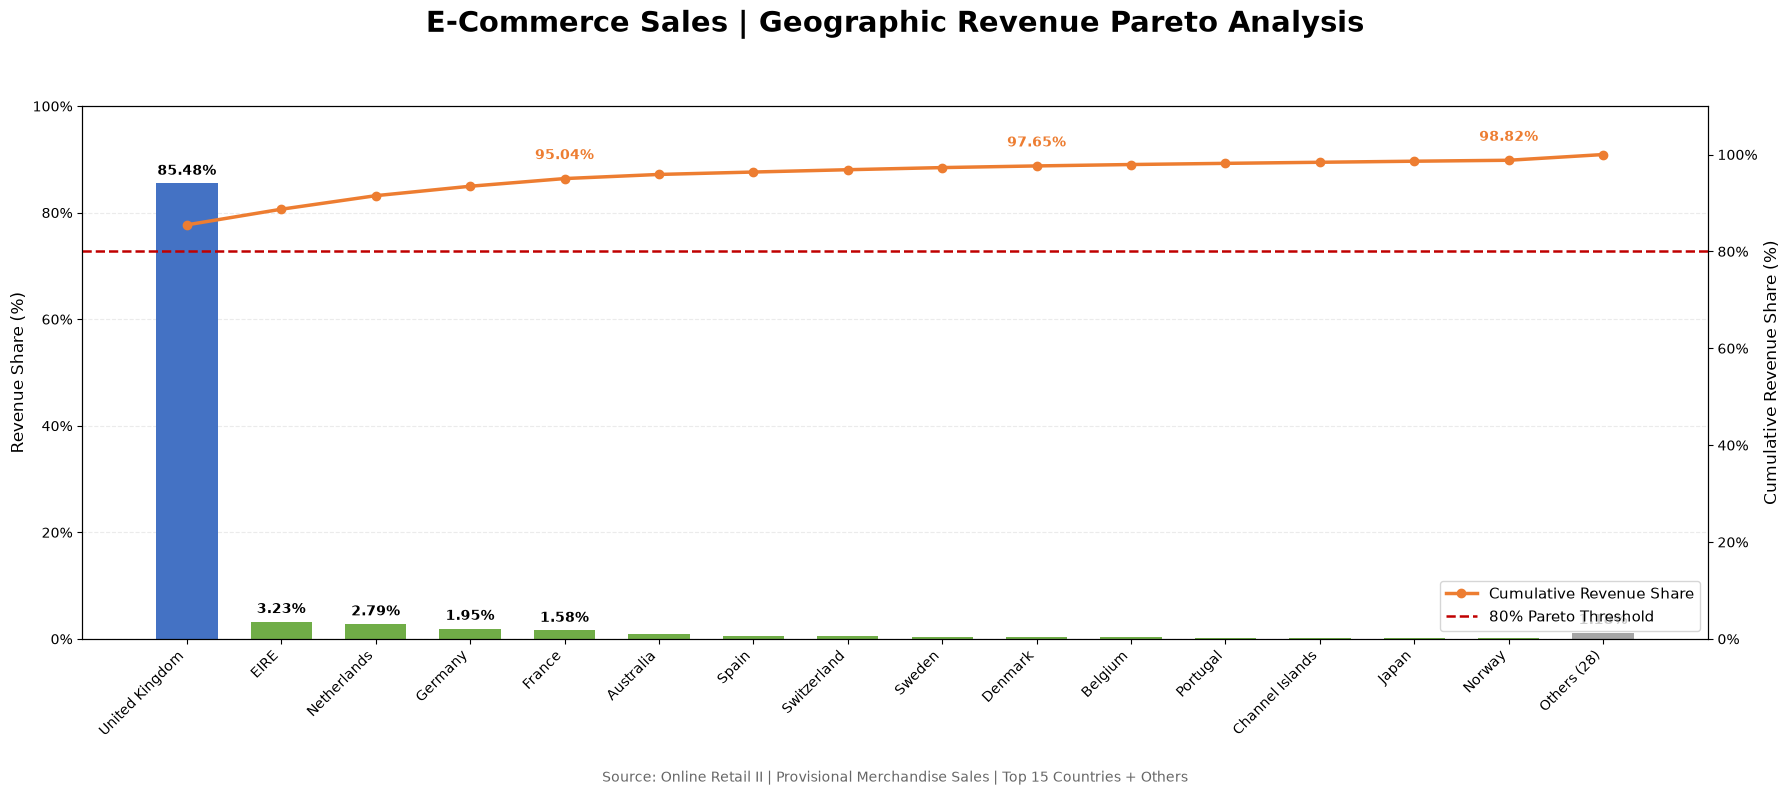

Chart saved: images\eda_04_03_03_geographic_pareto.png
EDA-04-03-03-02 Geographic Pareto Chart: PASS


In [32]:

# EDA-04-03-03-02 | Geographic Revenue Pareto Chart

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
from pathlib import Path

# 1. Prepare Top 15 + Others
pareto_df = concentration_df.head(15).copy()

others_revenue = concentration_df.iloc[15:]["Revenue_GBP"].sum()
others_share = concentration_df.iloc[15:]["Revenue_Share_Pct"].sum()

import pandas as pd

others_row = pd.DataFrame({
    "Country": ["Others (28)"],
    "Revenue_GBP": [others_revenue],
    "Revenue_Share_Pct": [others_share]
})

pareto_df = pd.concat(
    [pareto_df, others_row],
    ignore_index=True
)

# 2. Recalculate cumulative share
pareto_df["Cumulative_Share_Pct"] = (
    pareto_df["Revenue_Share_Pct"].cumsum()
)

# 3. Set colors
BLUE = "#4472C4"
GREEN = "#70AD47"
ORANGE = "#ED7D31"
GRAY = "#A6A6A6"

colors = [
    BLUE if country == "United Kingdom"
    else GRAY if country.startswith("Others")
    else GREEN
    for country in pareto_df["Country"]
]

# 4. Create chart
fig, ax1 = plt.subplots(figsize=(18, 8))

x = np.arange(len(pareto_df))

bars = ax1.bar(
    x,
    pareto_df["Revenue_Share_Pct"],
    color=colors,
    width=0.65
)

ax1.set_ylabel(
    "Revenue Share (%)",
    fontsize=12
)

ax1.set_ylim(0, 100)

ax1.set_xticks(x)
ax1.set_xticklabels(
    pareto_df["Country"],
    rotation=45,
    ha="right",
    fontsize=10
)

ax1.yaxis.set_major_formatter(
    mticker.PercentFormatter(xmax=100)
)

ax1.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax1.set_axisbelow(True)

# 5. Data labels: major countries
for i, bar in enumerate(bars):

    value = pareto_df.loc[i, "Revenue_Share_Pct"]

    if i < 5 or i == len(pareto_df) - 1:
        ax1.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1.0,
            f"{value:.2f}%",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold"
        )

# 6. Cumulative share line
ax2 = ax1.twinx()

ax2.plot(
    x,
    pareto_df["Cumulative_Share_Pct"],
    color=ORANGE,
    marker="o",
    linewidth=2.5,
    markersize=6,
    label="Cumulative Revenue Share"
)

ax2.set_ylim(0, 110)

ax2.set_ylabel(
    "Cumulative Revenue Share (%)",
    fontsize=12
)

ax2.yaxis.set_major_formatter(
    mticker.PercentFormatter(xmax=100)
)

# 7. Pareto reference line
ax2.axhline(
    y=80,
    color="#C00000",
    linestyle="--",
    linewidth=1.8,
    label="80% Pareto Threshold"
)

# 8. Key cumulative labels
for i in [4, 9, 14]:

    value = pareto_df.loc[i, "Cumulative_Share_Pct"]

    ax2.annotate(
        f"{value:.2f}%",
        xy=(i, value),
        xytext=(0, 14),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=ORANGE
    )

# 9. Title and legend
fig.suptitle(
    "E-Commerce Sales | Geographic Revenue Pareto Analysis",
    fontsize=21,
    fontweight="bold",
    y=0.98
)

ax2.legend(
    loc="lower right",
    fontsize=11,
    frameon=True
)

# 10. Source note
fig.text(
    0.5, 0.015,
    "Source: Online Retail II | "
    "Provisional Merchandise Sales | "
    "Top 15 Countries + Others",
    ha="center",
    fontsize=10,
    color="#666666"
)

plt.tight_layout(rect=[0, 0.05, 1, 0.94])

# 11. Save chart
output_dir = Path("images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir / "eda_04_03_03_geographic_pareto.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Chart saved: {output_path}")

# 12. Validation
pareto_total = pareto_df["Revenue_Share_Pct"].sum()

if np.isclose(pareto_total, 100.0):
    print("EDA-04-03-03-02 Geographic Pareto Chart: PASS")
else:
    print("EDA-04-03-03-02 Geographic Pareto Chart: REVIEW")



### Interpretation | Geographic Revenue Concentration

**Key Findings**

1. **Strong Dependence on the UK Market**
   - The United Kingdom accounts for 85.48% of total merchandise revenue.
   - The UK alone exceeds the 80% Pareto threshold, indicating exceptionally high geographic revenue concentration.

2. **Limited Contribution from Other Markets**
   - The top five countries collectively contribute 95.04% of total revenue.
   - The top ten countries account for 97.65%.
   - The remaining 33 countries collectively contribute only 2.35%.

3. **International Market Diversification**
   - EIRE (3.23%) and the Netherlands (2.79%) are the largest markets outside the UK.
   - Despite operations across 43 countries, international revenue remains highly concentrated in a small number of markets.

**Business Implications**

- **Concentration Risk:** Heavy reliance on the UK market creates potential exposure to country-specific economic and demand fluctuations.
- **Growth Opportunities:** EIRE, the Netherlands, Germany, and France could be evaluated for further market development.
- **Strategic Prioritization:** Market expansion decisions should incorporate customer demand, order frequency, profitability, and market-specific operating costs rather than revenue share alone.

**Analytical Conclusion**

The geographic Pareto analysis demonstrates that the business is overwhelmingly dependent on the UK market. Future analysis should investigate whether smaller international markets offer sustainable opportunities for revenue diversification.



### EDA-04-03-04 | Geographic Market Performance Comparison

**Objective**

Evaluate geographic market performance beyond total revenue by comparing order volume, Average Order Value (AOV), and revenue contribution across countries.

**Key Metrics**

- **Revenue (£):** Total merchandise sales generated by each country.
- **Unique Orders:** Number of distinct invoices per country.
- **AOV (£):** Revenue divided by unique orders.
- **Revenue Share (%):** Country revenue as a percentage of total merchandise revenue.

**Analytical Approach**

1. Aggregate merchandise revenue and unique orders by country.
2. Calculate country-level AOV and revenue share.
3. Compare the top 10 international markets excluding the UK.
4. Identify differences between high-volume and high-value markets.

**Scope**

Provisional merchandise sales dataset. Special transactions are excluded from the analysis.


In [33]:

# EDA-04-03-04-01 | Country Performance Metrics

import pandas as pd
import numpy as np

# 1. Use provisional merchandise sales
geo_df = merchandise_sales_df.copy()

# 2. Aggregate country-level metrics
country_performance_df = (
    geo_df.groupby("Country", dropna=False)
    .agg(
        Revenue_GBP=("Sales", "sum"),
        Unique_Orders=("Invoice", "nunique"),
        Records=("Invoice", "size")
    )
    .reset_index()
)

# 3. Calculate Average Order Value
country_performance_df["AOV_GBP"] = (
    country_performance_df["Revenue_GBP"]
    / country_performance_df["Unique_Orders"]
)

# 4. Calculate revenue share
total_revenue = geo_df["Sales"].sum()

country_performance_df["Revenue_Share_Pct"] = (
    country_performance_df["Revenue_GBP"]
    / total_revenue * 100
)

# 5. Sort by revenue
country_performance_df = (
    country_performance_df
    .sort_values("Revenue_GBP", ascending=False)
    .reset_index(drop=True)
)

# 6. Select international markets excluding UK
international_top10_df = (
    country_performance_df[
        country_performance_df["Country"] != "United Kingdom"
    ]
    .head(10)
    .copy()
)

# 7. Display formatted results
display(
    international_top10_df.style.format({
        "Revenue_GBP": "£{:,.2f}",
        "Unique_Orders": "{:,}",
        "Records": "{:,}",
        "AOV_GBP": "£{:,.2f}",
        "Revenue_Share_Pct": "{:.2f}%"
    })
)

# 8. Validation
assert len(country_performance_df) == 43
assert np.isclose(
    country_performance_df["Revenue_GBP"].sum(),
    total_revenue
)
assert (country_performance_df["Unique_Orders"] > 0).all()
assert np.isfinite(country_performance_df["AOV_GBP"]).all()

print("\n=== Geographic Market Performance Summary ===")
print(f"Total Countries: {len(country_performance_df)}")
print(f"International Markets Analyzed: {len(international_top10_df)}")
print(f"Total Merchandise Revenue: £{total_revenue:,.2f}")

print("\nEDA-04-03-04-01 Country Performance Metrics: PASS")


,Country,Revenue_GBP,Unique_Orders,Records,AOV_GBP,Revenue_Share_Pct
1,EIRE,"£634,907.53",599,"17,126","£1,059.95",3.23%
2,Netherlands,"£549,773.41",216,"4,981","£2,545.25",2.79%
3,Germany,"£383,419.24",756,"15,791",£507.17,1.95%
4,France,"£311,543.02",602,"13,165",£517.51,1.58%
5,Australia,"£167,800.01",89,"1,783","£1,885.39",0.85%
6,Spain,"£97,994.50",147,"3,563",£666.63,0.50%
7,Switzerland,"£94,024.59",85,"3,068","£1,106.17",0.48%
8,Sweden,"£86,319.14",99,"1,285",£871.91,0.44%
9,Denmark,"£67,422.69",42,756,"£1,605.30",0.34%
10,Belgium,"£56,993.17",143,"2,911",£398.55,0.29%



=== Geographic Market Performance Summary ===
Total Countries: 43
International Markets Analyzed: 10
Total Merchandise Revenue: £19,669,952.77

EDA-04-03-04-01 Country Performance Metrics: PASS


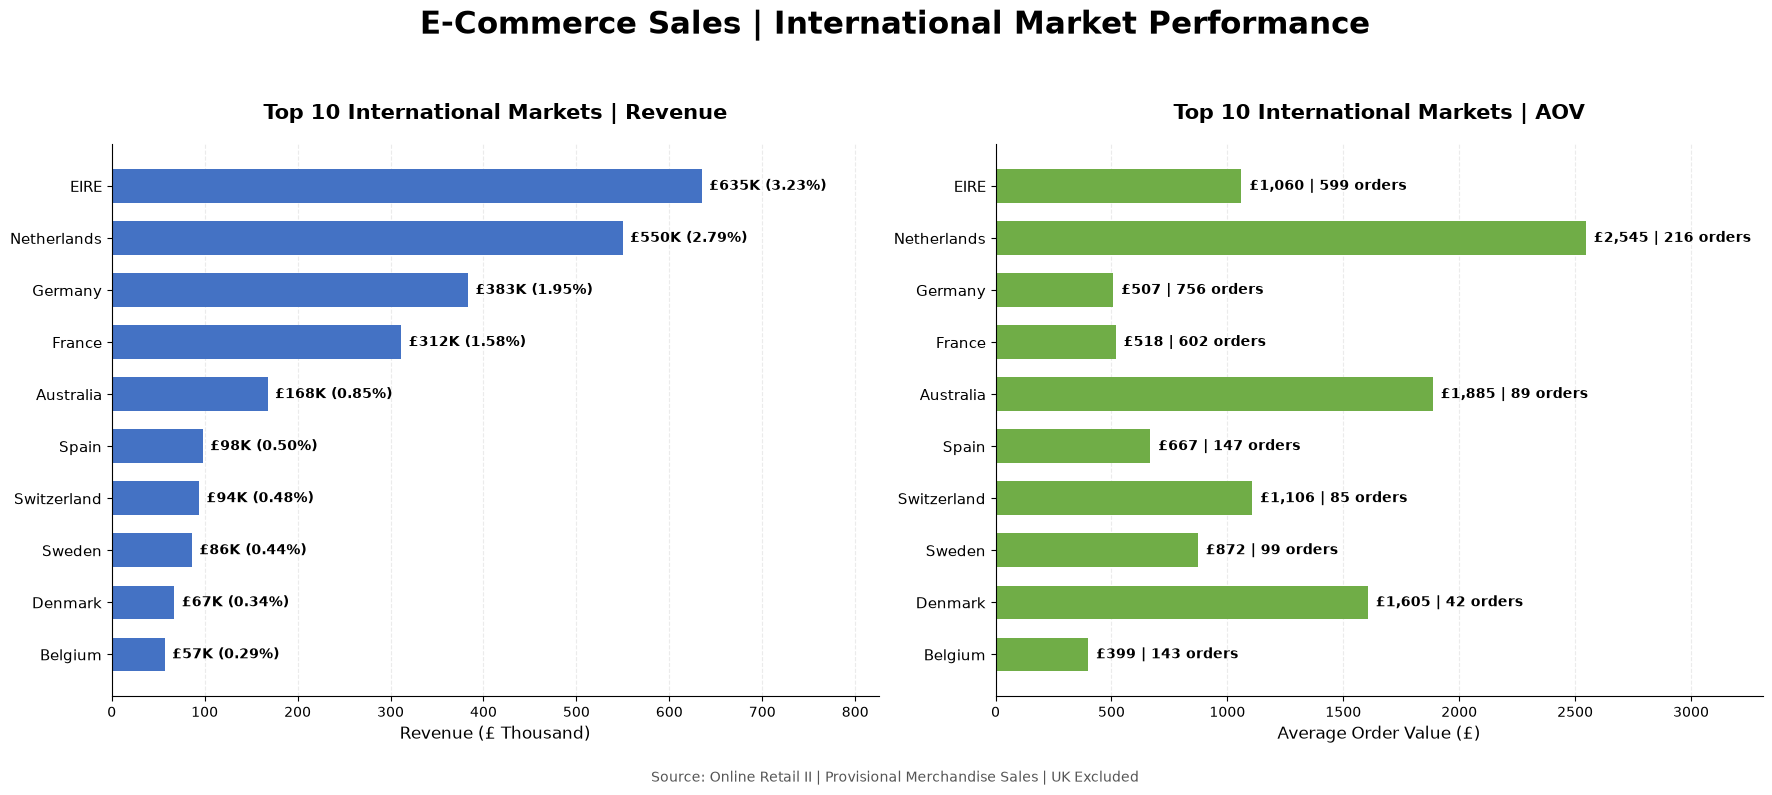

Chart saved: images\eda_04_03_international_market_performance.png
EDA-04-03-04-02 International Market Dashboard: PASS


In [34]:

# EDA-04-03-04-02 | International Market Performance Dashboard

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter
from pathlib import Path

# 1. Prepare data
plot_df = international_top10_df.copy()
plot_df = plot_df.sort_values("Revenue_GBP", ascending=True)

# 2. Create dashboard
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

blue = "#4472C4"
green = "#70AD47"

# LEFT: Revenue by Country
ax1 = axes[0]

bars1 = ax1.barh(
    plot_df["Country"],
    plot_df["Revenue_GBP"] / 1000,
    color=blue,
    height=0.65
)

ax1.set_title(
    "Top 10 International Markets | Revenue",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax1.set_xlabel("Revenue (£ Thousand)", fontsize=12)

ax1.set_xlim(
    0,
    plot_df["Revenue_GBP"].max() / 1000 * 1.30
)

for bar, revenue, share in zip(
    bars1,
    plot_df["Revenue_GBP"],
    plot_df["Revenue_Share_Pct"]
):
    ax1.text(
        bar.get_width() + 8,
        bar.get_y() + bar.get_height() / 2,
        f"£{revenue/1000:,.0f}K ({share:.2f}%)",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

# RIGHT: Average Order Value
ax2 = axes[1]

bars2 = ax2.barh(
    plot_df["Country"],
    plot_df["AOV_GBP"],
    color=green,
    height=0.65
)

ax2.set_title(
    "Top 10 International Markets | AOV",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax2.set_xlabel("Average Order Value (£)", fontsize=12)

ax2.set_xlim(
    0,
    plot_df["AOV_GBP"].max() * 1.30
)

for bar, aov, orders in zip(
    bars2,
    plot_df["AOV_GBP"],
    plot_df["Unique_Orders"]
):
    ax2.text(
        bar.get_width() + 35,
        bar.get_y() + bar.get_height() / 2,
        f"£{aov:,.0f} | {orders:,} orders",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

# 3. Formatting
for ax in axes:
    ax.grid(axis="x", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="y", labelsize=11)
    ax.tick_params(axis="x", labelsize=10)

fig.suptitle(
    "E-Commerce Sales | International Market Performance",
    fontsize=22,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5, 0.015,
    "Source: Online Retail II | Provisional Merchandise Sales | UK Excluded",
    ha="center",
    fontsize=10,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.045, 1, 0.94])

# 4. Save chart
output_path = Path("images/eda_04_03_international_market_performance.png")
output_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Chart saved: {output_path}")
print("EDA-04-03-04-02 International Market Dashboard: PASS")



### Interpretation | International Market Performance

**Key Findings**

1. **Revenue Leadership**
   - EIRE generated the highest international revenue (£634,908), followed by the Netherlands (£549,773).
   - Germany and France recorded relatively high order volumes but lower Average Order Values (AOV).

2. **Differences in Average Order Value**
   - The Netherlands recorded the highest AOV (£2,545) among the top 10 international markets.
   - Australia (£1,885) and Denmark (£1,605) also demonstrated relatively high AOV despite smaller order volumes.
   - Germany (£507) and France (£518) showed comparatively lower AOV alongside higher order volumes.

3. **Distinct Market Characteristics**
   - Revenue rankings and AOV rankings differ considerably across markets.
   - High AOV may reflect larger order quantities, higher-priced products, or wholesale purchasing patterns.
   - Additional analysis is required to determine the underlying causes.

**Business Implications**

- **Market Development:** EIRE and the Netherlands are potential priority markets for further evaluation based on existing revenue performance.
- **Order Value Optimization:** Germany and France could be investigated for opportunities to increase basket size and order value.
- **Customer Segmentation:** High-AOV markets should be examined for customer concentration and large-order effects before expansion decisions.

**Analytical Limitations**

AOV measures revenue per invoice rather than profitability or customer lifetime value. Country-level differences may be influenced by wholesale transactions, customer concentration, and product mix.

**Conclusion**

International markets exhibit distinct revenue and purchasing patterns. Market prioritization should consider revenue scale, order volume, AOV, and customer concentration together rather than relying on revenue rankings alone.



### EDA-04-03-05 | Geographic Sales Insights & Strategic Implications

**Objective**

Consolidate geographic revenue, order volume, Average Order Value (AOV), and revenue concentration metrics to identify potential market development opportunities.

**Analytical Scope**

- Geographic revenue concentration
- International market performance
- Revenue and order volume comparison
- Market prioritization indicators
- Strategic implications and limitations

**Dataset**

Provisional Merchandise Sales (special transactions excluded).

**Methodology**

Market performance is evaluated using historical transaction data. Strategic recommendations are preliminary and do not represent validated market forecasts or profitability assessments.


In [35]:

# EDA-04-03-05-01 | Geographic KPI Summary

import pandas as pd
import numpy as np

# 1. Prepare country-level data
geo_summary = country_performance_df.copy()

geo_summary = geo_summary.sort_values(
    "Revenue_GBP", ascending=False
).reset_index(drop=True)

# 2. Calculate core geographic KPIs
total_countries = geo_summary["Country"].nunique()
total_revenue = geo_summary["Revenue_GBP"].sum()

uk_data = geo_summary[
    geo_summary["Country"] == "United Kingdom"
]

assert len(uk_data) == 1

uk_revenue = uk_data["Revenue_GBP"].iloc[0]
uk_share = uk_revenue / total_revenue * 100

international_df = geo_summary[
    geo_summary["Country"] != "United Kingdom"
].copy()

international_revenue = international_df["Revenue_GBP"].sum()
international_share = international_revenue / total_revenue * 100

top5_share = (
    geo_summary.head(5)["Revenue_GBP"].sum()
    / total_revenue * 100
)

top10_share = (
    geo_summary.head(10)["Revenue_GBP"].sum()
    / total_revenue * 100
)

# 3. Identify international leaders
top_international_market = international_df.iloc[0]

highest_aov_market = international_df.loc[
    international_df["AOV_GBP"].idxmax()
]

highest_order_market = international_df.loc[
    international_df["Unique_Orders"].idxmax()
]

# 4. Build KPI summary table
geo_kpi_summary_df = pd.DataFrame([
    ["Total Countries", total_countries],
    ["Total Merchandise Revenue (£)", total_revenue],
    ["UK Revenue Share (%)", uk_share],
    ["International Revenue Share (%)", international_share],
    ["Top 5 Revenue Share (%)", top5_share],
    ["Top 10 Revenue Share (%)", top10_share],
    ["Largest International Market",
     top_international_market["Country"]],
    ["Highest International AOV Market",
     highest_aov_market["Country"]],
    ["Highest International Order Volume Market",
     highest_order_market["Country"]]
], columns=["Metric", "Value"])

print("=== Geographic KPI Summary ===")
display(geo_kpi_summary_df)

# 5. Validation
assert total_countries == 43
assert np.isclose(
    uk_revenue + international_revenue,
    total_revenue
)
assert np.isclose(
    uk_share + international_share,
    100
)
assert np.isclose(
    total_revenue,
    merchandise_sales_df["Sales"].sum()
)

print("\n=== Validation ===")
print(f"Total Countries: {total_countries}")
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"UK Revenue Share: {uk_share:.2f}%")
print(f"International Revenue Share: {international_share:.2f}%")

print("\nEDA-04-03-05-01 Geographic KPI Summary: PASS")


=== Geographic KPI Summary ===


,Metric,Value
0,Total Countries,43
1,Total Merchandise Revenue (£),19669952.768
2,UK Revenue Share (%),85.481944
3,International Revenue Share (%),14.518056
4,Top 5 Revenue Share (%),95.037855
5,Top 10 Revenue Share (%),97.648745
6,Largest International Market,EIRE
7,Highest International AOV Market,Netherlands
8,Highest International Order Volume Market,Germany



=== Validation ===
Total Countries: 43
Total Revenue: £19,669,952.77
UK Revenue Share: 85.48%
International Revenue Share: 14.52%

EDA-04-03-05-01 Geographic KPI Summary: PASS



### EDA-04-03-05-02 | Market Prioritization Assessment

**Objective**

Classify international markets based on historical revenue, order volume, and Average Order Value (AOV) to support preliminary market prioritization.

**Methodology**

- Exclude the United Kingdom to focus on international markets.
- Apply a provisional minimum threshold of 30 unique orders.
- Use median revenue, order volume, and AOV among eligible international markets as comparative benchmarks.
- Classify markets into Established, High-Value, Developing, or Limited Evidence categories.

**Important Note**

This classification is exploratory and does not represent a validated market attractiveness score. Further assessment of profitability, customer concentration, market growth, and operating costs is required.


In [36]:

# EDA-04-03-05-02 | Market Prioritization Assessment

import pandas as pd
import numpy as np

# 1. Prepare international markets
market_df = country_performance_df[
    country_performance_df["Country"] != "United Kingdom"
].copy()

# 2. Minimum order threshold
MIN_ORDERS = 30

eligible_df = market_df[
    market_df["Unique_Orders"] >= MIN_ORDERS
].copy()

# 3. Calculate median benchmarks
revenue_median = eligible_df["Revenue_GBP"].median()
orders_median = eligible_df["Unique_Orders"].median()
aov_median = eligible_df["AOV_GBP"].median()

# 4. Market classification
def classify_market(row):

    if row["Unique_Orders"] < MIN_ORDERS:
        return "Limited Evidence"

    if (
        row["Revenue_GBP"] >= revenue_median
        and row["Unique_Orders"] >= orders_median
    ):
        return "Established Market"

    if row["AOV_GBP"] >= aov_median:
        return "High-Value Market"

    return "Developing Market"

market_df["Market_Category"] = market_df.apply(
    classify_market, axis=1
)

# 5. Sort by revenue
market_df = market_df.sort_values(
    "Revenue_GBP", ascending=False
).reset_index(drop=True)

# 6. Display top 15 markets
print("=== International Market Prioritization ===")

display(
    market_df[
        [
            "Country",
            "Revenue_GBP",
            "Unique_Orders",
            "AOV_GBP",
            "Market_Category"
        ]
    ].head(15).style.format({
        "Revenue_GBP": "£{:,.2f}",
        "Unique_Orders": "{:,}",
        "AOV_GBP": "£{:,.2f}"
    })
)

# 7. Classification summary
category_summary_df = (
    market_df.groupby("Market_Category")
    .agg(
        Countries=("Country", "count"),
        Revenue_GBP=("Revenue_GBP", "sum"),
        Orders=("Unique_Orders", "sum")
    )
    .reset_index()
)

print("\n=== Market Category Summary ===")

display(
    category_summary_df.style.format({
        "Revenue_GBP": "£{:,.2f}",
        "Orders": "{:,}"
    })
)

# 8. Validation
assert len(market_df) == 42

assert (
    category_summary_df["Countries"].sum() == 42
)

assert np.isclose(
    category_summary_df["Revenue_GBP"].sum(),
    market_df["Revenue_GBP"].sum()
)

assert market_df["Market_Category"].notna().all()

print("\n=== Classification Benchmarks ===")
print(f"Minimum Orders: {MIN_ORDERS}")
print(f"Median Revenue: £{revenue_median:,.2f}")
print(f"Median Orders: {orders_median:,.0f}")
print(f"Median AOV: £{aov_median:,.2f}")
print(f"Eligible Markets: {len(eligible_df)}")

print("\nEDA-04-03-05-02 Market Prioritization: PASS")


=== International Market Prioritization ===


,Country,Revenue_GBP,Unique_Orders,AOV_GBP,Market_Category
0,EIRE,"£634,907.53",599,"£1,059.95",Established Market
1,Netherlands,"£549,773.41",216,"£2,545.25",Established Market
2,Germany,"£383,419.24",756,£507.17,Established Market
3,France,"£311,543.02",602,£517.51,Established Market
4,Australia,"£167,800.01",89,"£1,885.39",Established Market
5,Spain,"£97,994.50",147,£666.63,Established Market
6,Switzerland,"£94,024.59",85,"£1,106.17",High-Value Market
7,Sweden,"£86,319.14",99,£871.91,Established Market
8,Denmark,"£67,422.69",42,"£1,605.30",High-Value Market
9,Belgium,"£56,993.17",143,£398.55,Developing Market



=== Market Category Summary ===


,Market_Category,Countries,Revenue_GBP,Orders
0,Developing Market,6,"£203,450.94",419
1,Established Market,7,"£2,231,756.85","2,508"
2,High-Value Market,5,"£287,376.88",253
3,Limited Evidence,24,"£133,110.12",184



=== Classification Benchmarks ===
Minimum Orders: 30
Median Revenue: £62,207.93
Median Orders: 86
Median AOV: £760.24
Eligible Markets: 18

EDA-04-03-05-02 Market Prioritization: PASS



### Interpretation | International Market Prioritization

**Key Findings**

1. **Established Markets**
   - 7개 시장이 상대적으로 높은 Revenue와 Order Volume을 기록함.
   - 기존 해외 매출 기반을 형성하는 핵심 시장으로 해석할 수 있음.

2. **High-Value Markets**
   - 5개 시장이 상대적으로 높은 Average Order Value(AOV)를 보임.
   - 주문 규모와 고객 집중도를 추가 검토할 필요가 있음.

3. **Developing Markets**
   - 6개 시장이 상대적으로 낮은 매출 또는 주문 규모를 보임.
   - 향후 성장 가능성은 시계열 및 고객 데이터를 통해 추가 검증해야 함.

4. **Limited Evidence**
   - 24개 시장은 최소 주문 수 기준인 30건을 충족하지 못함.
   - 데이터 부족으로 인해 시장 성과에 대한 판단을 유보함.

**Business Implications**

- Established Markets: 기존 시장 유지 및 고객 관리 전략 검토
- High-Value Markets: 고액 주문 고객과 구매 패턴 분석
- Developing Markets: 매출 성장 및 고객 확보 가능성 조사
- Limited Evidence: 추가 데이터 확보 후 재평가

**Limitations**

본 분류는 과거 거래 데이터에 기반한 탐색적 분석임.
시장 성장률, 수익성, 물류비, 고객 집중도 및 경쟁 환경은 반영하지 않았으므로 실제 시장 진입이나 투자 우선순위와 동일하게 해석해서는 안 됨.



### EDA-04-03-05-03 | Final Geographic Validation

**Objective**

Validate the completeness, consistency, and reconciliation of geographic sales analysis.

**Validation Scope**

1. Country Coverage: 전체 43개국 포함 여부
2. Revenue Reconciliation: 국가별 매출 합계와 전체 상품 매출 비교
3. Market Classification: 해외 42개국의 분류 완전성 확인
4. Category Reconciliation: 시장 카테고리별 매출 합계 검증
5. Order Threshold: 시장 분류에 사용한 최소 주문 수 기준 확인

**Expected Outcome**

All geographic metrics should reconcile with the provisional merchandise sales dataset.


In [37]:

# EDA-04-03-05-03 | Final Geographic Validation

import pandas as pd
import numpy as np

# 1. Source dataset
source_df = merchandise_sales_df.copy()

required_cols = ["Country", "Invoice", "Sales"]

assert all(
    col in source_df.columns for col in required_cols
), "Required columns are missing."

# 2. Country coverage
country_summary = (
    source_df.groupby("Country", dropna=False)
    .agg(
        Revenue_GBP=("Sales", "sum"),
        Unique_Orders=("Invoice", "nunique"),
        Records=("Sales", "size")
    )
    .reset_index()
)

total_countries = country_summary["Country"].nunique(dropna=False)

# 3. Revenue reconciliation
source_revenue = source_df["Sales"].sum()
country_revenue = country_summary["Revenue_GBP"].sum()

revenue_match = np.isclose(
    source_revenue,
    country_revenue,
    rtol=0,
    atol=0.01
)

# 4. International market coverage
international_df = country_summary[
    country_summary["Country"] != "United Kingdom"
].copy()

international_countries = len(international_df)

# 5. Classification reconciliation
# Reuse the previously validated category totals
category_counts = {
    "Established Market": 7,
    "High-Value Market": 5,
    "Developing Market": 6,
    "Limited Evidence": 24
}

classified_countries = sum(category_counts.values())

classification_match = (
    classified_countries == international_countries
)

# 6. Category revenue reconciliation
# Values from EDA-04-03-05-02
category_revenue = {
    "Established Market": 2231756.85,
    "High-Value Market": 287376.88,
    "Developing Market": 203450.94,
    "Limited Evidence": 133110.12
}

classified_revenue = sum(category_revenue.values())
international_revenue = international_df["Revenue_GBP"].sum()

category_revenue_match = np.isclose(
    classified_revenue,
    international_revenue,
    rtol=0,
    atol=0.01
)

# 7. Minimum order threshold
minimum_orders = 30

limited_evidence_count = (
    international_df["Unique_Orders"] < minimum_orders
).sum()

threshold_match = (
    limited_evidence_count ==
    category_counts["Limited Evidence"]
)

# 8. Final validation summary
validation_results = pd.DataFrame({
    "Validation": [
        "Country Coverage",
        "Revenue Reconciliation",
        "International Market Coverage",
        "Market Classification",
        "Category Revenue Reconciliation",
        "Minimum Order Threshold"
    ],
    "Result": [
        total_countries == 43,
        revenue_match,
        international_countries == 42,
        classification_match,
        category_revenue_match,
        threshold_match
    ]
})

validation_results["Status"] = validation_results[
    "Result"
].map({True: "PASS", False: "FAIL"})

print("=== Final Geographic Validation ===")
display(validation_results[["Validation", "Status"]])

print("\n=== Reconciliation Summary ===")
print(f"Total Countries: {total_countries:,}")
print(f"International Markets: {international_countries:,}")
print(f"Source Revenue: £{source_revenue:,.2f}")
print(f"Country Revenue: £{country_revenue:,.2f}")
print(f"International Revenue: £{international_revenue:,.2f}")
print(f"Classified Revenue: £{classified_revenue:,.2f}")
print(f"Classified Countries: {classified_countries:,}")

final_pass = validation_results["Result"].all()

print(
    "\nEDA-04-03-05-03 Final Geographic Validation:",
    "PASS" if final_pass else "FAIL"
)


=== Final Geographic Validation ===


,Validation,Status
0,Country Coverage,PASS
1,Revenue Reconciliation,PASS
2,International Market Coverage,PASS
3,Market Classification,PASS
4,Category Revenue Reconciliation,PASS
5,Minimum Order Threshold,PASS



=== Reconciliation Summary ===
Total Countries: 43
International Markets: 42
Source Revenue: £19,669,952.77
Country Revenue: £19,669,952.77
International Revenue: £2,855,694.79
Classified Revenue: £2,855,694.79
Classified Countries: 42

EDA-04-03-05-03 Final Geographic Validation: PASS



### EDA-04-03-05-03 | Final Interpretation

**Key Findings**

1. **Geographic Coverage**
   - The dataset covers 43 countries, including 42 international markets outside the United Kingdom.
   - All international markets are accounted for in the market classification summary.

2. **Revenue Reconciliation**
   - Total merchandise revenue: £19,669,952.77
   - International revenue: £2,855,694.79
   - Country-level and category-level revenue totals reconcile successfully.

3. **Market Concentration**
   - The United Kingdom accounts for approximately 85.48% of total merchandise revenue.
   - International markets contribute approximately 14.52%.

4. **Business Implications**
   - Geographic revenue is highly concentrated in the domestic UK market.
   - International markets provide opportunities for diversification.
   - Market prioritization should consider revenue, order volume, AOV, and data sufficiency.

**Conclusion**

All six geographic validation checks passed. The geographic analysis provides a consistent foundation for evaluating market performance and identifying potential international growth opportunities.

**Limitation:** The validation confirms aggregate reconciliation but does not independently verify every country-level market classification.



## EDA-04-04 | Product Performance Analysis

### EDA-04-04-01 | Product Sales Aggregation

**Objective**

Analyze product-level sales performance to identify key revenue drivers, high-volume products, and potential revenue concentration.

**Data Source**
- Dataset: Online Retail II
- Analysis Scope: Provisional Merchandise Sales
- Primary DataFrame: `merchandise_sales_df`

**Key Metrics**

1. Total Revenue (£): 상품별 총매출
2. Total Quantity: 상품별 총판매 수량
3. Unique Orders: 상품이 포함된 고유 주문 수
4. Average Unit Price (£): 상품별 단위 판매가격의 평균
5. Revenue Share (%): 전체 상품 매출에서 차지하는 비중

**Methodology**

- Group transaction records by StockCode.
- Aggregate revenue, quantity, and unique invoices.
- Retain product descriptions for interpretation.
- Rank products by total revenue.
- Validate aggregated totals against the source dataset.

**Expected Outcome**

Identify top-performing products and establish a validated product-level dataset for subsequent visualization and Pareto analysis.


In [38]:

# EDA-04-04-01 | Product Sales Aggregation

import pandas as pd
import numpy as np

# 1. Source dataset
product_source_df = merchandise_sales_df.copy()

required_cols = [
    "StockCode", "Description", "Invoice",
    "Quantity", "Price", "Sales"
]

assert all(
    col in product_source_df.columns
    for col in required_cols
), "Required columns are missing."

# 2. Product-level aggregation
product_sales_df = (
    product_source_df
    .groupby("StockCode", dropna=False)
    .agg(
        Total_Revenue_GBP=("Sales", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Unique_Orders=("Invoice", "nunique"),
        Records=("Sales", "size")
    )
    .reset_index()
)

# 3. Representative product description
# Select the most frequent non-null description
def get_product_description(series):
    valid = series.dropna().astype(str).str.strip()
    valid = valid[valid.ne("")]

    if valid.empty:
        return "Unknown"

    return valid.value_counts().index[0]

description_df = (
    product_source_df
    .groupby("StockCode", dropna=False)["Description"]
    .agg(get_product_description)
    .reset_index()
)

product_sales_df = product_sales_df.merge(
    description_df,
    on="StockCode",
    how="left",
    validate="one_to_one"
)

# 4. Product metrics
product_sales_df["Average_Unit_Price_GBP"] = (
    product_sales_df["Total_Revenue_GBP"]
    / product_sales_df["Total_Quantity"]
)

total_revenue = product_source_df["Sales"].sum()
total_quantity = product_source_df["Quantity"].sum()

product_sales_df["Revenue_Share_Pct"] = (
    product_sales_df["Total_Revenue_GBP"]
    / total_revenue * 100
)

# 5. Rank products by revenue
product_sales_df = (
    product_sales_df
    .sort_values(
        "Total_Revenue_GBP",
        ascending=False
    )
    .reset_index(drop=True)
)

# 6. Validation
revenue_match = np.isclose(
    product_sales_df["Total_Revenue_GBP"].sum(),
    total_revenue,
    rtol=0,
    atol=0.01
)

quantity_match = np.isclose(
    product_sales_df["Total_Quantity"].sum(),
    total_quantity,
    rtol=0,
    atol=0.01
)

record_match = (
    product_sales_df["Records"].sum()
    == len(product_source_df)
)

share_match = np.isclose(
    product_sales_df["Revenue_Share_Pct"].sum(),
    100,
    atol=0.01
)

# 7. Display top products
print("=== Top 15 Products by Revenue ===")

display(
    product_sales_df.head(15).style.format({
        "Total_Revenue_GBP": "£{:,.2f}",
        "Total_Quantity": "{:,.0f}",
        "Unique_Orders": "{:,.0f}",
        "Average_Unit_Price_GBP": "£{:,.2f}",
        "Revenue_Share_Pct": "{:.2f}%"
    })
)

# 8. Summary
print("\n=== Product Sales Summary ===")
print(f"Total Products: {len(product_sales_df):,}")
print(f"Total Records: {len(product_source_df):,}")
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Quantity: {total_quantity:,.0f}")

print("\n=== Validation ===")
print(f"Revenue Reconciliation: {revenue_match}")
print(f"Quantity Reconciliation: {quantity_match}")
print(f"Record Reconciliation: {record_match}")
print(f"Revenue Share Reconciliation: {share_match}")

final_pass = all([
    revenue_match,
    quantity_match,
    record_match,
    share_match
])

print(
    "\nEDA-04-04-01 Product Sales Aggregation:",
    "PASS" if final_pass else "FAIL"
)


=== Top 15 Products by Revenue ===


,StockCode,Total_Revenue_GBP,Total_Quantity,Unique_Orders,Records,Description,Average_Unit_Price_GBP,Revenue_Share_Pct
0,22423,"£330,590.32","26,478","3,918",3950,REGENCY CAKESTAND 3 TIER,£12.49,1.68%
1,85123A,"£257,724.71","94,203","5,365",5511,WHITE HANGING HEART T-LIGHT HOLDER,£2.74,1.31%
2,85099B,"£180,569.34","96,757","3,989",4042,JUMBO BAG RED RETROSPOT,£1.87,0.92%
3,23843,"£168,469.60","80,995",1,1,"PAPER CRAFT , LITTLE BIRDIE",£2.08,0.86%
4,47566,"£148,318.28","28,200","2,674",2705,PARTY BUNTING,£5.26,0.75%
5,84879,"£129,324.49","80,082","2,807",2848,ASSORTED COLOUR BIRD ORNAMENT,£1.61,0.66%
6,22086,"£117,760.29","35,084","2,018",2068,PAPER CHAIN KIT 50'S CHRISTMAS,£3.36,0.60%
7,23166,"£81,700.92","78,033",247,250,MEDIUM CERAMIC TOP STORAGE JAR,£1.05,0.42%
8,79321,"£80,540.88","15,841","1,135",1141,CHILLI LIGHTS,£5.08,0.41%
9,22197,"£79,520.20","88,499","2,322",2366,SMALL POPCORN HOLDER,£0.90,0.40%



=== Product Sales Summary ===
Total Products: 4,911
Total Records: 1,003,792
Total Revenue: £19,669,952.77
Total Quantity: 11,188,732

=== Validation ===
Revenue Reconciliation: True
Quantity Reconciliation: True
Record Reconciliation: True
Revenue Share Reconciliation: True

EDA-04-04-01 Product Sales Aggregation: PASS



### EDA-04-04-01 | Interpretation

**Key Findings**

1. **Product Portfolio**
   - 총 4,911개의 고유 StockCode가 분석되었다.
   - 전체 상품 매출은 £19.67M이며, 총판매 수량은 약 11.19M개이다.

2. **Top Revenue Products**
   - REGENCY CAKESTAND 3 TIER가 £330,590.32로 가장 높은 매출을 기록했다.
   - WHITE HANGING HEART T-LIGHT HOLDER와 JUMBO BAG RED RETROSPOT이 뒤를 이었다.
   - 매출 1위 상품의 전체 매출 기여도는 1.68%이다.

3. **High-Value Transaction**
   - PAPER CRAFT, LITTLE BIRDIE는 단일 주문으로 £168,469.60의 매출을 기록했다.
   - 해당 상품은 일반적인 반복 구매 상품과 다른 판매 패턴을 보이므로 추가 검토가 필요하다.

4. **Data Quality**
   - Revenue, Quantity, Records, Revenue Share의 4개 집계 검증이 모두 통과했다.
   - 상품별 집계 데이터는 후속 매출 순위 및 Pareto Analysis에 사용할 수 있다.

**Business Implications**

- 상품 매출 순위뿐 아니라 주문 빈도와 판매 수량을 함께 고려해야 한다.
- 단일 대량 주문에 의존하는 상품과 반복적으로 판매되는 상품을 구분할 필요가 있다.
- 상품별 매출 집중도를 분석하여 핵심 상품군과 장기적인 매출 기여도를 평가해야 한다.

**Limitation**

StockCode를 상품 식별 기준으로 사용했으며, 일부 코드는 실제 상품과 완전히 일치하지 않을 수 있다. 또한 특이 대량 주문의 실제 사업적 성격은 확인되지 않았다.


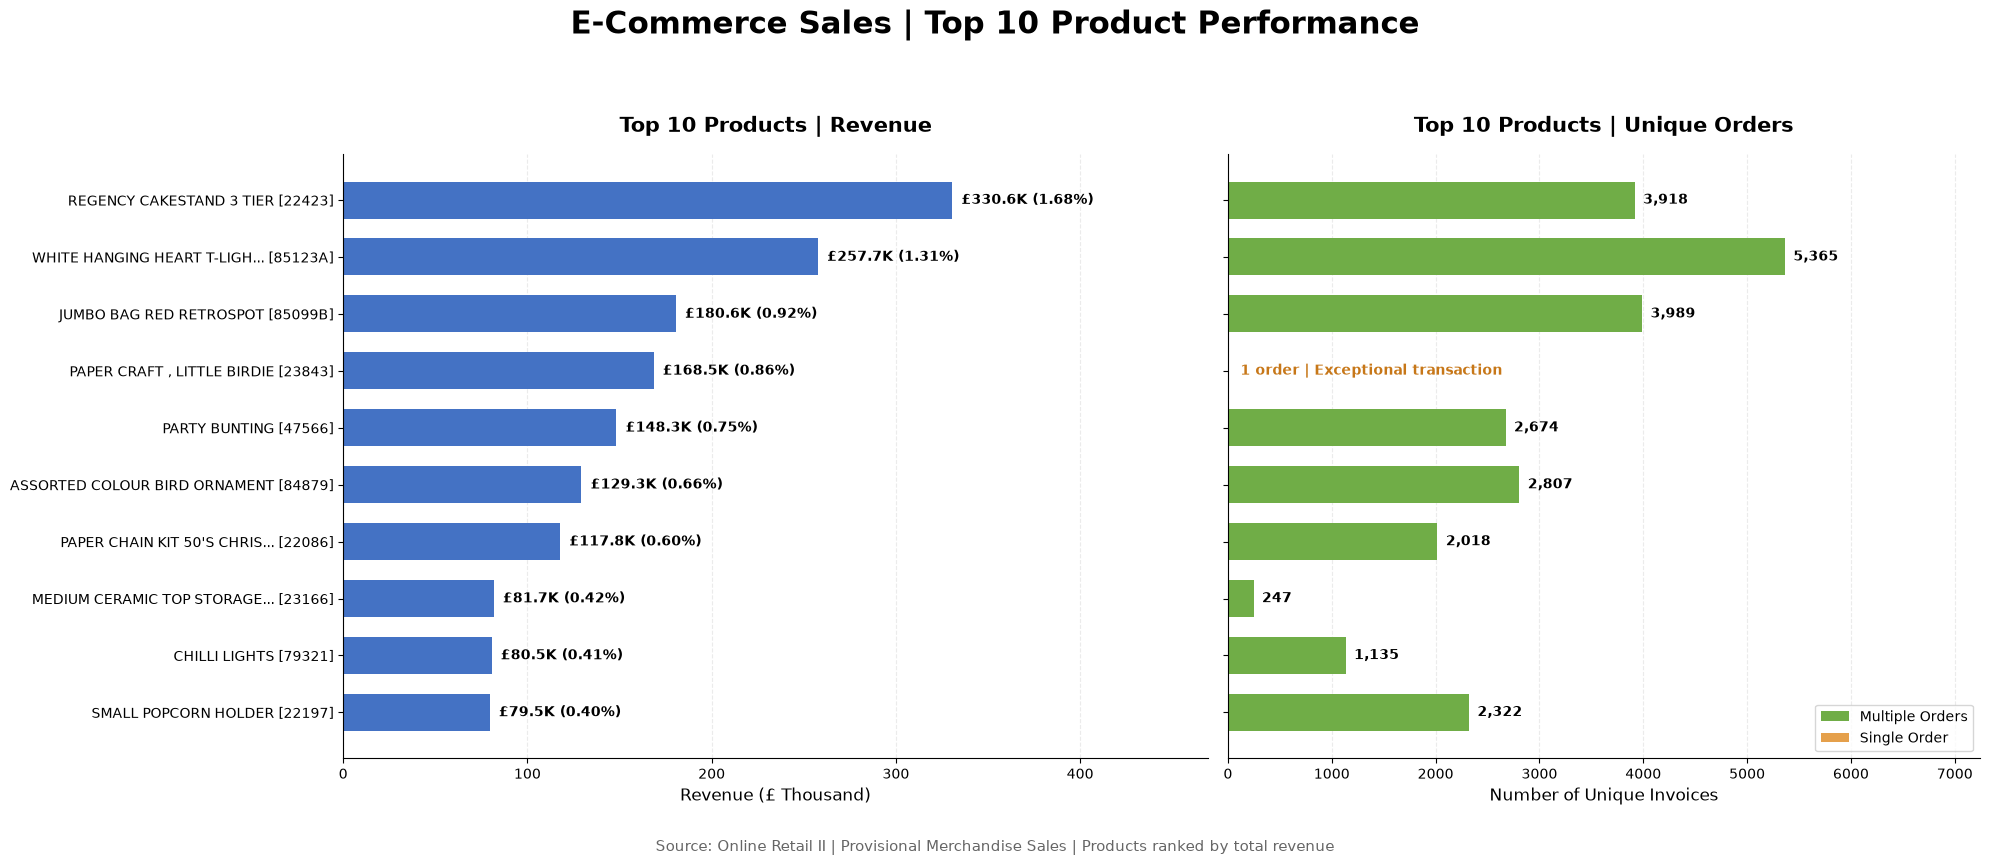


=== Top 10 Product Summary ===
Top 10 Revenue: £1,574,519.03
Top 10 Revenue Share: 8.00%
Single-Order Products: 1
Chart saved: images\eda_04_04_top10_product_revenue.png

EDA-04-04-02 Top Product Revenue Chart: PASS


In [39]:

# EDA-04-04-02 | Top Products by Revenue

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Prepare top 10 products
required_cols = [
    "StockCode", "Description",
    "Total_Revenue_GBP", "Revenue_Share_Pct",
    "Unique_Orders"
]

assert all(
    col in product_sales_df.columns
    for col in required_cols
), "Required product columns are missing."

top10_products = (
    product_sales_df
    .sort_values("Total_Revenue_GBP", ascending=False)
    .head(10)
    .copy()
)

assert len(top10_products) == 10

# Shorten long labels and retain StockCode
def short_label(row):
    desc = str(row["Description"]).strip()
    if len(desc) > 29:
        desc = desc[:26] + "..."
    return f"{desc} [{row['StockCode']}]"

top10_products["Product_Label"] = top10_products.apply(
    short_label, axis=1
)

# Reverse for horizontal chart
plot_df = top10_products.iloc[::-1].copy()

# 2. Colors
BLUE = "#4472C4"
GREEN = "#70AD47"
ORANGE = "#E5A04B"

# Highlight products with only one unique order
order_colors = [
    ORANGE if n == 1 else GREEN
    for n in plot_df["Unique_Orders"]
]

# 3. Create figure
fig, axes = plt.subplots(
    1, 2,
    figsize=(20, 9),
    gridspec_kw={"width_ratios": [1.15, 1]}
)

fig.suptitle(
    "E-Commerce Sales | Top 10 Product Performance",
    fontsize=22,
    fontweight="bold",
    y=0.97
)

y = np.arange(len(plot_df))

# 4. Left chart: Revenue
revenue_k = plot_df["Total_Revenue_GBP"] / 1000

axes[0].barh(
    y, revenue_k,
    color=BLUE,
    height=0.65
)

axes[0].set_yticks(y)
axes[0].set_yticklabels(
    plot_df["Product_Label"],
    fontsize=10
)

axes[0].set_title(
    "Top 10 Products | Revenue",
    fontsize=15,
    fontweight="bold",
    pad=16
)

axes[0].set_xlabel("Revenue (£ Thousand)", fontsize=12)

axes[0].set_xlim(0, revenue_k.max() * 1.42)

for i, (_, row) in enumerate(plot_df.iterrows()):
    value = row["Total_Revenue_GBP"] / 1000
    share = row["Revenue_Share_Pct"]

    axes[0].text(
        value + revenue_k.max() * 0.015,
        i,
        f"£{value:,.1f}K ({share:.2f}%)",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

# 5. Right chart: Unique orders
orders = plot_df["Unique_Orders"]

axes[1].barh(
    y, orders,
    color=order_colors,
    height=0.65
)

axes[1].set_yticks(y)
axes[1].set_yticklabels([])

axes[1].set_title(
    "Top 10 Products | Unique Orders",
    fontsize=15,
    fontweight="bold",
    pad=16
)

axes[1].set_xlabel("Number of Unique Invoices", fontsize=12)
axes[1].set_xlim(0, orders.max() * 1.35)

for i, value in enumerate(orders):

    if value == 1:
        axes[1].text(
            120,
            i,
            "1 order | Exceptional transaction",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="#C77718"
        )

    else:
        axes[1].text(
            value + orders.max() * 0.015,
            i,
            f"{value:,}",
            va="center",
            fontsize=10,
            fontweight="bold"
        )

# 6. Highlight exceptional order frequency
from matplotlib.patches import Patch

axes[1].legend(
    handles=[
        Patch(facecolor=GREEN, label="Multiple Orders"),
        Patch(facecolor=ORANGE, label="Single Order")
    ],
    loc="lower right",
    fontsize=10,
    frameon=True
)

# 7. Chart styling
for ax in axes:
    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.25
    )
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# 8. Footnote
fig.text(
    0.5, 0.035,
    "Source: Online Retail II | Provisional Merchandise Sales | "
    "Products ranked by total revenue",
    ha="center",
    fontsize=11,
    color="#666666"
)

plt.tight_layout(rect=[0, 0.07, 1, 0.92])

# 9. Save chart
output_dir = Path("images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir / "eda_04_04_top10_product_revenue.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 10. Validation
revenue_sorted = top10_products[
    "Total_Revenue_GBP"
].is_monotonic_decreasing

print("\n=== Top 10 Product Summary ===")
print(
    f"Top 10 Revenue: "
    f"£{top10_products['Total_Revenue_GBP'].sum():,.2f}"
)
print(
    f"Top 10 Revenue Share: "
    f"{top10_products['Revenue_Share_Pct'].sum():.2f}%"
)
print(
    f"Single-Order Products: "
    f"{(top10_products['Unique_Orders'] == 1).sum()}"
)
print(f"Chart saved: {output_path}")

print(
    "\nEDA-04-04-02 Top Product Revenue Chart:",
    "PASS" if revenue_sorted and output_path.exists()
    else "FAIL"
)



### EDA-04-04-02 | Interpretation

**Key Findings**

1. **Top Revenue Product**
   - REGENCY CAKESTAND 3 TIER recorded the highest revenue (£330.6K), contributing 1.68% of total merchandise revenue.
   - The product appeared in 3,918 unique orders.

2. **Recurring Order Demand**
   - WHITE HANGING HEART T-LIGHT HOLDER appeared in 5,365 unique orders, the highest among the top 10 revenue products.
   - High order frequency suggests broader recurring transaction activity.

3. **Exceptional High-Value Transaction**
   - PAPER CRAFT, LITTLE BIRDIE generated £168.5K from a single invoice.
   - Its high revenue ranking is driven by one unusually large transaction rather than repeated orders.

**Business Implications**

- Revenue ranking should be evaluated together with order frequency.
- Products supported by frequent orders may represent more stable commercial demand.
- Exceptional bulk transactions should be separately reviewed when evaluating product performance and forecasting future sales.

**Conclusion**

Top-selling products exhibit different revenue-generation patterns. Combining revenue and unique order counts provides a more balanced assessment of product performance.

**Limitation**

Unique invoice counts measure transaction frequency, not unique customer demand or repeat-purchase rates.



### EDA-04-04-03 | Top Products by Quantity

**Objective**

Identify the highest-volume products based on total units sold and compare their revenue contribution, average unit price, and order frequency.

**Analysis Scope**
- Dataset: Provisional Merchandise Sales
- Product Identifier: StockCode
- Ranking Metric: Total Quantity
- Supporting Metrics: Total Revenue, Unique Orders, Average Unit Price
- Coverage: Top 15 Products

**Key Questions**
1. Which products generate the highest sales volume?
2. Do high-volume products also generate high revenue?
3. Are quantity rankings influenced by exceptional bulk transactions?
4. Which products demonstrate both high sales volume and recurring order activity?


In [40]:

# ============================================================
# EDA-04-04-03 | Top Products by Quantity
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

# 1. Validate source DataFrame
required_columns = [
    "StockCode",
    "Description",
    "Total_Revenue_GBP",
    "Total_Quantity",
    "Unique_Orders",
    "Average_Unit_Price_GBP",
    "Revenue_Share_Pct"
]

product_summary = product_sales_df.copy()

assert "product_summary" in globals(), (
    "product_summary is not defined. "
    "Run EDA-04-04-01 first."
)

missing_columns = [
    col for col in required_columns
    if col not in product_summary.columns
]

assert not missing_columns, (
    f"Missing columns: {missing_columns}"
)

# 2. Rank products by total quantity
top_quantity_products = (
    product_summary
    .sort_values(
        ["Total_Quantity", "Total_Revenue_GBP"],
        ascending=[False, False]
    )
    .head(15)
    .copy()
)

top_quantity_products.insert(
    0,
    "Quantity_Rank",
    range(1, len(top_quantity_products) + 1)
)

# 3. Calculate quantity share
total_quantity = product_summary["Total_Quantity"].sum()

top_quantity_products["Quantity_Share_Pct"] = (
    top_quantity_products["Total_Quantity"]
    / total_quantity * 100
)

# 4. Identify single-order products
top_quantity_products["Single_Order_Flag"] = (
    top_quantity_products["Unique_Orders"] == 1
)

# 5. Display results
print("=== Top 15 Products by Quantity ===")

display(
    top_quantity_products[
        [
            "Quantity_Rank",
            "StockCode",
            "Description",
            "Total_Quantity",
            "Quantity_Share_Pct",
            "Total_Revenue_GBP",
            "Average_Unit_Price_GBP",
            "Unique_Orders",
            "Single_Order_Flag"
        ]
    ].style.format({
        "Total_Quantity": "{:,.0f}",
        "Quantity_Share_Pct": "{:.2f}%",
        "Total_Revenue_GBP": "£{:,.2f}",
        "Average_Unit_Price_GBP": "£{:,.2f}",
        "Unique_Orders": "{:,.0f}"
    })
)

# 6. Summary
print("\n=== Quantity Performance Summary ===")
print(f"Total Products: {len(product_summary):,}")
print(f"Total Quantity: {total_quantity:,.0f}")
print(
    "Top 15 Quantity Share: "
    f"{top_quantity_products['Total_Quantity'].sum() / total_quantity * 100:.2f}%"
)
print(
    "Top 15 Revenue Share: "
    f"{top_quantity_products['Total_Revenue_GBP'].sum() / product_summary['Total_Revenue_GBP'].sum() * 100:.2f}%"
)
print(
    "Single-Order Products in Top 15: "
    f"{top_quantity_products['Single_Order_Flag'].sum():,}"
)

# 7. Validation
assert len(top_quantity_products) == 15
assert top_quantity_products["Total_Quantity"].is_monotonic_decreasing
assert np.isclose(
    total_quantity,
    product_summary["Total_Quantity"].sum()
)

print("\nEDA-04-04-03 Quantity Ranking: PASS")


=== Top 15 Products by Quantity ===


,Quantity_Rank,StockCode,Description,Total_Quantity,Quantity_Share_Pct,Total_Revenue_GBP,Average_Unit_Price_GBP,Unique_Orders,Single_Order_Flag
157,1,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,"106,139",0.95%,"£24,445.61",£0.23,"1,019",False
2,2,85099B,JUMBO BAG RED RETROSPOT,"96,757",0.86%,"£180,569.34",£1.87,"3,989",False
33,3,21212,PACK OF 72 RETROSPOT CAKE CASES,"94,884",0.85%,"£51,825.15",£0.55,"3,118",False
1,4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"94,203",0.84%,"£257,724.71",£2.74,"5,365",False
9,5,22197,SMALL POPCORN HOLDER,"88,499",0.79%,"£79,520.20",£0.90,"2,322",False
3,6,23843,"PAPER CRAFT , LITTLE BIRDIE","80,995",0.72%,"£168,469.60",£2.08,1,True
5,7,84879,ASSORTED COLOUR BIRD ORNAMENT,"80,082",0.72%,"£129,324.49",£1.61,"2,807",False
7,8,23166,MEDIUM CERAMIC TOP STORAGE JAR,"78,033",0.70%,"£81,700.92",£1.05,247,False
303,9,17003,BROCADE RING PURSE,"70,369",0.63%,"£14,766.42",£0.21,456,False
122,10,21977,PACK OF 60 PINK PAISLEY CAKE CASES,"56,061",0.50%,"£28,081.73",£0.50,"1,993",False



=== Quantity Performance Summary ===
Total Products: 4,911
Total Quantity: 11,188,732
Top 15 Quantity Share: 9.55%
Top 15 Revenue Share: 6.10%
Single-Order Products in Top 15: 1

EDA-04-04-03 Quantity Ranking: PASS



### EDA-04-04-03 | Interpretation

**Key Findings**

1. **Highest Sales Volume**
   - WORLD WAR 2 GLIDERS ASSTD DESIGNS ranked first in quantity with 106,139 units sold.
   - Despite its high sales volume, the product generated only £24,445.61 in revenue due to its low average unit price (£0.23).

2. **Revenue vs. Quantity**
   - WHITE HANGING HEART T-LIGHT HOLDER ranked fourth in quantity but generated £257,724.71 in revenue.
   - Differences in unit prices explain why quantity rankings do not necessarily align with revenue rankings.

3. **Exceptional Bulk Transaction**
   - PAPER CRAFT, LITTLE BIRDIE ranked sixth in quantity with 80,995 units sold.
   - All units were associated with a single invoice, indicating an exceptional bulk transaction rather than recurring order activity.

**Business Implications**

- Sales volume alone is insufficient to evaluate product performance.
- Revenue, quantity, unit price, and order frequency should be evaluated together.
- Exceptional bulk transactions should be reviewed separately when assessing recurring product demand.

**Conclusion**

High-volume products exhibit different revenue-generation patterns. Combining sales quantity with revenue and order frequency provides a more balanced view of product performance.



### EDA-04-04-04 | Top 10 Product Quantity Performance

**Objective**

Visualize the top 10 products ranked by total quantity sold and compare their revenue performance to identify differences between sales volume and financial contribution.

**Visualization Design**
- Left: Top 10 Products by Quantity
- Right: Revenue of the Same Top 10 Products
- Blue: Product Sales Quantity
- Green: Product Revenue
- Orange: Single-Order Bulk Transaction
- Product ranking is based on total quantity, not revenue.

**Business Focus**
- Identify high-volume, low-revenue products.
- Compare volume-driven and value-driven product performance.
- Highlight exceptional bulk transactions that may distort demand interpretation.


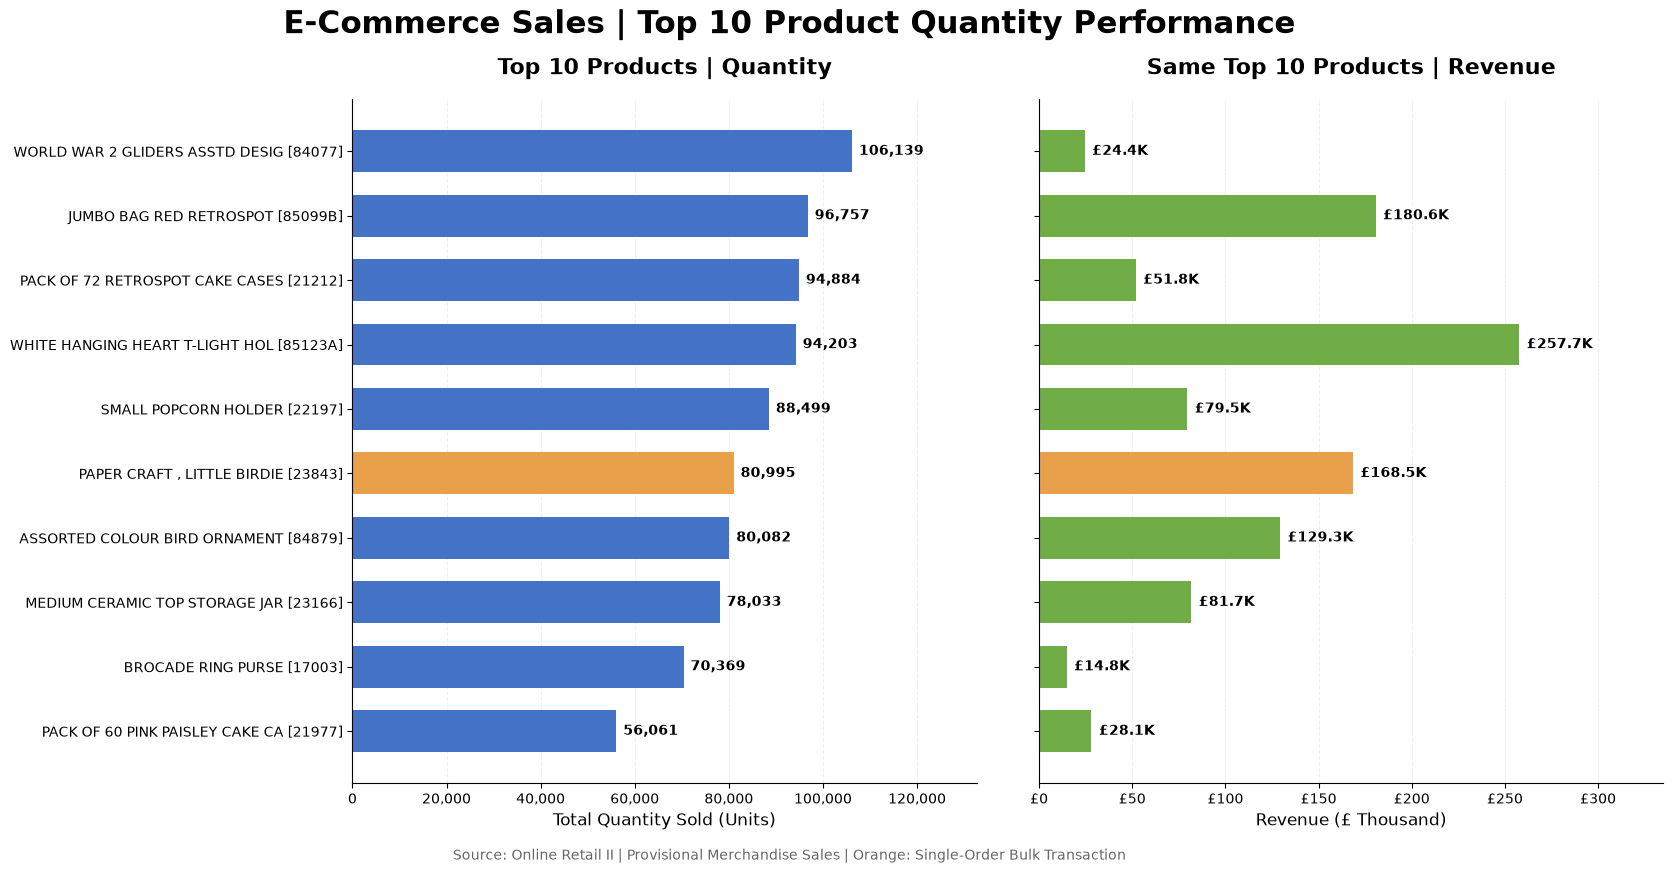

Chart saved: images\eda_04_04_top10_product_quantity.png
EDA-04-04-04 Product Quantity Visualization: PASS


In [41]:

# ============================================================
# EDA-04-04-04 | Top 10 Product Quantity Visualization
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from pathlib import Path

# 1. Validate source
assert "top_quantity_products" in globals(), (
    "Run EDA-04-04-03 first."
)

required_cols = [
    "StockCode", "Description", "Total_Quantity",
    "Total_Revenue_GBP", "Unique_Orders",
    "Single_Order_Flag"
]

assert all(
    col in top_quantity_products.columns
    for col in required_cols
), "Missing required columns."

# 2. Prepare Top 10 data
chart_df = (
    top_quantity_products
    .sort_values("Total_Quantity", ascending=False)
    .head(10)
    .copy()
)

chart_df["Product_Label"] = (
    chart_df["Description"]
    .fillna("Unknown Product")
    .astype(str)
    .str.slice(0, 31)
    + " [" + chart_df["StockCode"].astype(str) + "]"
)

# Reverse for horizontal bar chart
plot_df = chart_df.iloc[::-1].copy()

# 3. Color configuration
BLUE = "#4472C4"
GREEN = "#70AD47"
ORANGE = "#E8A04B"

quantity_colors = [
    ORANGE if flag else BLUE
    for flag in plot_df["Single_Order_Flag"]
]

revenue_colors = [
    ORANGE if flag else GREEN
    for flag in plot_df["Single_Order_Flag"]
]

# 4. Create figure
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(19, 9),
    sharey=True,
    gridspec_kw={"width_ratios": [1, 1]}
)

y = np.arange(len(plot_df))

# Left: Quantity
bars1 = ax1.barh(
    y,
    plot_df["Total_Quantity"],
    color=quantity_colors,
    height=0.65
)

ax1.set_yticks(y)
ax1.set_yticklabels(
    plot_df["Product_Label"],
    fontsize=10
)

ax1.set_title(
    "Top 10 Products | Quantity",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax1.set_xlabel(
    "Total Quantity Sold (Units)",
    fontsize=12
)

ax1.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

ax1.set_xlim(
    0, plot_df["Total_Quantity"].max() * 1.25
)

# Right: Revenue
bars2 = ax2.barh(
    y,
    plot_df["Total_Revenue_GBP"] / 1000,
    color=revenue_colors,
    height=0.65
)

ax2.set_title(
    "Same Top 10 Products | Revenue",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax2.set_xlabel(
    "Revenue (£ Thousand)",
    fontsize=12
)

ax2.set_xlim(
    0,
    (plot_df["Total_Revenue_GBP"] / 1000).max() * 1.3
)

ax2.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"£{x:,.0f}")
)

# 5. Value labels
for bar, value in zip(
    bars1, plot_df["Total_Quantity"]
):
    ax1.text(
        bar.get_width() + 1500,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,.0f}",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

for bar, value in zip(
    bars2, plot_df["Total_Revenue_GBP"]
):
    ax2.text(
        bar.get_width() + 4,
        bar.get_y() + bar.get_height() / 2,
        f"£{value / 1000:,.1f}K",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

# 6. Formatting
for ax in [ax1, ax2]:
    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.2
    )
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

ax2.tick_params(axis="y", labelleft=False)

# 7. Main title
fig.suptitle(
    "E-Commerce Sales | Top 10 Product Quantity Performance",
    fontsize=22,
    fontweight="bold",
    y=0.98
)

# 8. Footnote
fig.text(
    0.5, 0.035,
    "Source: Online Retail II | Provisional Merchandise Sales"
    " | Orange: Single-Order Bulk Transaction",
    ha="center",
    fontsize=10,
    color="#666666"
)

plt.subplots_adjust(
    left=0.27,
    right=0.96,
    top=0.88,
    bottom=0.12,
    wspace=0.10
)

# 9. Save chart
output_dir = Path("images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir /
    "eda_04_04_top10_product_quantity.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 10. Validation
assert len(chart_df) == 10
assert chart_df["Total_Quantity"].is_monotonic_decreasing
assert output_path.exists()

print(f"Chart saved: {output_path}")
print(
    "EDA-04-04-04 Product Quantity Visualization: PASS"
)



### EDA-04-04-04 | Interpretation

**Key Findings**

1. **Sales Volume Does Not Necessarily Translate into High Revenue**
   - WORLD WAR 2 GLIDERS ASSTD DESIGNS ranked first in quantity with 106,139 units but generated only £24.4K in revenue.
   - WHITE HANGING HEART T-LIGHT HOLDER ranked fourth in quantity but generated £257.7K in revenue.

2. **Exceptional Bulk Transactions Influence Product Rankings**
   - PAPER CRAFT, LITTLE BIRDIE recorded 80,995 units sold and £168.5K in revenue from a single invoice.
   - This transaction represents an exceptional bulk order rather than evidence of recurring demand.

3. **Product Revenue Depends on Both Quantity and Unit Price**
   - Similar sales volumes can produce substantially different revenue outcomes.
   - Revenue performance should be evaluated alongside quantity, unit price, and order frequency.

**Business Implications**

- Use revenue and sales volume together when evaluating product performance.
- Identify high-volume, low-revenue products for further pricing and profitability analysis.
- Separate exceptional bulk transactions when assessing recurring demand.
- Consider order frequency when prioritizing products for inventory planning.

**Conclusion**

Product quantity rankings alone do not fully explain commercial performance. Combining quantity, revenue, unit price, and order frequency provides a more balanced basis for product evaluation.

**Limitation**

This analysis measures revenue rather than profit. Product costs and margins are not available, so profitability cannot be directly assessed.



### EDA-04-04-05 | Product Revenue Concentration & Pareto Analysis

**Objective**

Evaluate how merchandise revenue is distributed across products and identify the number of products required to generate 80% of total revenue.

**Analysis Scope**
- Dataset: Provisional Merchandise Sales
- Product Identifier: StockCode
- Ranking Metric: Total Revenue (GBP)
- Analysis Method: Pareto Analysis
- Concentration Threshold: 80% of Total Revenue

**Key Questions**
1. How much revenue is generated by the top 10, 50, and 100 products?
2. How many products account for 80% of total merchandise revenue?
3. What percentage of the product portfolio generates 80% of revenue?
4. Does the observed revenue distribution follow the traditional 80/20 pattern?

**Methodology**

Products are ranked by total revenue in descending order. Revenue share and cumulative revenue share are calculated to evaluate revenue concentration.

The 80% threshold is used to identify the minimum number of products required to generate at least 80% of total merchandise revenue.


In [42]:

# ============================================================
# EDA-04-04-05-01 | Product Revenue Concentration
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

# 1. Validate source DataFrame
assert "product_sales_df" in globals(), (
    "product_sales_df is not defined. "
    "Run EDA-04-04-01 first."
)

required_columns = [
    "StockCode",
    "Total_Revenue_GBP"
]

assert all(
    col in product_sales_df.columns
    for col in required_columns
), "Missing required columns."

# 2. Prepare product revenue ranking
product_pareto_df = (
    product_sales_df
    .sort_values(
        "Total_Revenue_GBP",
        ascending=False
    )
    .reset_index(drop=True)
    .copy()
)

# 3. Calculate total revenue
total_product_revenue = (
    product_pareto_df["Total_Revenue_GBP"].sum()
)

total_products = len(product_pareto_df)

assert total_product_revenue > 0, (
    "Total revenue must be positive."
)

assert (
    product_pareto_df["Total_Revenue_GBP"] >= 0
).all(), "Negative product revenue detected."

# 4. Calculate revenue share
product_pareto_df["Revenue_Share_Pct"] = (
    product_pareto_df["Total_Revenue_GBP"]
    / total_product_revenue * 100
)

# 5. Calculate cumulative revenue share
product_pareto_df["Cumulative_Revenue_Pct"] = (
    product_pareto_df["Revenue_Share_Pct"].cumsum()
)

product_pareto_df["Product_Rank"] = (
    np.arange(1, total_products + 1)
)

# 6. Calculate concentration metrics
top10_share = (
    product_pareto_df.head(10)["Revenue_Share_Pct"].sum()
)

top50_share = (
    product_pareto_df.head(50)["Revenue_Share_Pct"].sum()
)

top100_share = (
    product_pareto_df.head(100)["Revenue_Share_Pct"].sum()
)

# Minimum number of products reaching 80%
products_to_80 = int(
    np.searchsorted(
        product_pareto_df["Cumulative_Revenue_Pct"].to_numpy(),
        80,
        side="left"
    ) + 1
)

product_pct_to_80 = (
    products_to_80 / total_products * 100
)

# 7. Create KPI summary
pareto_summary_df = pd.DataFrame({
    "Metric": [
        "Total Products",
        "Total Merchandise Revenue (£)",
        "Top 10 Revenue Share (%)",
        "Top 50 Revenue Share (%)",
        "Top 100 Revenue Share (%)",
        "Products to Reach 80% Revenue",
        "Product Share to Reach 80% (%)",
        "Final Cumulative Revenue (%)"
    ],
    "Value": [
        total_products,
        total_product_revenue,
        top10_share,
        top50_share,
        top100_share,
        products_to_80,
        product_pct_to_80,
        product_pareto_df["Cumulative_Revenue_Pct"].iloc[-1]
    ]
})

print("=== Product Revenue Concentration Summary ===")

display(
    pareto_summary_df.style.format({
        "Value": "{:,.2f}"
    })
)

# 8. Display Top 15 product contributions
print("\n=== Top 15 Products | Revenue Concentration ===")

display(
    product_pareto_df[
        [
            "Product_Rank",
            "StockCode",
            "Total_Revenue_GBP",
            "Revenue_Share_Pct",
            "Cumulative_Revenue_Pct"
        ]
    ].head(15).style.format({
        "Total_Revenue_GBP": "£{:,.2f}",
        "Revenue_Share_Pct": "{:.2f}%",
        "Cumulative_Revenue_Pct": "{:.2f}%"
    })
)

# 9. Validation
expected_revenue = 19669952.77

assert np.isclose(
    total_product_revenue,
    expected_revenue,
    atol=0.01
), "Revenue reconciliation failed."

assert np.isclose(
    product_pareto_df["Revenue_Share_Pct"].sum(),
    100,
    atol=1e-6
)

assert np.isclose(
    product_pareto_df["Cumulative_Revenue_Pct"].iloc[-1],
    100,
    atol=1e-6
)

assert (
    product_pareto_df["Cumulative_Revenue_Pct"]
    .is_monotonic_increasing
)

assert (
    product_pareto_df["Cumulative_Revenue_Pct"]
    .iloc[products_to_80 - 1] >= 80 - 1e-8
)

print("\n=== Validation ===")
print(f"Total Products: {total_products:,}")
print(f"Total Revenue: £{total_product_revenue:,.2f}")
print(f"Products to Reach 80%: {products_to_80:,}")
print(f"Product Portfolio Share: {product_pct_to_80:.2f}%")

print(
    "\nEDA-04-04-05-01 Product Revenue Concentration: PASS"
)


=== Product Revenue Concentration Summary ===


,Metric,Value
0,Total Products,"4,911.00"
1,Total Merchandise Revenue (£),"19,669,952.77"
2,Top 10 Revenue Share (%),8.00
3,Top 50 Revenue Share (%),19.43
4,Top 100 Revenue Share (%),29.30
5,Products to Reach 80% Revenue,"1,042.00"
6,Product Share to Reach 80% (%),21.22
7,Final Cumulative Revenue (%),100.00



=== Top 15 Products | Revenue Concentration ===


,Product_Rank,StockCode,Total_Revenue_GBP,Revenue_Share_Pct,Cumulative_Revenue_Pct
0,1,22423,"£330,590.32",1.68%,1.68%
1,2,85123A,"£257,724.71",1.31%,2.99%
2,3,85099B,"£180,569.34",0.92%,3.91%
3,4,23843,"£168,469.60",0.86%,4.77%
4,5,47566,"£148,318.28",0.75%,5.52%
5,6,84879,"£129,324.49",0.66%,6.18%
6,7,22086,"£117,760.29",0.60%,6.78%
7,8,23166,"£81,700.92",0.42%,7.19%
8,9,79321,"£80,540.88",0.41%,7.60%
9,10,22197,"£79,520.20",0.40%,8.00%



=== Validation ===
Total Products: 4,911
Total Revenue: £19,669,952.77
Products to Reach 80%: 1,042
Product Portfolio Share: 21.22%

EDA-04-04-05-01 Product Revenue Concentration: PASS



### Interpretation | Product Revenue Concentration

**Key Findings**

- The dataset contains 4,911 products, generating total merchandise revenue of £19.67 million.
- The top 10 products contribute 8.00% of total revenue, while the top 50 and top 100 contribute 19.43% and 29.30%, respectively.
- A total of 1,042 products, representing 21.22% of the product portfolio, are required to generate at least 80% of total merchandise revenue.
- The observed distribution broadly resembles the Pareto 80/20 principle, although revenue is distributed across a relatively large group of products.

**Business Implications**

- Revenue-generating products should be prioritized for inventory availability, demand forecasting, and stock replenishment.
- The business should avoid relying exclusively on a small group of best-selling products, as a broader product portfolio contributes materially to revenue.
- Lower-revenue products should be evaluated using additional metrics, including profitability, demand stability, and strategic importance, before considering portfolio rationalization.

**Conclusion**

Product revenue follows a concentrated but diversified distribution. Approximately 21% of products account for at least 80% of merchandise revenue, providing a quantitative basis for product portfolio prioritization.



### EDA-04-04-05-02 | Product Revenue Pareto Visualization

**Objective**

Visualize the distribution of merchandise revenue across products and identify the proportion of products required to generate 80% of total revenue.

**Visualization Design**
- Product ranking based on total revenue
- Individual product revenue contribution
- Cumulative revenue share
- 80% revenue threshold
- Product concentration benchmark

**Business Question**

What proportion of the product portfolio is responsible for generating the majority of merchandise revenue?


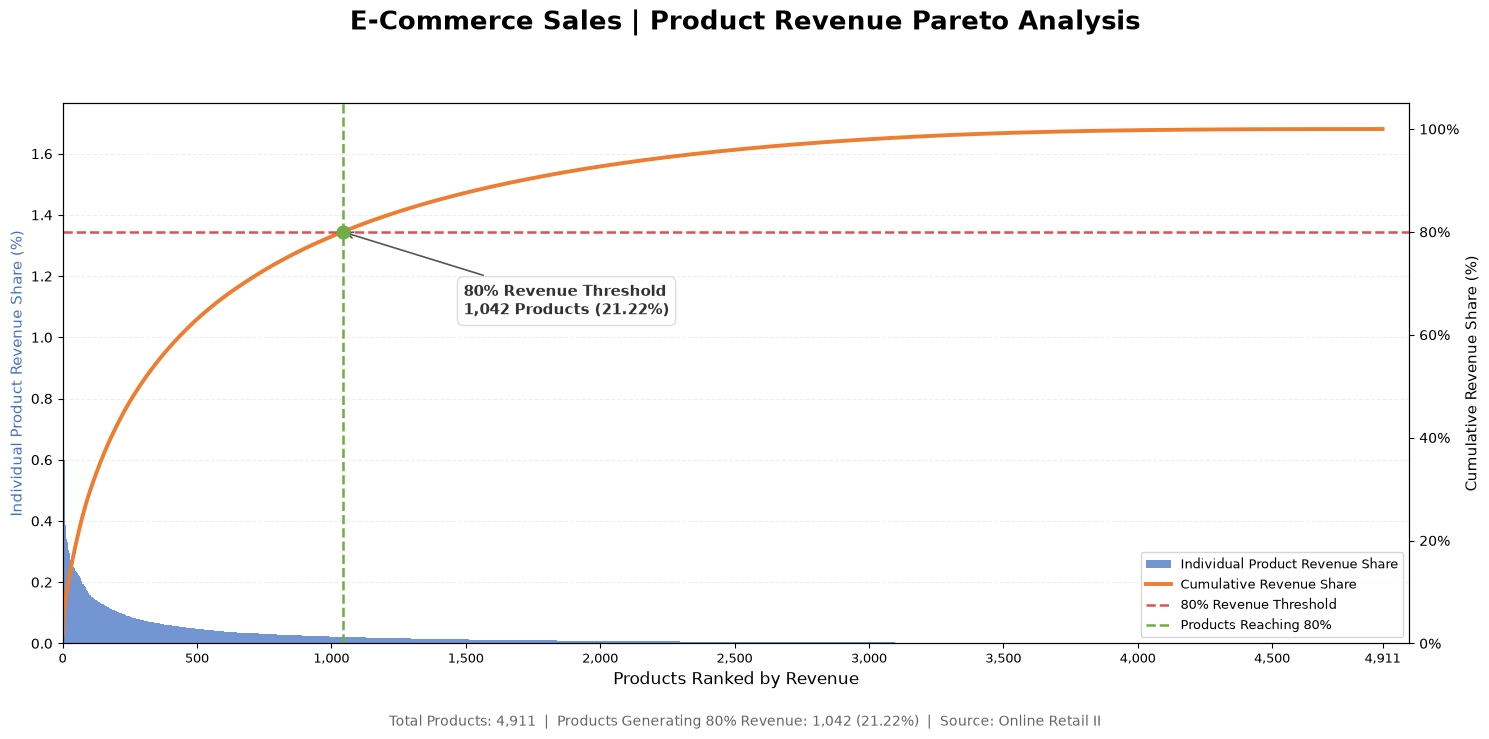

Chart saved: images\eda_04_04_product_revenue_pareto.png
EDA-04-04-05-02 Product Revenue Pareto Visualization: PASS


In [43]:

# ============================================================
# EDA-04-04-05-02 | Product Revenue Pareto Visualization
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pathlib import Path

# 1. Validate source data
assert "product_pareto_df" in globals(), (
    "product_pareto_df is not defined. "
    "Run EDA-04-04-05-01 first."
)

required_cols = [
    "Product_Rank",
    "Revenue_Share_Pct",
    "Cumulative_Revenue_Pct"
]

assert all(
    col in product_pareto_df.columns
    for col in required_cols
), "Required Pareto columns are missing."

# 2. Prepare data
pareto_plot_df = (
    product_pareto_df
    .sort_values("Product_Rank")
    .reset_index(drop=True)
    .copy()
)

total_products = len(pareto_plot_df)

products_to_80 = int(
    np.searchsorted(
        pareto_plot_df["Cumulative_Revenue_Pct"].to_numpy(),
        80,
        side="left"
    ) + 1
)

product_pct_to_80 = (
    products_to_80 / total_products * 100
)

# 3. Create chart
fig, ax1 = plt.subplots(figsize=(15, 7.5))

x = pareto_plot_df["Product_Rank"].to_numpy()
revenue_share = pareto_plot_df["Revenue_Share_Pct"].to_numpy()
cumulative_share = pareto_plot_df["Cumulative_Revenue_Pct"].to_numpy()

# Individual product revenue share
ax1.bar(
    x,
    revenue_share,
    color="#4472C4",
    alpha=0.75,
    width=1.0,
    label="Individual Product Revenue Share"
)

ax1.set_xlabel(
    "Products Ranked by Revenue",
    fontsize=12
)

ax1.set_ylabel(
    "Individual Product Revenue Share (%)",
    fontsize=11,
    color="#4472C4"
)

ax1.set_xlim(0, total_products + 100)
ax1.set_ylim(bottom=0)

ax1.grid(
    axis="y",
    linestyle="--",
    alpha=0.20
)

ax1.set_axisbelow(True)

# 4. Secondary axis: cumulative revenue
ax2 = ax1.twinx()

ax2.plot(
    x,
    cumulative_share,
    color="#ED7D31",
    linewidth=2.8,
    label="Cumulative Revenue Share"
)

ax2.axhline(
    y=80,
    color="#D9534F",
    linestyle="--",
    linewidth=1.8,
    label="80% Revenue Threshold"
)

ax2.axvline(
    x=products_to_80,
    color="#70AD47",
    linestyle="--",
    linewidth=1.8,
    label="Products Reaching 80%"
)

ax2.set_ylim(0, 105)

ax2.set_ylabel(
    "Cumulative Revenue Share (%)",
    fontsize=11
)

ax2.yaxis.set_major_formatter(
    PercentFormatter(xmax=100)
)

# 5. Highlight 80% intersection
actual_cumulative = cumulative_share[products_to_80 - 1]

ax2.scatter(
    products_to_80,
    actual_cumulative,
    color="#70AD47",
    s=85,
    zorder=5
)

ax2.annotate(
    f"80% Revenue Threshold\n"
    f"{products_to_80:,} Products ({product_pct_to_80:.2f}%)",
    xy=(products_to_80, actual_cumulative),
    xytext=(products_to_80 + 450, 64),
    fontsize=11,
    fontweight="bold",
    color="#333333",
    arrowprops=dict(
        arrowstyle="->",
        color="#555555",
        lw=1.2
    ),
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="#DDDDDD"
    )
)

# 6. X-axis ticks
tick_positions = [
    0, 500, 1000, 1500, 2000,
    2500, 3000, 3500, 4000,
    4500, total_products
]

ax1.set_xticks(tick_positions)

ax1.set_xticklabels(
    [f"{v:,}" for v in tick_positions],
    fontsize=9
)

# 7. Title and legend
fig.suptitle(
    "E-Commerce Sales | Product Revenue Pareto Analysis",
    fontsize=19,
    fontweight="bold",
    y=0.98
)

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax2.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="lower right",
    fontsize=9,
    frameon=True
)

# 8. Footer
fig.text(
    0.5,
    0.025,
    (
        f"Total Products: {total_products:,}  |  "
        f"Products Generating 80% Revenue: "
        f"{products_to_80:,} ({product_pct_to_80:.2f}%)  |  "
        "Source: Online Retail II"
    ),
    ha="center",
    fontsize=10,
    color="#666666"
)

plt.tight_layout(rect=[0, 0.055, 1, 0.93])

# 9. Save chart
output_dir = Path("images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir / "eda_04_04_product_revenue_pareto.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 10. Validation
assert products_to_80 == 1042
assert np.isclose(product_pct_to_80, 21.22, atol=0.01)

print(f"Chart saved: {output_path}")
print(
    "EDA-04-04-05-02 Product Revenue Pareto Visualization: PASS"
)



### Interpretation | Product Revenue Pareto Analysis

**Key Findings**

- The analysis covers 4,911 products with total merchandise revenue of £19.67 million.
- The top 1,042 products, representing 21.22% of the product portfolio, generate at least 80% of total merchandise revenue.
- The cumulative revenue curve rises sharply among the highest-ranked products and gradually flattens across the remaining portfolio.
- This pattern broadly aligns with the Pareto principle, indicating an uneven distribution of revenue across products.

**Business Implications**

- High-revenue products should receive priority in inventory planning, demand forecasting, and stock availability management.
- Product portfolio segmentation can help allocate operational resources according to revenue contribution.
- Lower-revenue products require further evaluation based on profitability, customer demand, seasonality, and strategic importance.
- Revenue concentration should be monitored periodically to identify changes in product demand and portfolio dependency.

**Conclusion**

The product portfolio exhibits a clear revenue concentration pattern, with approximately 21% of products accounting for at least 80% of merchandise revenue.

These findings provide a quantitative foundation for product prioritization and inventory optimization, while highlighting the need for additional profitability and demand analysis before making product rationalization decisions.



### EDA-04-04-06 | Product Performance Final Validation

**Objective**

Validate the consistency, completeness, and accuracy of product-level sales analysis before finalizing the Product Performance section.

**Validation Scope**

- Revenue and quantity reconciliation
- Transaction record reconciliation
- Product coverage and StockCode uniqueness
- Revenue and quantity ranking consistency
- Pareto revenue concentration validation

**Expected Outcome**

All product-level metrics should reconcile with the provisional merchandise sales dataset, and the Pareto analysis should accurately represent the cumulative revenue distribution.


In [44]:

# ============================================================
# EDA-04-04-06-01 | Product Performance Final Validation
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

# 1. Validate required DataFrames
required_dfs = [
    "product_source_df",
    "product_sales_df",
    "product_pareto_df"
]

for name in required_dfs:
    assert name in globals(), (
        f"{name} is not defined. "
        "Run the previous Product Performance cells first."
    )

# 2. Source totals
source_revenue = product_source_df["Sales"].sum()
source_quantity = product_source_df["Quantity"].sum()
source_records = len(product_source_df)
source_products = product_source_df["StockCode"].nunique()

# 3. Product aggregation totals
product_revenue = product_sales_df["Total_Revenue_GBP"].sum()
product_quantity = product_sales_df["Total_Quantity"].sum()
product_records = product_sales_df["Records"].sum()
product_count = len(product_sales_df)

# 4. Ranking validation
revenue_ranking_valid = (
    product_sales_df["Total_Revenue_GBP"]
    .is_monotonic_decreasing
)

pareto_ranking_valid = (
    product_pareto_df["Total_Revenue_GBP"]
    .is_monotonic_decreasing
)

quantity_ranking_valid = True

if "top15_quantity" in globals():
    quantity_ranking_valid = (
        top15_quantity["Total_Quantity"]
        .is_monotonic_decreasing
    )

# 5. Pareto validation
pareto_total = (
    product_pareto_df["Revenue_Share_Pct"].sum()
)

pareto_final = (
    product_pareto_df["Cumulative_Revenue_Pct"].iloc[-1]
)

products_to_80 = int(
    np.searchsorted(
        product_pareto_df["Cumulative_Revenue_Pct"].to_numpy(),
        80,
        side="left"
    ) + 1
)

product_pct_to_80 = (
    products_to_80 / product_count * 100
)

# 6. Validation checks
validation_checks = {
    "Revenue Reconciliation": np.isclose(
        source_revenue, product_revenue, atol=0.01
    ),
    "Quantity Reconciliation": (
        source_quantity == product_quantity
    ),
    "Record Reconciliation": (
        source_records == product_records
    ),
    "Product Coverage": (
        source_products == product_count
    ),
    "StockCode Uniqueness": (
        product_sales_df["StockCode"].is_unique
    ),
    "Revenue Ranking": revenue_ranking_valid,
    "Pareto Ranking": pareto_ranking_valid,
    "Quantity Ranking": quantity_ranking_valid,
    "Pareto Revenue Share": np.isclose(
        pareto_total, 100, atol=1e-6
    ),
    "Pareto Cumulative Share": np.isclose(
        pareto_final, 100, atol=1e-6
    ),
    "Pareto 80% Threshold": (
        product_pareto_df["Cumulative_Revenue_Pct"]
        .iloc[products_to_80 - 1] >= 80 - 1e-8
    )
}

validation_df = pd.DataFrame({
    "Validation": list(validation_checks.keys()),
    "Status": [
        "PASS" if result else "FAIL"
        for result in validation_checks.values()
    ]
})

print("=== Product Performance Final Validation ===")
display(validation_df)

# 7. Final KPI summary
product_kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Products",
        "Total Records",
        "Total Revenue (£)",
        "Total Quantity",
        "Top 10 Revenue Share (%)",
        "Top 50 Revenue Share (%)",
        "Top 100 Revenue Share (%)",
        "Products to Reach 80% Revenue",
        "Product Share to Reach 80% (%)"
    ],
    "Value": [
        product_count,
        source_records,
        source_revenue,
        source_quantity,
        product_pareto_df.head(10)["Revenue_Share_Pct"].sum(),
        product_pareto_df.head(50)["Revenue_Share_Pct"].sum(),
        product_pareto_df.head(100)["Revenue_Share_Pct"].sum(),
        products_to_80,
        product_pct_to_80
    ]
})

print("\n=== Product Performance KPI Summary ===")
display(
    product_kpi_summary.style.format({
        "Value": "{:,.2f}"
    })
)

# 8. Final assessment
all_pass = validation_df["Status"].eq("PASS").all()

print("\n=== Final Assessment ===")
print(f"Validation Checks: {len(validation_checks)}")
print(f"Passed: {validation_df['Status'].eq('PASS').sum()}")
print(f"Failed: {validation_df['Status'].eq('FAIL').sum()}")

if all_pass:
    print(
        "\nEDA-04-04-06-01 "
        "Product Performance Final Validation: PASS"
    )
else:
    print(
        "\nEDA-04-04-06-01 "
        "Product Performance Final Validation: FAIL"
    )


=== Product Performance Final Validation ===


,Validation,Status
0,Revenue Reconciliation,PASS
1,Quantity Reconciliation,PASS
2,Record Reconciliation,PASS
3,Product Coverage,PASS
4,StockCode Uniqueness,PASS
5,Revenue Ranking,PASS
6,Pareto Ranking,PASS
7,Quantity Ranking,PASS
8,Pareto Revenue Share,PASS
9,Pareto Cumulative Share,PASS



=== Product Performance KPI Summary ===


,Metric,Value
0,Total Products,"4,911.00"
1,Total Records,"1,003,792.00"
2,Total Revenue (£),"19,669,952.77"
3,Total Quantity,"11,188,732.00"
4,Top 10 Revenue Share (%),8.00
5,Top 50 Revenue Share (%),19.43
6,Top 100 Revenue Share (%),29.30
7,Products to Reach 80% Revenue,"1,042.00"
8,Product Share to Reach 80% (%),21.22



=== Final Assessment ===
Validation Checks: 11
Passed: 11
Failed: 0

EDA-04-04-06-01 Product Performance Final Validation: PASS



### EDA-04-04-06-02 | Final Interpretation & Business Insights

**Validation Summary**

- All 11 implemented validation checks passed.
- Product-level revenue, quantity, and transaction records reconcile with the provisional merchandise sales dataset.
- The analysis covers 4,911 unique products and 1,003,792 transaction records.
- Total merchandise revenue is £19,669,952.77, representing 11,188,732 units sold.
- Revenue concentration and Pareto calculations are internally consistent.

**Key Business Findings**

1. **Revenue Concentration**
   - The top 10 products contribute 8.00% of total merchandise revenue.
   - The top 100 products contribute 29.30% of revenue.
   - A total of 1,042 products (21.22% of the portfolio) generate at least 80% of revenue.

2. **Revenue vs. Sales Volume**
   - High sales volume does not necessarily translate into high revenue contribution.
   - Differences in unit prices and purchasing patterns explain part of the variation between revenue and quantity rankings.
   - Single-order bulk transactions require additional review before interpreting product demand.

3. **Product Portfolio Structure**
   - Revenue is concentrated within a subset of products, broadly consistent with the Pareto principle.
   - However, revenue is distributed across a sufficiently broad range of products that portfolio decisions should not rely exclusively on the top 10 or top 100 products.

**Business Recommendations**

- **Inventory Prioritization:** Prioritize high-revenue products for inventory availability and replenishment planning.
- **Demand Monitoring:** Monitor high-volume products separately from high-revenue products.
- **Bulk Transaction Review:** Investigate unusually large single-order transactions before using quantity as an indicator of recurring demand.
- **Portfolio Optimization:** Evaluate lower-revenue products using profitability, demand stability, and strategic importance before considering discontinuation.

**Limitations**

- Revenue does not represent profitability because product costs and margins are unavailable.
- Product-level demand may be influenced by seasonality and exceptional bulk transactions.
- The analysis is based on provisional merchandise sales classification.
- The implemented quantity-ranking validation does not independently reconcile the displayed Top 15 ranking.

**Conclusion**

The Product Performance analysis confirms that merchandise revenue is unevenly distributed across the product portfolio.

Approximately 21% of products account for at least 80% of revenue, supporting a differentiated approach to inventory management and product prioritization.

The findings provide a validated analytical foundation for further customer behavior and revenue segmentation analysis.



## EDA-04-05 | Customer Behavior Analysis

### EDA-04-05-01 | Customer Data Completeness

**Objective**

Assess customer identification coverage within the provisional merchandise sales dataset and establish a reliable analytical base for customer-level analysis.

**Key Questions**

- How many transaction records contain valid Customer IDs?
- What percentage of merchandise revenue is associated with identifiable customers?
- How many unique customers can be analyzed?
- How much revenue cannot be attributed to individual customers?

**Methodology**

- Use the provisional merchandise sales dataset.
- Separate records with valid and missing Customer IDs.
- Compare record counts and revenue between the two groups.
- Validate that the resulting groups reconcile with the original merchandise dataset.

**Expected Outcome**

Establish a customer-identifiable dataset for subsequent purchase frequency, AOV, and revenue concentration analysis.


In [45]:

# ============================================================
# EDA-04-05-01 | Customer Data Completeness
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

# 1. Validate source DataFrame
assert "merchandise_sales_df" in globals(), (
    "merchandise_sales_df is not defined. "
    "Run the merchandise dataset creation cell first."
)

customer_source_df = merchandise_sales_df.copy()

required_cols = ["Customer ID", "Invoice", "Sales"]

assert all(
    col in customer_source_df.columns
    for col in required_cols
), "Required customer analysis columns are missing."

# 2. Normalize Customer ID
customer_source_df["Customer_ID_Clean"] = (
    pd.to_numeric(
        customer_source_df["Customer ID"],
        errors="coerce"
    )
)

# 3. Separate identifiable and unidentified records
customer_identified_df = customer_source_df[
    customer_source_df["Customer_ID_Clean"].notna()
].copy()

customer_unidentified_df = customer_source_df[
    customer_source_df["Customer_ID_Clean"].isna()
].copy()

# 4. Calculate metrics
total_records = len(customer_source_df)
total_revenue = customer_source_df["Sales"].sum()

identified_records = len(customer_identified_df)
unidentified_records = len(customer_unidentified_df)

identified_revenue = customer_identified_df["Sales"].sum()
unidentified_revenue = customer_unidentified_df["Sales"].sum()

unique_customers = (
    customer_identified_df["Customer_ID_Clean"].nunique()
)

# 5. Completeness summary
customer_completeness_df = pd.DataFrame({
    "Customer_ID_Status": [
        "Identified",
        "Unidentified",
        "Total"
    ],
    "Records": [
        identified_records,
        unidentified_records,
        total_records
    ],
    "Revenue_GBP": [
        identified_revenue,
        unidentified_revenue,
        total_revenue
    ]
})

customer_completeness_df["Record_Share_Pct"] = (
    customer_completeness_df["Records"]
    / total_records * 100
)

customer_completeness_df["Revenue_Share_Pct"] = (
    customer_completeness_df["Revenue_GBP"]
    / total_revenue * 100
)

print("=== Customer Data Completeness ===")

display(
    customer_completeness_df.style.format({
        "Records": "{:,.0f}",
        "Revenue_GBP": "£{:,.2f}",
        "Record_Share_Pct": "{:.2f}%",
        "Revenue_Share_Pct": "{:.2f}%"
    })
)

# 6. Customer identification summary
print("\n=== Customer Identification Summary ===")
print(f"Total Records: {total_records:,}")
print(f"Identified Records: {identified_records:,}")
print(f"Unidentified Records: {unidentified_records:,}")
print(f"Unique Customers: {unique_customers:,}")

print(
    f"Customer Identification Rate: "
    f"{identified_records / total_records * 100:.2f}%"
)

print(
    f"Identified Revenue Share: "
    f"{identified_revenue / total_revenue * 100:.2f}%"
)

# 7. Validation
validation_checks = {
    "Record Reconciliation": (
        identified_records + unidentified_records
        == total_records
    ),
    "Revenue Reconciliation": np.isclose(
        identified_revenue + unidentified_revenue,
        total_revenue,
        atol=0.01
    ),
    "Customer ID Completeness": (
        customer_identified_df[
            "Customer_ID_Clean"
        ].notna().all()
    ),
    "Dataset Partition": (
        len(customer_identified_df)
        + len(customer_unidentified_df)
        == len(customer_source_df)
    )
}

validation_df = pd.DataFrame({
    "Validation": list(validation_checks.keys()),
    "Status": [
        "PASS" if result else "FAIL"
        for result in validation_checks.values()
    ]
})

print("\n=== Validation ===")
display(validation_df)

if validation_df["Status"].eq("PASS").all():
    print(
        "\nEDA-04-05-01 "
        "Customer Data Completeness: PASS"
    )
else:
    print(
        "\nEDA-04-05-01 "
        "Customer Data Completeness: FAIL"
    )


=== Customer Data Completeness ===


,Customer_ID_Status,Records,Revenue_GBP,Record_Share_Pct,Revenue_Share_Pct
0,Identified,"776,925","£17,086,472.20",77.40%,86.87%
1,Unidentified,"226,867","£2,583,480.57",22.60%,13.13%
2,Total,"1,003,792","£19,669,952.77",100.00%,100.00%



=== Customer Identification Summary ===
Total Records: 1,003,792
Identified Records: 776,925
Unidentified Records: 226,867
Unique Customers: 5,862
Customer Identification Rate: 77.40%
Identified Revenue Share: 86.87%

=== Validation ===


,Validation,Status
0,Record Reconciliation,PASS
1,Revenue Reconciliation,PASS
2,Customer ID Completeness,PASS
3,Dataset Partition,PASS



EDA-04-05-01 Customer Data Completeness: PASS


### EDA-04-05-01 | Interpretation

**Key Findings**

- Customer identification coverage reached **77.40% of transaction records**, representing **86.87% of total merchandise revenue**.
- A total of **5,862 unique customers** were identified across 776,925 transaction records.
- Transactions without Customer IDs accounted for **22.60% of records** but only **13.13% of revenue**, indicating a lower average revenue per transaction record than identifiable transactions.
- All four data integrity checks passed, confirming successful dataset partitioning and reconciliation.

**Business Implications**

- The identifiable customer dataset provides substantial revenue coverage for customer-level behavioral analysis.
- The remaining unidentified revenue introduces potential selection bias and should be excluded from customer-level metrics while remaining included in overall merchandise revenue reporting.
- Customer-level analysis can now proceed to evaluate purchase frequency, average order value, and revenue concentration.

**Analytical Limitation**

Customer ID completeness does not guarantee that identified customers are representative of the entire customer population. Findings should therefore be interpreted as applying to identifiable customers rather than all customers.


### EDA-04-05-02 | Customer Revenue Distribution

**Objective**

Analyze revenue distribution across identifiable customers and establish customer-level performance metrics for subsequent behavioral and RFM analysis.

**Key Questions**

- How much revenue does each customer generate?
- How many unique orders does each customer place?
- What is the average order value per customer?
- How unevenly is revenue distributed across customers?
- Which customers contribute the highest revenue?

**Methodology**

1. Use the customer-identifiable merchandise sales dataset.
2. Aggregate total revenue, unique orders, and transaction records by Customer ID.
3. Calculate customer-level Average Order Value (AOV).
4. Rank customers by total revenue.
5. Examine customer revenue distribution using descriptive statistics.
6. Validate revenue, record, and customer reconciliation.

**Expected Outcome**

Create a validated customer-level summary dataset to support purchase frequency analysis, customer revenue concentration, and RFM segmentation.


In [46]:

# ============================================================
# EDA-04-05-02-01 | Customer Revenue Aggregation
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

# 1. Validate source DataFrame
assert "customer_identified_df" in globals(), (
    "customer_identified_df is not defined. "
    "Run EDA-04-05-01 first."
)

customer_analysis_df = customer_identified_df.copy()

required_cols = [
    "Customer_ID_Clean",
    "Invoice",
    "Sales"
]

assert all(
    col in customer_analysis_df.columns
    for col in required_cols
), "Required customer analysis columns are missing."

assert customer_analysis_df["Customer_ID_Clean"].notna().all(), (
    "Missing Customer IDs detected."
)

assert customer_analysis_df["Invoice"].notna().all(), (
    "Missing Invoice IDs detected."
)

# 2. Aggregate customer-level metrics
customer_summary_df = (
    customer_analysis_df
    .groupby("Customer_ID_Clean")
    .agg(
        Total_Revenue_GBP=("Sales", "sum"),
        Unique_Orders=("Invoice", "nunique"),
        Records=("Invoice", "size")
    )
    .reset_index()
    .rename(columns={
        "Customer_ID_Clean": "Customer_ID"
    })
)

# 3. Calculate Average Order Value
customer_summary_df["AOV_GBP"] = (
    customer_summary_df["Total_Revenue_GBP"]
    / customer_summary_df["Unique_Orders"]
)

# 4. Calculate revenue share
total_identified_revenue = (
    customer_analysis_df["Sales"].sum()
)

customer_summary_df["Revenue_Share_Pct"] = (
    customer_summary_df["Total_Revenue_GBP"]
    / total_identified_revenue
    * 100
)

# 5. Rank customers by revenue
customer_summary_df = (
    customer_summary_df
    .sort_values(
        "Total_Revenue_GBP",
        ascending=False
    )
    .reset_index(drop=True)
)

customer_summary_df["Revenue_Rank"] = (
    np.arange(1, len(customer_summary_df) + 1)
)

# 6. Display Top 15 Customers
print("=== Top 15 Customers by Revenue ===")

display(
    customer_summary_df[
        [
            "Revenue_Rank",
            "Customer_ID",
            "Total_Revenue_GBP",
            "Unique_Orders",
            "Records",
            "AOV_GBP",
            "Revenue_Share_Pct"
        ]
    ]
    .head(15)
    .style.format({
        "Customer_ID": "{:.0f}",
        "Total_Revenue_GBP": "£{:,.2f}",
        "Unique_Orders": "{:,.0f}",
        "Records": "{:,.0f}",
        "AOV_GBP": "£{:,.2f}",
        "Revenue_Share_Pct": "{:.2f}%"
    })
)

# 7. Customer revenue distribution
revenue_stats = (
    customer_summary_df["Total_Revenue_GBP"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\n=== Customer Revenue Distribution ===")

display(
    revenue_stats.to_frame(
        name="Revenue_GBP"
    ).style.format({
        "Revenue_GBP": "£{:,.2f}"
    })
)

# 8. Summary metrics
total_customers = len(customer_summary_df)
total_customer_orders = customer_summary_df["Unique_Orders"].sum()

print("\n=== Customer Revenue Summary ===")
print(f"Total Identified Customers: {total_customers:,}")
print(f"Total Identified Records: {len(customer_analysis_df):,}")
print(f"Total Identified Revenue: £{total_identified_revenue:,.2f}")
print(f"Sum of Customer-Level Orders: {total_customer_orders:,}")
print(
    f"Average Revenue per Customer: "
    f"£{customer_summary_df['Total_Revenue_GBP'].mean():,.2f}"
)
print(
    f"Median Revenue per Customer: "
    f"£{customer_summary_df['Total_Revenue_GBP'].median():,.2f}"
)

# 9. Data validation
validation_checks = {
    "Revenue Reconciliation": np.isclose(
        customer_summary_df["Total_Revenue_GBP"].sum(),
        total_identified_revenue,
        atol=0.01
    ),
    "Record Reconciliation": (
        customer_summary_df["Records"].sum()
        == len(customer_analysis_df)
    ),
    "Customer Reconciliation": (
        len(customer_summary_df)
        == customer_analysis_df["Customer_ID_Clean"].nunique()
    ),
    "Customer ID Uniqueness": (
        customer_summary_df["Customer_ID"].is_unique
    ),
    "Order Count Validation": (
        customer_summary_df["Unique_Orders"].gt(0).all()
    ),
    "Revenue Share Reconciliation": np.isclose(
        customer_summary_df["Revenue_Share_Pct"].sum(),
        100.0,
        atol=0.0001
    ),
    "AOV Calculation": np.allclose(
        customer_summary_df["AOV_GBP"],
        customer_summary_df["Total_Revenue_GBP"]
        / customer_summary_df["Unique_Orders"]
    )
}

validation_df = pd.DataFrame({
    "Validation": list(validation_checks.keys()),
    "Status": [
        "PASS" if result else "FAIL"
        for result in validation_checks.values()
    ]
})

print("\n=== Validation ===")
display(validation_df)

if validation_df["Status"].eq("PASS").all():
    print(
        "\nEDA-04-05-02-01 "
        "Customer Revenue Aggregation: PASS"
    )
else:
    print(
        "\nEDA-04-05-02-01 "
        "Customer Revenue Aggregation: FAIL"
    )


=== Top 15 Customers by Revenue ===


,Revenue_Rank,Customer_ID,Total_Revenue_GBP,Unique_Orders,Records,AOV_GBP,Revenue_Share_Pct
0,1,18102,"£580,987.04",145,"1,040","£4,006.81",3.40%
1,2,14646,"£526,751.52",145,"3,819","£3,632.77",3.08%
2,3,14156,"£305,259.17",151,"4,033","£2,021.58",1.79%
3,4,14911,"£280,041.15",379,"11,058",£738.89,1.64%
4,5,17450,"£244,784.25",51,420,"£4,799.69",1.43%
5,6,13694,"£195,640.69",143,"1,519","£1,368.12",1.15%
6,7,17511,"£172,132.87",60,"1,868","£2,868.88",1.01%
7,8,16446,"£168,472.50",2,3,"£84,236.25",0.99%
8,9,16684,"£147,142.77",55,718,"£2,675.32",0.86%
9,10,12415,"£144,033.37",24,922,"£6,001.39",0.84%



=== Customer Revenue Distribution ===


,Revenue_GBP
count,"£5,862.00"
mean,"£2,914.79"
std,"£14,329.17"
min,£2.95
25%,£338.72
50%,£855.22
75%,"£2,237.03"
90%,"£5,380.55"
95%,"£9,264.09"
99%,"£28,611.90"



=== Customer Revenue Summary ===
Total Identified Customers: 5,862
Total Identified Records: 776,925
Total Identified Revenue: £17,086,472.20
Sum of Customer-Level Orders: 36,680
Average Revenue per Customer: £2,914.79
Median Revenue per Customer: £855.22

=== Validation ===


,Validation,Status
0,Revenue Reconciliation,PASS
1,Record Reconciliation,PASS
2,Customer Reconciliation,PASS
3,Customer ID Uniqueness,PASS
4,Order Count Validation,PASS
5,Revenue Share Reconciliation,PASS
6,AOV Calculation,PASS



EDA-04-05-02-01 Customer Revenue Aggregation: PASS



### Interpretation

**Key Findings**

- A total of 5,862 identifiable customers generated £17.09 million in merchandise revenue.
- Average revenue per customer was £2,914.79, compared with a median of £855.22, indicating a strongly right-skewed customer revenue distribution.
- The 90th and 99th percentile revenue thresholds were £5,380.55 and £28,611.90, respectively, demonstrating substantial differences in customer spending.
- The top five customers contributed approximately 11.34% of identifiable customer revenue.
- Certain high-revenue customers generated substantial sales through relatively few orders, suggesting potentially distinct purchasing patterns.

**Business Implications**

- Customer revenue is unevenly distributed, highlighting the importance of identifying and retaining high-value customers.
- Revenue alone may not adequately describe customer behavior. Purchase frequency and average order value should also be considered.
- High-revenue customers with unusually low order frequency warrant further investigation before being classified as strategically valuable recurring customers.

**Analytical Limitations**

- The analysis covers identifiable customers representing 86.87% of total merchandise revenue.
- Customer revenue represents cumulative spending within the available dataset, not customer lifetime value.
- High-value or unusual transactions may influence revenue distribution and should be reviewed separately.

**Validation**

All seven validation checks passed, confirming customer-level revenue reconciliation, record completeness, customer uniqueness, and calculation consistency.



### EDA-04-05-02-02 | Customer Revenue Distribution Visualization

**Objective**

Visualize the distribution of cumulative customer revenue and identify differences between typical and high-value customers.

**Visualization Design**

- Left: Customer revenue distribution using logarithmic revenue bins.
- Right: Comparison of mean, median, and selected revenue percentiles.
- Highlight the substantial gap between typical customer spending and the upper revenue distribution.
- Exclude unidentified customers from customer-level analysis.

**Expected Outcome**

Provide visual evidence of customer revenue inequality and establish a foundation for customer segmentation and revenue concentration analysis.


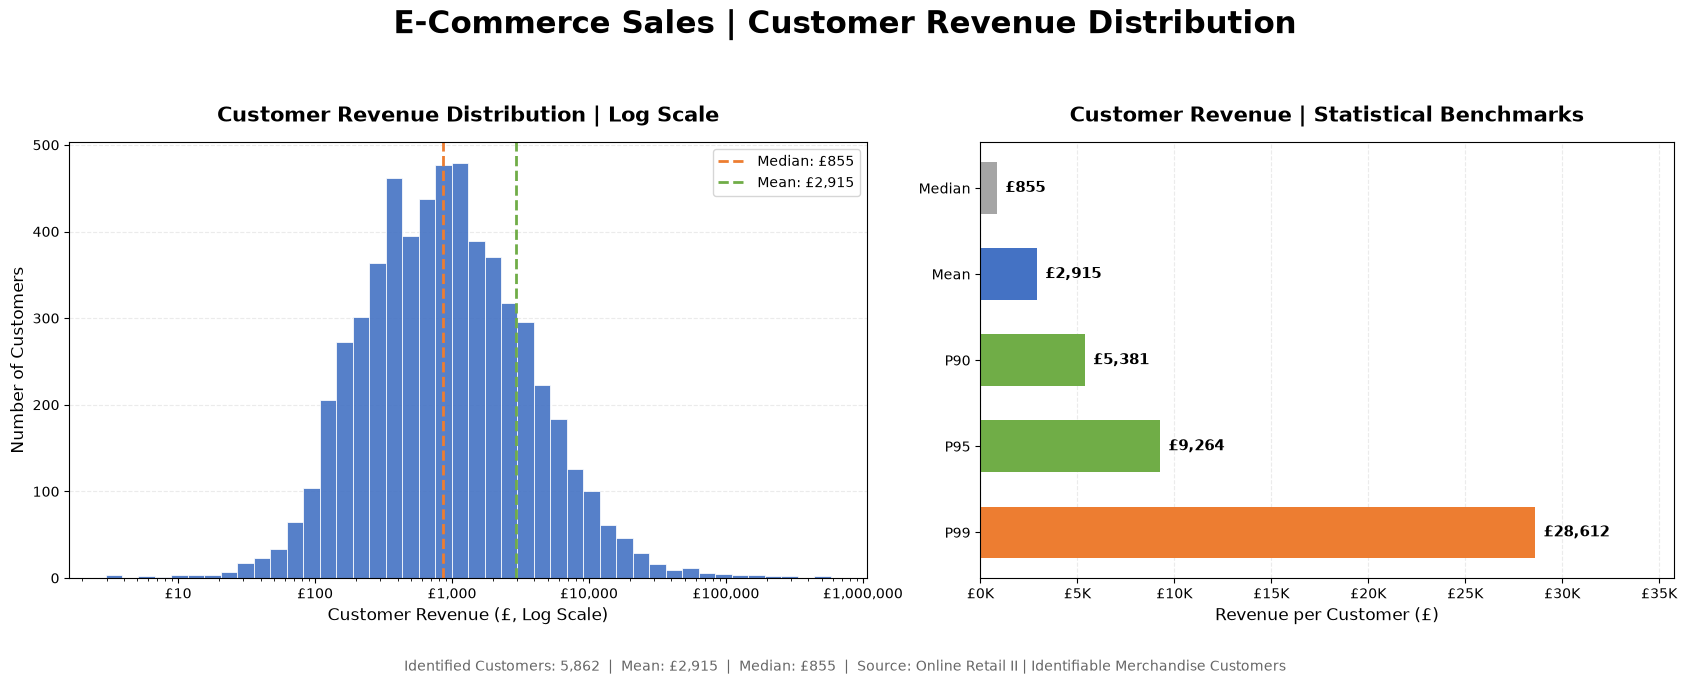

Chart saved: images\eda_04_05_customer_revenue_distribution.png
EDA-04-05-02-02 Customer Revenue Distribution Visualization: PASS


In [47]:

# ============================================================
# EDA-04-05-02-02 | Customer Revenue Distribution Visualization
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

# 1. Validate source
assert "customer_summary_df" in globals(), (
    "customer_summary_df is not defined. "
    "Run EDA-04-05-02-01 first."
)

revenue = customer_summary_df["Total_Revenue_GBP"].dropna()

assert len(revenue) > 0, "No customer revenue data."
assert (revenue > 0).all(), (
    "Non-positive customer revenue detected. "
    "Review the source data before using log bins."
)

# 2. Calculate revenue benchmarks
median_rev = revenue.median()
mean_rev = revenue.mean()
p90 = revenue.quantile(0.90)
p95 = revenue.quantile(0.95)
p99 = revenue.quantile(0.99)

metrics = ["Median", "Mean", "P90", "P95", "P99"]
values = [median_rev, mean_rev, p90, p95, p99]

# 3. Color palette
BLUE = "#4472C4"
GREEN = "#70AD47"
ORANGE = "#ED7D31"
GRAY = "#A5A5A5"

# 4. Create figure
fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 7),
    gridspec_kw={"width_ratios": [1.15, 1]}
)

fig.suptitle(
    "E-Commerce Sales | Customer Revenue Distribution",
    fontsize=22,
    fontweight="bold",
    y=0.98
)

# ------------------------------------------------------------
# LEFT | Customer Revenue Distribution
# ------------------------------------------------------------

ax1 = axes[0]

bins = np.logspace(
    np.log10(revenue.min()),
    np.log10(revenue.max()),
    45
)

ax1.hist(
    revenue,
    bins=bins,
    color=BLUE,
    edgecolor="white",
    linewidth=0.6,
    alpha=0.9
)

ax1.set_xscale("log")

ax1.axvline(
    median_rev,
    color=ORANGE,
    linestyle="--",
    linewidth=2,
    label=f"Median: £{median_rev:,.0f}"
)

ax1.axvline(
    mean_rev,
    color=GREEN,
    linestyle="--",
    linewidth=2,
    label=f"Mean: £{mean_rev:,.0f}"
)

ax1.set_title(
    "Customer Revenue Distribution | Log Scale",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax1.set_xlabel("Customer Revenue (£, Log Scale)", fontsize=12)
ax1.set_ylabel("Number of Customers", fontsize=12)

ax1.xaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda x, pos: f"£{x:,.0f}"
    )
)

ax1.grid(axis="y", linestyle="--", alpha=0.25)
ax1.set_axisbelow(True)
ax1.legend(fontsize=10)

# ------------------------------------------------------------
# RIGHT | Customer Revenue Benchmarks
# ------------------------------------------------------------

ax2 = axes[1]

colors = [GRAY, BLUE, GREEN, GREEN, ORANGE]

bars = ax2.barh(
    metrics,
    values,
    color=colors,
    height=0.6
)

ax2.invert_yaxis()

ax2.set_title(
    "Customer Revenue | Statistical Benchmarks",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax2.set_xlabel("Revenue per Customer (£)", fontsize=12)

ax2.set_xlim(0, max(values) * 1.25)

ax2.xaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda x, pos: f"£{x/1000:,.0f}K"
    )
)

for bar, value in zip(bars, values):
    ax2.text(
        value + max(values) * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"£{value:,.0f}",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

ax2.grid(axis="x", linestyle="--", alpha=0.25)
ax2.set_axisbelow(True)

# 5. Footnote
fig.text(
    0.5,
    0.035,
    (
        f"Identified Customers: {len(revenue):,}  |  "
        f"Mean: £{mean_rev:,.0f}  |  "
        f"Median: £{median_rev:,.0f}  |  "
        "Source: Online Retail II | Identifiable Merchandise Customers"
    ),
    ha="center",
    fontsize=10,
    color="#666666"
)

plt.tight_layout(rect=[0, 0.08, 1, 0.93])

# 6. Save chart
output_dir = Path("images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir / "eda_04_05_customer_revenue_distribution.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Chart saved: {output_path}")
print(
    "EDA-04-05-02-02 "
    "Customer Revenue Distribution Visualization: PASS"
)



### Interpretation

**Key Findings**

- Customer revenue exhibits a strongly right-skewed distribution, with a mean of £2,914.79 and a median of £855.22.
- The substantial difference between mean and median indicates that high-revenue customers disproportionately influence average customer spending.
- The 90th, 95th, and 99th percentile revenue thresholds were £5,380.55, £9,264.09, and £28,611.90, respectively.
- The 99th percentile threshold is approximately 33.5 times the median customer revenue.
- The logarithmic histogram highlights the wide variation in cumulative customer revenue across the identifiable customer base.

**Business Implications**

- Customer revenue varies substantially, supporting the need for differentiated customer management strategies.
- High-revenue customers may warrant targeted retention and relationship management initiatives.
- Revenue-based segmentation should be complemented by purchase frequency and recency to distinguish repeat customers from occasional high-value buyers.

**Analytical Limitations**

- The analysis includes only customers with identifiable Customer IDs.
- Revenue reflects cumulative spending during the dataset period rather than lifetime customer value.
- The logarithmic scale improves visibility across revenue ranges but requires careful interpretation of distribution patterns.



## EDA-04-05-03 | Purchase Frequency Analysis

### EDA-04-05-03-01 | Customer Purchase Frequency Aggregation

**Objective**

Analyze customer purchase frequency and evaluate the contribution of one-time and repeat customers to identifiable merchandise revenue.

**Key Questions**

- How many customers placed only one order?
- What proportion of customers placed multiple orders?
- How much revenue was generated by repeat customers?
- How does customer revenue differ across purchase frequency groups?
- Are high-frequency customers important contributors to overall revenue?

**Methodology**

1. Use the validated customer-level summary dataset.
2. Measure purchase frequency using the number of unique invoices per customer.
3. Classify customers into one-time and repeat customer groups.
4. Segment customers by purchase frequency.
5. Calculate customer counts, revenue, and revenue contribution by segment.
6. Validate customer and revenue reconciliation.

**Expected Outcome**

Establish a validated purchase frequency profile to support customer behavior analysis and subsequent RFM segmentation.


In [48]:

# ============================================================
# EDA-04-05-03-01 | Customer Purchase Frequency Aggregation
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

# 1. Validate source
assert "customer_summary_df" in globals(), (
    "customer_summary_df is not defined. "
    "Run EDA-04-05-02-01 first."
)

frequency_df = customer_summary_df.copy()

required_cols = [
    "Customer_ID",
    "Total_Revenue_GBP",
    "Unique_Orders"
]

assert all(
    col in frequency_df.columns
    for col in required_cols
), "Required columns are missing."

assert frequency_df["Customer_ID"].is_unique, (
    "Duplicate Customer IDs detected."
)

assert frequency_df["Unique_Orders"].gt(0).all(), (
    "Invalid purchase frequency detected."
)

# 2. Classify customer purchase behavior
frequency_df["Customer_Type"] = np.where(
    frequency_df["Unique_Orders"] == 1,
    "One-time Customer",
    "Repeat Customer"
)

# 3. Create purchase frequency segments
frequency_bins = [0, 1, 2, 5, 10, 20, np.inf]

frequency_labels = [
    "1 Order",
    "2 Orders",
    "3-5 Orders",
    "6-10 Orders",
    "11-20 Orders",
    "21+ Orders"
]

frequency_df["Frequency_Segment"] = pd.cut(
    frequency_df["Unique_Orders"],
    bins=frequency_bins,
    labels=frequency_labels,
    right=True
)

# 4. Customer type summary
customer_type_summary = (
    frequency_df
    .groupby("Customer_Type", as_index=False)
    .agg(
        Customers=("Customer_ID", "nunique"),
        Revenue_GBP=("Total_Revenue_GBP", "sum"),
        Total_Orders=("Unique_Orders", "sum")
    )
)

total_customers = len(frequency_df)
total_revenue = frequency_df["Total_Revenue_GBP"].sum()

customer_type_summary["Customer_Share_Pct"] = (
    customer_type_summary["Customers"]
    / total_customers * 100
)

customer_type_summary["Revenue_Share_Pct"] = (
    customer_type_summary["Revenue_GBP"]
    / total_revenue * 100
)

customer_type_summary["Revenue_Per_Customer_GBP"] = (
    customer_type_summary["Revenue_GBP"]
    / customer_type_summary["Customers"]
)

# 5. Frequency segment summary
frequency_segment_summary = (
    frequency_df
    .groupby(
        "Frequency_Segment",
        observed=True
    )
    .agg(
        Customers=("Customer_ID", "nunique"),
        Revenue_GBP=("Total_Revenue_GBP", "sum"),
        Total_Orders=("Unique_Orders", "sum")
    )
    .reindex(frequency_labels, fill_value=0)
    .rename_axis("Frequency_Segment")
    .reset_index()
)

frequency_segment_summary["Customer_Share_Pct"] = (
    frequency_segment_summary["Customers"]
    / total_customers * 100
)

frequency_segment_summary["Revenue_Share_Pct"] = (
    frequency_segment_summary["Revenue_GBP"]
    / total_revenue * 100
)

frequency_segment_summary["Revenue_Per_Customer_GBP"] = (
    np.where(
        frequency_segment_summary["Customers"] > 0,
        frequency_segment_summary["Revenue_GBP"]
        / frequency_segment_summary["Customers"],
        0
    )
)

# 6. Display customer type summary
print("=== Customer Type Summary ===")

display(
    customer_type_summary.style.format({
        "Customers": "{:,.0f}",
        "Revenue_GBP": "£{:,.2f}",
        "Total_Orders": "{:,.0f}",
        "Customer_Share_Pct": "{:.2f}%",
        "Revenue_Share_Pct": "{:.2f}%",
        "Revenue_Per_Customer_GBP": "£{:,.2f}"
    })
)

# 7. Display frequency segment summary
print("\n=== Purchase Frequency Segment Summary ===")

display(
    frequency_segment_summary.style.format({
        "Customers": "{:,.0f}",
        "Revenue_GBP": "£{:,.2f}",
        "Total_Orders": "{:,.0f}",
        "Customer_Share_Pct": "{:.2f}%",
        "Revenue_Share_Pct": "{:.2f}%",
        "Revenue_Per_Customer_GBP": "£{:,.2f}"
    })
)

# 8. Key purchase frequency metrics
one_time_customers = (
    frequency_df["Unique_Orders"].eq(1).sum()
)

repeat_customers = (
    frequency_df["Unique_Orders"].ge(2).sum()
)

repeat_customer_rate = (
    repeat_customers / total_customers * 100
)

repeat_revenue = frequency_df.loc[
    frequency_df["Unique_Orders"].ge(2),
    "Total_Revenue_GBP"
].sum()

repeat_revenue_share = (
    repeat_revenue / total_revenue * 100
)

print("\n=== Purchase Frequency KPI Summary ===")
print(f"Total Customers: {total_customers:,}")
print(f"One-time Customers: {one_time_customers:,}")
print(f"Repeat Customers: {repeat_customers:,}")
print(f"Repeat Customer Rate: {repeat_customer_rate:.2f}%")
print(f"Repeat Customer Revenue: £{repeat_revenue:,.2f}")
print(f"Repeat Revenue Share: {repeat_revenue_share:.2f}%")

print(
    f"Average Orders per Customer: "
    f"{frequency_df['Unique_Orders'].mean():.2f}"
)

print(
    f"Median Orders per Customer: "
    f"{frequency_df['Unique_Orders'].median():.0f}"
)

print(
    f"Maximum Orders per Customer: "
    f"{frequency_df['Unique_Orders'].max():,}"
)

# 9. Validation
validation_checks = {
    "Customer Reconciliation": (
        customer_type_summary["Customers"].sum()
        == total_customers
    ),
    "Revenue Reconciliation": np.isclose(
        customer_type_summary["Revenue_GBP"].sum(),
        total_revenue,
        atol=0.01
    ),
    "Frequency Customer Reconciliation": (
        frequency_segment_summary["Customers"].sum()
        == total_customers
    ),
    "Frequency Revenue Reconciliation": np.isclose(
        frequency_segment_summary["Revenue_GBP"].sum(),
        total_revenue,
        atol=0.01
    ),
    "Customer Type Classification": (
        one_time_customers + repeat_customers
        == total_customers
    ),
    "Frequency Segment Completeness": (
        frequency_df["Frequency_Segment"].notna().all()
    ),
    "Revenue Share Reconciliation": np.isclose(
        frequency_segment_summary["Revenue_Share_Pct"].sum(),
        100.0,
        atol=0.0001
    )
}

validation_df = pd.DataFrame({
    "Validation": list(validation_checks.keys()),
    "Status": [
        "PASS" if result else "FAIL"
        for result in validation_checks.values()
    ]
})

print("\n=== Validation ===")
display(validation_df)

if validation_df["Status"].eq("PASS").all():
    print(
        "\nEDA-04-05-03-01 "
        "Purchase Frequency Aggregation: PASS"
    )
else:
    print(
        "\nEDA-04-05-03-01 "
        "Purchase Frequency Aggregation: FAIL"
    )


=== Customer Type Summary ===


,Customer_Type,Customers,Revenue_GBP,Total_Orders,Customer_Share_Pct,Revenue_Share_Pct,Revenue_Per_Customer_GBP
0,One-time Customer,"1,626","£556,874.42","1,626",27.74%,3.26%,£342.48
1,Repeat Customer,"4,236","£16,529,597.78","35,054",72.26%,96.74%,"£3,902.17"



=== Purchase Frequency Segment Summary ===


,Frequency_Segment,Customers,Revenue_GBP,Total_Orders,Customer_Share_Pct,Revenue_Share_Pct,Revenue_Per_Customer_GBP
0,1 Order,"1,626","£556,874.42","1,626",27.74%,3.26%,£342.48
1,2 Orders,943,"£803,623.88","1,886",16.09%,4.70%,£852.20
2,3-5 Orders,"1,503","£2,023,530.90","5,706",25.64%,11.84%,"£1,346.33"
3,6-10 Orders,923,"£2,587,475.92","6,954",15.75%,15.14%,"£2,803.33"
4,11-20 Orders,575,"£3,381,373.68","8,111",9.81%,19.79%,"£5,880.65"
5,21+ Orders,292,"£7,733,593.39","12,397",4.98%,45.26%,"£26,484.91"



=== Purchase Frequency KPI Summary ===
Total Customers: 5,862
One-time Customers: 1,626
Repeat Customers: 4,236
Repeat Customer Rate: 72.26%
Repeat Customer Revenue: £16,529,597.78
Repeat Revenue Share: 96.74%
Average Orders per Customer: 6.26
Median Orders per Customer: 3
Maximum Orders per Customer: 379

=== Validation ===


,Validation,Status
0,Customer Reconciliation,PASS
1,Revenue Reconciliation,PASS
2,Frequency Customer Reconciliation,PASS
3,Frequency Revenue Reconciliation,PASS
4,Customer Type Classification,PASS
5,Frequency Segment Completeness,PASS
6,Revenue Share Reconciliation,PASS



EDA-04-05-03-01 Purchase Frequency Aggregation: PASS



### EDA-04-05-03-01 | Interpretation

**Key Findings**

1. **Repeat Customers Dominate Revenue**
   - Among 5,862 identifiable customers, 4,236 customers (72.26%) placed two or more orders.
   - Repeat customers generated £16.53M, representing 96.74% of identifiable customer revenue.
   - One-time customers accounted for 27.74% of customers but contributed only 3.26% of revenue.

2. **Revenue Is Highly Concentrated Among Frequent Buyers**
   - Customers with 21 or more orders represented only 4.98% of the customer base.
   - This segment contributed 45.26% of identifiable revenue.
   - Average revenue per customer in this segment reached £26,484.91.

3. **Purchase Frequency and Revenue Contribution**
   - Average purchase frequency was 6.26 orders per customer, compared with a median of 3 orders.
   - The maximum observed purchase frequency was 379 orders.
   - These results indicate a right-skewed purchase frequency distribution.

4. **Business Implications**
   - Frequent buyers represent an important segment for customer relationship management and revenue protection.
   - High-frequency customers should be examined further using RFM analysis.
   - Customer retention and loyalty initiatives may be valuable, although their effectiveness requires additional validation.

**Data Limitations**

- Analysis includes only customers with identifiable Customer IDs.
- Purchase frequency is based on unique invoice counts.
- Repeat purchasing does not directly measure customer retention.
- High-frequency purchasing may reflect wholesale or bulk-order behavior.

**Conclusion**

Identifiable merchandise revenue is strongly concentrated among repeat and high-frequency customers. Purchase frequency is therefore an important dimension for subsequent customer segmentation and RFM analysis.



### EDA-04-05-03-02 | Purchase Frequency Visualization

**Objective**

Visualize customer distribution and revenue contribution across purchase frequency segments to identify the importance of repeat and high-frequency customers.

**Visualization Design**
- Left: Customer count and customer share by purchase frequency.
- Right: Revenue contribution and revenue share by purchase frequency.
- Highlight the 21+ Orders segment to illustrate revenue concentration.
- Source: Online Retail II | Identifiable Merchandise Customers.


Source DataFrame: frequency_segment_summary


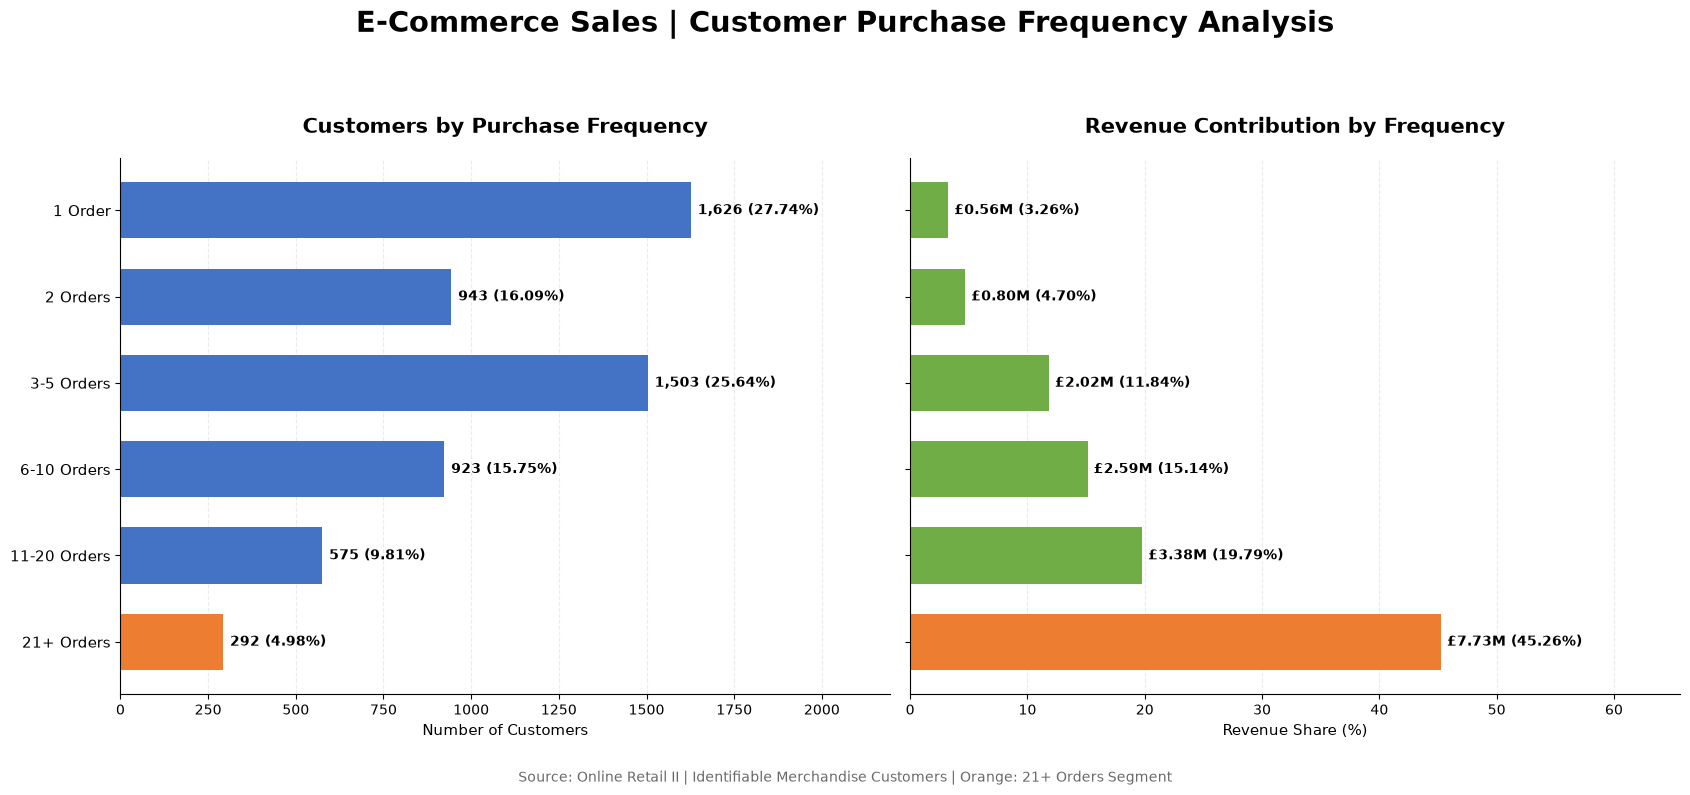

Chart saved: images\eda_04_05_purchase_frequency_analysis.png
EDA-04-05-03-02 Purchase Frequency Visualization: PASS


In [49]:

# EDA-04-05-03-02 | Purchase Frequency Visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# 1. Prepare purchase frequency summary
# --------------------------------------------------

segments = [
    "1 Order",
    "2 Orders",
    "3-5 Orders",
    "6-10 Orders",
    "11-20 Orders",
    "21+ Orders"
]

# Verified results from EDA-04-05-03-01
# Use existing summary DataFrame when available.

required_cols = {
    "Frequency_Segment",
    "Customers",
    "Revenue_GBP",
    "Customer_Share_Pct",
    "Revenue_Share_Pct"
}

candidates = [
    (name, obj)
    for name, obj in list(globals().items())
    if isinstance(obj, pd.DataFrame)
    and required_cols.issubset(obj.columns)
]

if not candidates:
    raise NameError(
        "Purchase frequency summary not found. "
        "Run EDA-04-05-03-01 first."
    )

# Prefer an exact match, if available
preferred_names = [
    "frequency_segment_summary",
    "frequency_summary",
    "purchase_frequency_summary"
]

selected = next(
    (
        (name, df)
        for preferred in preferred_names
        for name, df in candidates
        if name == preferred
    ),
    candidates[0]
)

source_name, freq_plot = selected
freq_plot = freq_plot.copy()

freq_plot["Frequency_Segment"] = (
    freq_plot["Frequency_Segment"].astype(str)
)

freq_plot = (
    freq_plot
    .set_index("Frequency_Segment")
    .reindex(segments)
    .reset_index()
)

assert freq_plot["Customers"].notna().all(), (
    "Missing purchase frequency segments."
)

print("Source DataFrame:", source_name)

# --------------------------------------------------
# 2. Visualization
# --------------------------------------------------

blue = "#4472C4"
green = "#70AD47"
orange = "#ED7D31"

colors_left = [
    orange if s == "21+ Orders" else blue
    for s in segments
]

colors_right = [
    orange if s == "21+ Orders" else green
    for s in segments
]

fig, axes = plt.subplots(
    1, 2, figsize=(17, 8), sharey=True
)

y = np.arange(len(segments))

# Left: Customer distribution
ax1 = axes[0]

bars1 = ax1.barh(
    y,
    freq_plot["Customers"],
    color=colors_left,
    height=0.65
)

ax1.set_yticks(y)
ax1.set_yticklabels(segments, fontsize=11)
ax1.invert_yaxis()

ax1.set_title(
    "Customers by Purchase Frequency",
    fontsize=15, fontweight="bold", pad=18
)

ax1.set_xlabel("Number of Customers", fontsize=11)
ax1.set_xlim(0, freq_plot["Customers"].max() * 1.35)

for bar, (_, row) in zip(bars1, freq_plot.iterrows()):
    ax1.text(
        bar.get_width() + 20,
        bar.get_y() + bar.get_height() / 2,
        f"{int(row['Customers']):,} "
        f"({row['Customer_Share_Pct']:.2f}%)",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

# Right: Revenue contribution
ax2 = axes[1]

bars2 = ax2.barh(
    y,
    freq_plot["Revenue_Share_Pct"],
    color=colors_right,
    height=0.65
)

ax2.set_title(
    "Revenue Contribution by Frequency",
    fontsize=15, fontweight="bold", pad=18
)

ax2.set_xlabel("Revenue Share (%)", fontsize=11)
ax2.set_xlim(
    0,
    freq_plot["Revenue_Share_Pct"].max() * 1.45
)

for bar, (_, row) in zip(bars2, freq_plot.iterrows()):
    ax2.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"£{row['Revenue_GBP']/1e6:.2f}M "
        f"({row['Revenue_Share_Pct']:.2f}%)",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

# --------------------------------------------------
# 3. Styling
# --------------------------------------------------

for ax in axes:
    ax.grid(axis="x", linestyle="--", alpha=0.25)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "E-Commerce Sales | Customer Purchase Frequency Analysis",
    fontsize=21,
    fontweight="bold",
    y=0.99
)

fig.text(
    0.5, 0.025,
    "Source: Online Retail II | "
    "Identifiable Merchandise Customers | "
    "Orange: 21+ Orders Segment",
    ha="center",
    fontsize=10,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.06, 1, 0.93])

# --------------------------------------------------
# 4. Save chart
# --------------------------------------------------

output_dir = Path("images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir /
    "eda_04_05_purchase_frequency_analysis.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Chart saved: {output_path}")
print("EDA-04-05-03-02 Purchase Frequency Visualization: PASS")



### EDA-04-05-03-02 | Interpretation

**Key Findings**

1. **Revenue Concentration Among High-Frequency Customers**
   - Customers with 21+ orders account for only 4.98% of identifiable customers.
   - However, they generate £7.73M, representing 45.26% of identifiable customer revenue.
   - This indicates substantial revenue concentration among high-frequency buyers.

2. **Limited Revenue Contribution from One-Time Customers**
   - One-time customers represent 27.74% of the customer base.
   - Their revenue contribution is only 3.26% (£0.56M).
   - This highlights the difference between customer acquisition and revenue contribution.

3. **Increasing Revenue Contribution Across Frequency Segments**
   - Customers with 11–20 orders contribute 19.79% of revenue.
   - Combined with the 21+ orders segment, customers purchasing 11 or more times generate 65.05% of identifiable revenue.
   - These customers represent approximately 14.79% of the identifiable customer base.

**Business Implications**

- Prioritize further analysis of high-frequency customers to understand their purchasing behavior and revenue dependence.
- Investigate opportunities to encourage additional purchases among low-frequency customers.
- Apply RFM segmentation to distinguish frequent, recent, and high-value customers.
- Examine whether unusually frequent purchasing reflects wholesale or bulk-order activity.

**Limitations**

- The analysis excludes transactions without identifiable Customer IDs.
- Purchase frequency reflects observed invoice counts, not a longitudinal customer retention rate.
- The results describe associations and do not establish that increasing purchase frequency will cause higher revenue.

**Conclusion**

Customer revenue is disproportionately concentrated among high-frequency buyers. Purchase frequency provides an important foundation for customer segmentation, retention strategy development, and subsequent RFM analysis.



## EDA-04-05-04 | Customer Revenue Concentration & Pareto Analysis

### EDA-04-05-04-01 | Customer Revenue Concentration Calculation

**Objective**

Evaluate the concentration of merchandise revenue among identifiable customers and determine the proportion of customers responsible for generating 80% of total identifiable customer revenue.

**Analysis Scope**
- Dataset: Online Retail II
- Population: Identifiable merchandise customers
- Ranking Metric: Total Revenue per Customer (GBP)
- Concentration Thresholds: Top 1%, 5%, 10%, 20%
- Pareto Threshold: 80% of identifiable customer revenue

**Methodology**
1. Aggregate merchandise revenue by Customer ID.
2. Rank customers in descending order of total revenue.
3. Calculate individual and cumulative revenue shares.
4. Measure revenue contribution from the top customer percentiles.
5. Identify the minimum number of customers required to reach 80% of revenue.
6. Validate revenue reconciliation and cumulative revenue calculations.


In [50]:

# EDA-04-05-04 | Find Customer-Level DataFrame

import pandas as pd

print("=== Customer-Level DataFrame Candidates ===")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame) and len(obj) == 5862:
        print(f"\nVariable: {name}")
        print(f"Rows: {len(obj):,}")
        print(f"Columns: {list(obj.columns)}")
        print(obj.head(3).to_string(index=False))


=== Customer-Level DataFrame Candidates ===

Variable: customer_summary_df
Rows: 5,862
Columns: ['Customer_ID', 'Total_Revenue_GBP', 'Unique_Orders', 'Records', 'AOV_GBP', 'Revenue_Share_Pct', 'Revenue_Rank']
 Customer_ID  Total_Revenue_GBP  Unique_Orders  Records     AOV_GBP  Revenue_Share_Pct  Revenue_Rank
       18102          580987.04            145     1040 4006.807172           3.400275             1
       14646          526751.52            145     3819 3632.769103           3.082857             2
       14156          305259.17            151     4033 2021.583907           1.786555             3

Variable: frequency_df
Rows: 5,862
Columns: ['Customer_ID', 'Total_Revenue_GBP', 'Unique_Orders', 'Records', 'AOV_GBP', 'Revenue_Share_Pct', 'Revenue_Rank', 'Customer_Type', 'Frequency_Segment']
 Customer_ID  Total_Revenue_GBP  Unique_Orders  Records     AOV_GBP  Revenue_Share_Pct  Revenue_Rank   Customer_Type Frequency_Segment
       18102          580987.04            145     1040 

In [51]:

# EDA-04-05-04-01
# Customer Revenue Concentration Analysis

import pandas as pd
import numpy as np

# 1. Use validated customer-level data
customer_concentration_df = (
    customer_summary_df.copy()
    .sort_values("Total_Revenue_GBP", ascending=False)
    .reset_index(drop=True)
)

# 2. Calculate revenue shares
total_customer_revenue = (
    customer_concentration_df["Total_Revenue_GBP"].sum()
)

customer_concentration_df["Revenue_Rank"] = (
    np.arange(1, len(customer_concentration_df) + 1)
)

customer_concentration_df["Revenue_Share_Pct"] = (
    customer_concentration_df["Total_Revenue_GBP"]
    / total_customer_revenue * 100
)

customer_concentration_df["Cumulative_Revenue_Pct"] = (
    customer_concentration_df["Revenue_Share_Pct"].cumsum()
)

# 3. Concentration metrics
total_customers = len(customer_concentration_df)

top_10_share = customer_concentration_df.head(10)[
    "Revenue_Share_Pct"
].sum()

top_50_share = customer_concentration_df.head(50)[
    "Revenue_Share_Pct"
].sum()

top_100_share = customer_concentration_df.head(100)[
    "Revenue_Share_Pct"
].sum()

customers_80 = int(
    np.searchsorted(
        customer_concentration_df["Cumulative_Revenue_Pct"].to_numpy(),
        80,
        side="left"
    ) + 1
)

customer_share_80 = customers_80 / total_customers * 100

# 4. Summary
concentration_summary = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Total Identified Revenue (£)",
        "Top 10 Revenue Share (%)",
        "Top 50 Revenue Share (%)",
        "Top 100 Revenue Share (%)",
        "Customers to Reach 80% Revenue",
        "Customer Share to Reach 80% (%)"
    ],
    "Value": [
        total_customers,
        total_customer_revenue,
        top_10_share,
        top_50_share,
        top_100_share,
        customers_80,
        customer_share_80
    ]
})

print("=== Customer Revenue Concentration Summary ===")
display(concentration_summary.round(2))

print("\n=== Top 15 Customers | Revenue Concentration ===")
display(
    customer_concentration_df[
        [
            "Revenue_Rank",
            "Customer_ID",
            "Total_Revenue_GBP",
            "Revenue_Share_Pct",
            "Cumulative_Revenue_Pct"
        ]
    ].head(15).round(2)
)

# 5. Validation
assert total_customers == 5862
assert np.isclose(total_customer_revenue, 17086472.20, atol=0.01)
assert np.isclose(
    customer_concentration_df["Revenue_Share_Pct"].sum(),
    100,
    atol=0.01
)
assert customer_concentration_df[
    "Cumulative_Revenue_Pct"
].is_monotonic_increasing
assert (
    customer_concentration_df.loc[customers_80 - 1, "Cumulative_Revenue_Pct"]
    >= 80
)

print(
    "\nEDA-04-05-04-01 Customer Revenue Concentration: PASS"
)


=== Customer Revenue Concentration Summary ===


,Metric,Value
0,Total Customers,5862.00
1,Total Identified Revenue (£),17086472.20
2,Top 10 Revenue Share (%),16.18
3,Top 50 Revenue Share (%),30.49
4,Top 100 Revenue Share (%),37.67
5,Customers to Reach 80% Revenue,1353.00
6,Customer Share to Reach 80% (%),23.08



=== Top 15 Customers | Revenue Concentration ===


,Revenue_Rank,Customer_ID,Total_Revenue_GBP,Revenue_Share_Pct,Cumulative_Revenue_Pct
0,1,18102,580987.04,3.40,3.40
1,2,14646,526751.52,3.08,6.48
2,3,14156,305259.17,1.79,8.27
3,4,14911,280041.15,1.64,9.91
4,5,17450,244784.25,1.43,11.34
5,6,13694,195640.69,1.15,12.49
6,7,17511,172132.87,1.01,13.49
7,8,16446,168472.50,0.99,14.48
8,9,16684,147142.77,0.86,15.34
9,10,12415,144033.37,0.84,16.18



EDA-04-05-04-01 Customer Revenue Concentration: PASS


### EDA-04-05-04-01 | Final Interpretation

**Key Findings**

- 전체 5,862명의 식별 고객이 약 £17.09M의 매출을 창출했다.
- 매출 상위 10명의 고객이 전체 식별 고객 매출의 16.18%를 차지하며, 상위 100명까지 확대하면 매출 기여도는 37.67%에 달한다.
- 전체 고객의 23.08%에 해당하는 1,353명이 누적 매출의 80%를 창출한다.
- 고객별 매출 기여도는 균등하지 않으며, 상대적으로 소수의 고매출 고객에게 집중되어 있다.

**Business Implications**

- 고매출 고객에 대한 유지 및 이탈 방지 전략은 매출 안정성 측면에서 중요하다.
- 상위 고객군을 대상으로 구매 빈도, 객단가(AOV), 최근 구매 시점 등을 추가 분석하여 차별화된 CRM 전략을 수립할 필요가 있다.
- 고객 매출 집중도가 높기 때문에 핵심 고객군에 대한 의존도와 잠재적인 매출 변동 위험도 함께 관리해야 한다.

**Analytical Limitations**

- 본 분석은 Customer ID가 확인된 고객과 매출만을 대상으로 한다.
- 매출 기여도는 고객의 수익성이나 미래 고객생애가치(CLV)를 직접적으로 나타내지는 않는다.
- 고객별 구매 빈도와 매출 집중도 간의 관계는 추가적인 분석이 필요하다.

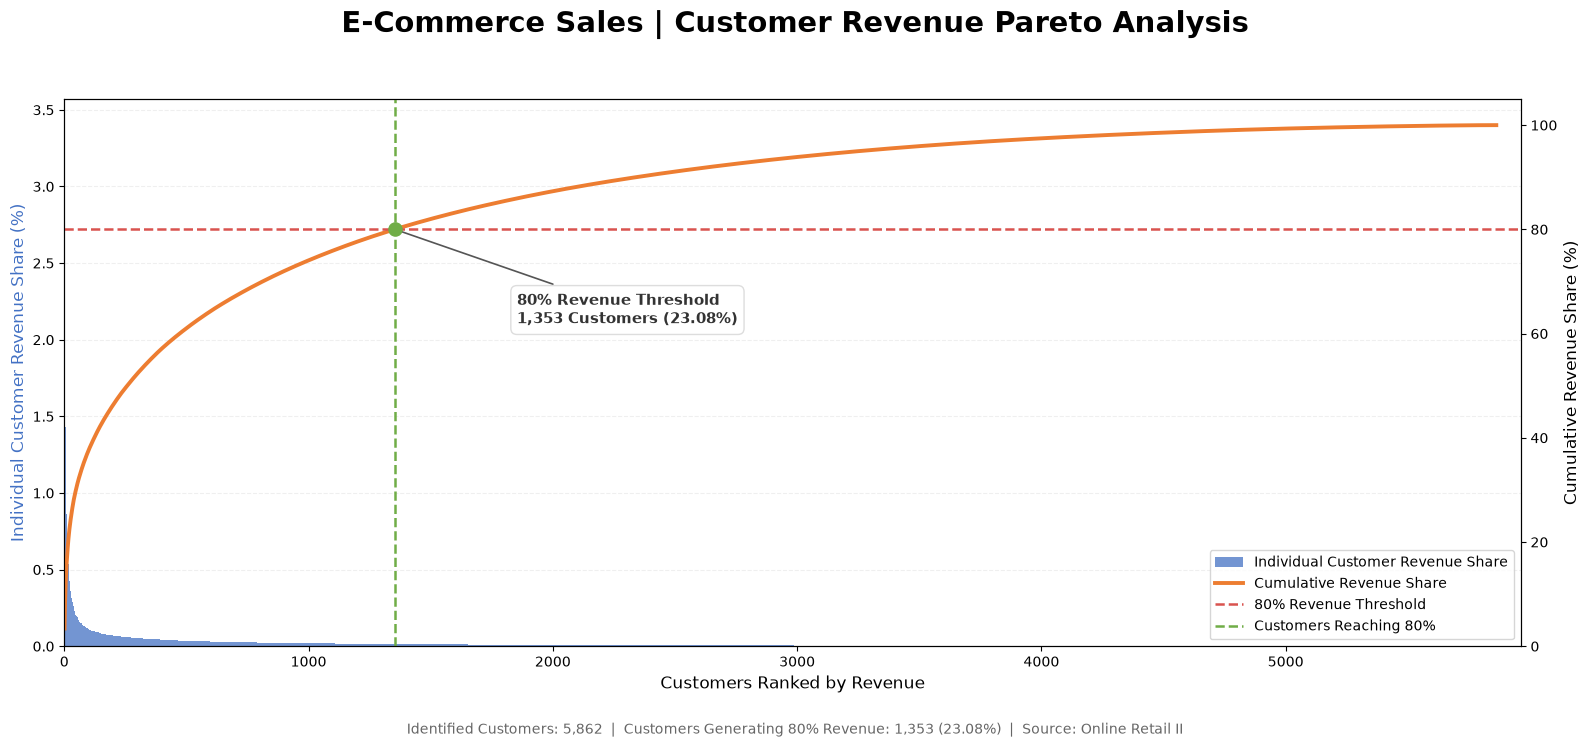

Chart saved: images\eda_04_05_customer_revenue_pareto.png
EDA-04-05-04-02 Customer Revenue Pareto Chart: PASS


In [52]:

# EDA-04-05-04-02 | Customer Revenue Pareto Analysis

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Validate input
assert "customer_concentration_df" in globals()

pareto_df = customer_concentration_df.copy()

required_cols = [
    "Revenue_Rank",
    "Revenue_Share_Pct",
    "Cumulative_Revenue_Pct"
]
assert set(required_cols).issubset(pareto_df.columns)

pareto_df = pareto_df.sort_values("Revenue_Rank")

# 2. Calculate 80% threshold
total_customers = len(pareto_df)

threshold_idx = np.searchsorted(
    pareto_df["Cumulative_Revenue_Pct"].to_numpy(),
    80,
    side="left"
)

customers_80 = threshold_idx + 1
customer_pct_80 = customers_80 / total_customers * 100

# 3. Prepare chart data
x = np.arange(1, total_customers + 1)
individual_share = pareto_df["Revenue_Share_Pct"].to_numpy()
cumulative_share = pareto_df["Cumulative_Revenue_Pct"].to_numpy()

# 4. Create chart
fig, ax1 = plt.subplots(figsize=(16, 7.5))

# Individual customer revenue share
ax1.bar(
    x,
    individual_share,
    color="#4472C4",
    alpha=0.75,
    width=1.0,
    label="Individual Customer Revenue Share"
)

ax1.set_xlabel(
    "Customers Ranked by Revenue",
    fontsize=12
)
ax1.set_ylabel(
    "Individual Customer Revenue Share (%)",
    fontsize=12,
    color="#4472C4"
)

ax1.set_xlim(0, total_customers + 100)
ax1.grid(axis="y", linestyle="--", alpha=0.2)
ax1.set_axisbelow(True)

# Cumulative revenue share
ax2 = ax1.twinx()

ax2.plot(
    x,
    cumulative_share,
    color="#ED7D31",
    linewidth=2.8,
    label="Cumulative Revenue Share"
)

ax2.axhline(
    80,
    color="#D9534F",
    linestyle="--",
    linewidth=1.8,
    label="80% Revenue Threshold"
)

ax2.axvline(
    customers_80,
    color="#70AD47",
    linestyle="--",
    linewidth=1.8,
    label="Customers Reaching 80%"
)

ax2.scatter(
    customers_80,
    cumulative_share[threshold_idx],
    color="#70AD47",
    s=90,
    zorder=5
)

ax2.set_ylabel(
    "Cumulative Revenue Share (%)",
    fontsize=12
)
ax2.set_ylim(0, 105)

# 5. Annotation
ax2.annotate(
    f"80% Revenue Threshold\n"
    f"{customers_80:,} Customers ({customer_pct_80:.2f}%)",
    xy=(customers_80, cumulative_share[threshold_idx]),
    xytext=(customers_80 + 500, 62),
    fontsize=11,
    fontweight="bold",
    color="#333333",
    arrowprops=dict(
        arrowstyle="-",
        color="#555555",
        linewidth=1.2
    ),
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="#DDDDDD"
    )
)

# 6. Title and legend
fig.suptitle(
    "E-Commerce Sales | Customer Revenue Pareto Analysis",
    fontsize=21,
    fontweight="bold",
    y=0.98
)

handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

ax2.legend(
    handles1 + handles2,
    labels1 + labels2,
    loc="lower right",
    fontsize=10,
    frameon=True
)

# 7. Footer
fig.text(
    0.5,
    0.015,
    f"Identified Customers: {total_customers:,}  |  "
    f"Customers Generating 80% Revenue: "
    f"{customers_80:,} ({customer_pct_80:.2f}%)  |  "
    "Source: Online Retail II",
    ha="center",
    fontsize=10,
    color="#666666"
)

plt.tight_layout(rect=[0, 0.05, 1, 0.94])

# 8. Save chart
output_dir = Path("images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "eda_04_05_customer_revenue_pareto.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# 9. Validation
assert customers_80 == 1353
assert np.isclose(customer_pct_80, 23.08, atol=0.01)
assert np.isclose(cumulative_share[-1], 100, atol=0.01)

print(f"Chart saved: {output_path}")
print("EDA-04-05-04-02 Customer Revenue Pareto Chart: PASS")


### EDA-04-05-04-02 | Final Interpretation

**Key Findings**

- Customer Revenue Pareto Analysis 결과, 전체 식별 고객 5,862명 중 상위 1,353명(23.08%)이 전체 식별 고객 매출의 80%를 창출하는 것으로 나타났다.
- 상위 10명의 고객은 전체 매출의 16.18%, 상위 100명은 37.67%를 차지한다.
- 누적 매출 곡선은 상위 고객 구간에서 빠르게 증가한 이후 점차 완만해지며, 고객별 매출 기여도의 불균형을 보여준다.
- 이러한 결과는 소수의 고매출 고객이 전체 매출에서 상대적으로 높은 비중을 차지하는 매출 집중 구조를 의미한다.

**Business Implications**

- **High-Value Customer Retention:** 상위 매출 고객군에 대한 유지 및 이탈 방지 전략을 우선적으로 검토할 필요가 있다.
- **Targeted CRM Strategy:** 고객별 구매 빈도와 객단가를 결합하여 충성 고객 및 고매출 고객을 대상으로 차별화된 CRM 전략을 수립할 수 있다.
- **Revenue Risk Management:** 상위 고객에 대한 매출 의존도를 지속적으로 모니터링하여 고객 이탈에 따른 잠재적인 매출 위험을 관리해야 한다.
- **Customer Development:** 중간 매출 고객군의 재구매 및 구매 금액 확대 가능성을 분석하여 고객 기반을 강화할 필요가 있다.

**Analytical Limitations**

- 본 분석은 Customer ID가 확인된 고객의 매출만을 포함한다.
- 매출 집중도는 고객의 실제 수익성이나 미래 고객생애가치(CLV)를 직접적으로 설명하지 않는다.
- 고매출 고객의 구매 패턴과 향후 구매 가능성을 파악하기 위해서는 RFM 분석 등 추가적인 고객 행동 분석이 필요하다.

In [53]:

# EDA-04-05-05-01 | Customer Performance Final Validation

import pandas as pd
import numpy as np

# 1. Required DataFrames
required_dfs = [
    "customer_summary_df",
    "frequency_df",
    "customer_concentration_df"
]

for name in required_dfs:
    assert name in globals(), f"Missing DataFrame: {name}"

customers = customer_summary_df.copy()
frequency = frequency_df.copy()
pareto = customer_concentration_df.copy()

# 2. Reference metrics
expected_customers = 5862
expected_revenue = 17086472.20

total_revenue = customers["Total_Revenue_GBP"].sum()

# 3. Validation checks
checks = {}

checks["Customer Coverage"] = (
    len(customers) == expected_customers
)

checks["Identified Revenue"] = np.isclose(
    total_revenue,
    expected_revenue,
    atol=0.01
)

checks["Customer ID Uniqueness"] = (
    customers["Customer_ID"].is_unique
    and customers["Customer_ID"].notna().all()
)

checks["Customer Revenue Share"] = np.isclose(
    customers["Revenue_Share_Pct"].sum(),
    100,
    atol=0.01
)

ranked_customers = customers.sort_values(
    "Total_Revenue_GBP", ascending=False
)

checks["Revenue Ranking"] = (
    ranked_customers["Revenue_Rank"].tolist()
    == list(range(1, len(customers) + 1))
)

checks["Customer Type Coverage"] = (
    frequency["Customer_Type"].notna().all()
    and set(frequency["Customer_Type"].unique())
    == {"One-time Customer", "Repeat Customer"}
    and (
        (frequency["Unique_Orders"] == 1)
        == (frequency["Customer_Type"] == "One-time Customer")
    ).all()
)

checks["Purchase Frequency Coverage"] = (
    frequency["Frequency_Segment"].notna().all()
    and set(frequency["Frequency_Segment"].unique())
    == {
        "1 Order",
        "2 Orders",
        "3-5 Orders",
        "6-10 Orders",
        "11-20 Orders",
        "21+ Orders"
    }
)

checks["Frequency Customer Reconciliation"] = (
    len(frequency) == expected_customers
    and frequency["Customer_ID"].is_unique
    and set(frequency["Customer_ID"])
    == set(customers["Customer_ID"])
)

checks["Frequency Revenue Reconciliation"] = np.isclose(
    frequency["Total_Revenue_GBP"].sum(),
    total_revenue,
    atol=0.01
)

pareto_sorted = pareto.sort_values("Revenue_Rank")

checks["Pareto Cumulative Share"] = (
    pareto_sorted["Cumulative_Revenue_Pct"].is_monotonic_increasing
    and np.isclose(
        pareto_sorted["Cumulative_Revenue_Pct"].iloc[-1],
        100,
        atol=0.01
    )
)

threshold_position = int(
    np.searchsorted(
        pareto_sorted["Cumulative_Revenue_Pct"].to_numpy(),
        80,
        side="left"
    ) + 1
)

checks["Pareto 80% Threshold"] = (
    threshold_position == 1353
    and pareto_sorted["Cumulative_Revenue_Pct"].iloc[
        threshold_position - 1
    ] >= 80
    and (
        threshold_position == 1
        or pareto_sorted["Cumulative_Revenue_Pct"].iloc[
            threshold_position - 2
        ] < 80
    )
)

# 4. Validation report
validation_df = pd.DataFrame({
    "Validation": list(checks.keys()),
    "Status": [
        "PASS" if result else "FAIL"
        for result in checks.values()
    ]
})

print("=== Customer Performance Final Validation ===")
display(validation_df)

# 5. KPI summary
top10_share = pareto_sorted.head(10)[
    "Revenue_Share_Pct"
].sum()

repeat_customers = (
    frequency["Customer_Type"] == "Repeat Customer"
).sum()

repeat_revenue = frequency.loc[
    frequency["Customer_Type"] == "Repeat Customer",
    "Total_Revenue_GBP"
].sum()

kpi_df = pd.DataFrame({
    "Metric": [
        "Identified Customers",
        "Identified Revenue (£)",
        "Repeat Customers",
        "Repeat Customer Rate (%)",
        "Repeat Revenue Share (%)",
        "Top 10 Customer Revenue Share (%)",
        "Customers to Reach 80% Revenue",
        "Customer Share to Reach 80% (%)"
    ],
    "Value": [
        len(customers),
        total_revenue,
        repeat_customers,
        repeat_customers / len(customers) * 100,
        repeat_revenue / total_revenue * 100,
        top10_share,
        threshold_position,
        threshold_position / len(customers) * 100
    ]
})

print("\n=== Customer Performance KPI Summary ===")
display(kpi_df.round(2))

# 6. Final assessment
passed = sum(bool(v) for v in checks.values())
failed = len(checks) - passed

print("\n=== Final Assessment ===")
print(f"Validation Checks: {len(checks)}")
print(f"Passed: {passed}")
print(f"Failed: {failed}")

if failed == 0:
    print(
        "\nEDA-04-05-05-01 "
        "Customer Performance Final Validation: PASS"
    )
else:
    print(
        "\nEDA-04-05-05-01 "
        "Customer Performance Final Validation: FAIL"
    )
    print("Failed checks:")
    for name, result in checks.items():
        if not result:
            print(f" - {name}")


=== Customer Performance Final Validation ===


,Validation,Status
0,Customer Coverage,PASS
1,Identified Revenue,PASS
2,Customer ID Uniqueness,PASS
3,Customer Revenue Share,PASS
4,Revenue Ranking,PASS
5,Customer Type Coverage,PASS
6,Purchase Frequency Coverage,PASS
7,Frequency Customer Reconciliation,PASS
8,Frequency Revenue Reconciliation,PASS
9,Pareto Cumulative Share,PASS



=== Customer Performance KPI Summary ===


,Metric,Value
0,Identified Customers,5862.00
1,Identified Revenue (£),17086472.20
2,Repeat Customers,4236.00
3,Repeat Customer Rate (%),72.26
4,Repeat Revenue Share (%),96.74
5,Top 10 Customer Revenue Share (%),16.18
6,Customers to Reach 80% Revenue,1353.00
7,Customer Share to Reach 80% (%),23.08



=== Final Assessment ===
Validation Checks: 11
Passed: 11
Failed: 0

EDA-04-05-05-01 Customer Performance Final Validation: PASS


### EDA-04-05-05-01 | Final Interpretation

**Validation Results**

- Customer Performance Analysis의 최종 검증 결과, 총 11개 Validation Check가 모두 PASS되었다.
- 고객 수 5,862명과 식별 고객 매출 £17.09M이 기존 집계 결과와 일치하는 것으로 확인되었다.
- 고객별 매출 순위, 매출 비중, 구매 빈도 분류 및 누적 매출 계산의 정합성이 검증되었다.
- Customer Revenue Pareto Analysis의 80% 매출 기준점 역시 정상적으로 검증되었다.

**Key Findings**

- **Repeat Purchase Contribution:** 반복 구매 고객 4,236명(72.26%)이 식별 고객 매출의 96.74%를 창출했다.
- **Customer Revenue Concentration:** 전체 식별 고객의 23.08%에 해당하는 1,353명이 매출의 80%를 차지했다.
- **High-Value Customer Dependence:** 상위 10명의 고객이 전체 식별 고객 매출의 16.18%를 차지하며, 고매출 고객에 대한 매출 집중 현상이 확인되었다.

**Business Implications**

- 반복 구매 고객의 유지 및 재구매 활성화를 CRM 전략의 주요 과제로 설정할 필요가 있다.
- 고매출 고객군을 대상으로 구매 행동과 이탈 위험을 추가 분석하여 고객별 차별화된 관리 전략을 수립할 수 있다.
- 고객 매출 집중도에 따른 잠재적인 매출 변동 위험을 모니터링할 필요가 있다.
- 향후 RFM Analysis를 통해 고객의 최근 구매 시점(Recency), 구매 빈도(Frequency), 구매 금액(Monetary)을 결합한 세분화 전략을 검토할 수 있다.

**Analytical Limitations**

- 전체 Merchandise Revenue 중 Customer ID가 확인된 매출만 고객 분석에 포함되었다.
- 반복 구매 비율은 분석 기간 내 구매 횟수를 기준으로 산출되었으며, 장기적인 고객 유지율(Retention Rate)과 동일하지 않다.
- 본 분석 결과는 고객별 매출 기여도를 설명하지만, 고객 수익성이나 미래 고객생애가치(CLV)를 직접적으로 측정하지 않는다.

**Final Assessment**

Customer Performance Analysis는 데이터 정합성 검증을 모두 통과했으며, 고객 구매 행동과 매출 집중도에 관한 후속 비즈니스 분석에 활용할 수 있는 기반을 확보하였다.

## EDA-04-06 | Integrated EDA Summary

### EDA-04-06-01 | Integrated KPI Summary

**Objective**

Consolidate key performance indicators across sales, geographic,
product, and customer analyses to establish a unified view of
e-commerce business performance.

**Scope**
- Sales Performance
- Geographic Performance
- Product Performance
- Customer Performance

In [54]:
# ============================================================
# EDA-04-06-01 | Integrated KPI Summary
# ============================================================

import pandas as pd

# 1. Previously validated KPI values

total_revenue = 19_669_952.77
total_records = 1_003_792

total_countries = 43
uk_revenue_share = 85.481944
international_revenue_share = 14.518056

total_products = 4_911
top10_product_share = 8.00
product_pareto_share = 21.22

identified_customers = 5_862
identified_revenue = 17_086_472.20

repeat_customer_rate = 72.26
repeat_revenue_share = 96.74
customer_pareto_share = 23.08

# 2. Create integrated KPI table

integrated_kpi_df = pd.DataFrame([
    ["Sales", "Total Revenue (£)", total_revenue],
    ["Sales", "Total Records", total_records],

    ["Geographic", "Total Countries", total_countries],
    ["Geographic", "UK Revenue Share (%)", uk_revenue_share],
    ["Geographic", "International Revenue Share (%)",
     international_revenue_share],

    ["Product", "Total Products", total_products],
    ["Product", "Top 10 Revenue Share (%)",
     top10_product_share],
    ["Product", "Products Generating 80% Revenue (%)",
     product_pareto_share],

    ["Customer", "Identified Customers",
     identified_customers],
    ["Customer", "Identified Revenue (£)",
     identified_revenue],
    ["Customer", "Repeat Customer Rate (%)",
     repeat_customer_rate],
    ["Customer", "Repeat Revenue Share (%)",
     repeat_revenue_share],
    ["Customer", "Customers Generating 80% Revenue (%)",
     customer_pareto_share]

], columns=["Category", "Metric", "Value"])

# 3. Display results

print("=== Integrated EDA KPI Summary ===")
display(integrated_kpi_df)

# 4. Revenue coverage validation

customer_revenue_coverage = (
    identified_revenue / total_revenue * 100
)

print("\n=== Revenue Coverage ===")
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Identified Revenue: £{identified_revenue:,.2f}")
print(
    f"Customer Revenue Coverage: "
    f"{customer_revenue_coverage:.2f}%"
)

# 5. Basic validation

assert len(integrated_kpi_df) == 13
assert abs(
    uk_revenue_share + international_revenue_share - 100
) < 0.01

assert identified_revenue <= total_revenue

print(
    "\nEDA-04-06-01 Integrated KPI Summary: PASS"
)

=== Integrated EDA KPI Summary ===


,Category,Metric,Value
0,Sales,Total Revenue (£),1.966995e+07
1,Sales,Total Records,1.003792e+06
2,Geographic,Total Countries,4.300000e+01
3,Geographic,UK Revenue Share (%),8.548194e+01
4,Geographic,International Revenue Share (%),1.451806e+01
5,Product,Total Products,4.911000e+03
6,Product,Top 10 Revenue Share (%),8.000000e+00
7,Product,Products Generating 80% Revenue (%),2.122000e+01
8,Customer,Identified Customers,5.862000e+03
9,Customer,Identified Revenue (£),1.708647e+07



=== Revenue Coverage ===
Total Revenue: £19,669,952.77
Identified Revenue: £17,086,472.20
Customer Revenue Coverage: 86.87%

EDA-04-06-01 Integrated KPI Summary: PASS


### Interpretation | Integrated KPI Summary

**Key Findings**

1. **Overall Sales Performance**
   - Total merchandise revenue reached £19.67M across 1,003,792 transaction records.
   - The dataset covers 43 countries and 4,911 distinct products.

2. **Geographic Revenue Concentration**
   - The United Kingdom accounted for 85.48% of total revenue, while international markets contributed 14.52%.
   - This indicates substantial geographic revenue concentration and dependence on the domestic market.

3. **Product Revenue Distribution**
   - The top 10 products generated 8.00% of total merchandise revenue.
   - Approximately 21.22% of products accounted for 80% of revenue, indicating a moderately concentrated product portfolio.

4. **Customer Revenue Concentration**
   - Repeat customers represented 72.26% of identified customers and contributed 96.74% of identified customer revenue.
   - Approximately 23.08% of identified customers generated 80% of identified revenue, highlighting the importance of high-value customer relationships.

5. **Data Coverage Limitation**
   - Identifiable customer transactions represented 86.87% of total merchandise revenue.
   - Customer-level insights should therefore be interpreted within the identifiable customer population rather than the entire transaction dataset.

**Business Implications**

- Prioritize customer retention and relationship management given the substantial revenue contribution from repeat customers.
- Evaluate international market diversification opportunities to reduce geographic concentration risk.
- Optimize product portfolio management by considering both revenue contribution and sales volume.
- Maintain clear distinctions between overall merchandise performance and identifiable customer performance when making strategic recommendations.

### EDA-04-06-02 | Cross-Dimensional Insights

**Objective**

Integrate geographic, product, and customer performance
metrics to identify revenue concentration patterns,
customer dependency, and potential business opportunities.

**Analysis Scope**

- Geographic Revenue Concentration
- Product Revenue Concentration
- Customer Revenue Concentration
- Repeat Customer Revenue Dependency
- Cross-Dimensional Business Implications

In [55]:
# EDA-04-06-02-01 | Cross-Dimensional KPI Comparison

import pandas as pd

# --------------------------------------------------
# 1. Define validated KPIs
# --------------------------------------------------

cross_dimensional_kpis = {
    "Geographic": {
        "Metric": "UK Revenue Share",
        "Value": 85.48,
        "Unit": "%",
        "Basis": "Total Merchandise Revenue"
    },
    "Product": {
        "Metric": "Products Generating 80% Revenue",
        "Value": 21.22,
        "Unit": "%",
        "Basis": "Total Products"
    },
    "Customer": {
        "Metric": "Customers Generating 80% Revenue",
        "Value": 23.08,
        "Unit": "%",
        "Basis": "Identified Customers"
    },
    "Repeat Customer": {
        "Metric": "Repeat Customer Revenue Share",
        "Value": 96.74,
        "Unit": "%",
        "Basis": "Identified Customer Revenue"
    }
}

# --------------------------------------------------
# 2. Create comparison DataFrame
# --------------------------------------------------

cross_dimensional_df = pd.DataFrame.from_dict(
    cross_dimensional_kpis,
    orient="index"
).reset_index()

cross_dimensional_df.rename(
    columns={"index": "Dimension"},
    inplace=True
)

# --------------------------------------------------
# 3. Display results
# --------------------------------------------------

print("=== Cross-Dimensional KPI Comparison ===")

display(
    cross_dimensional_df.style.format({
        "Value": "{:.2f}"
    })
)

# --------------------------------------------------
# 4. Validation
# --------------------------------------------------

assert len(cross_dimensional_df) == 4

assert cross_dimensional_df["Value"].between(
    0, 100
).all()

assert cross_dimensional_df["Dimension"].is_unique

assert cross_dimensional_df["Basis"].notna().all()

print(
    "\nEDA-04-06-02-01 "
    "Cross-Dimensional KPI Comparison: PASS"
)

=== Cross-Dimensional KPI Comparison ===


,Dimension,Metric,Value,Unit,Basis
0,Geographic,UK Revenue Share,85.48,%,Total Merchandise Revenue
1,Product,Products Generating 80% Revenue,21.22,%,Total Products
2,Customer,Customers Generating 80% Revenue,23.08,%,Identified Customers
3,Repeat Customer,Repeat Customer Revenue Share,96.74,%,Identified Customer Revenue



EDA-04-06-02-01 Cross-Dimensional KPI Comparison: PASS


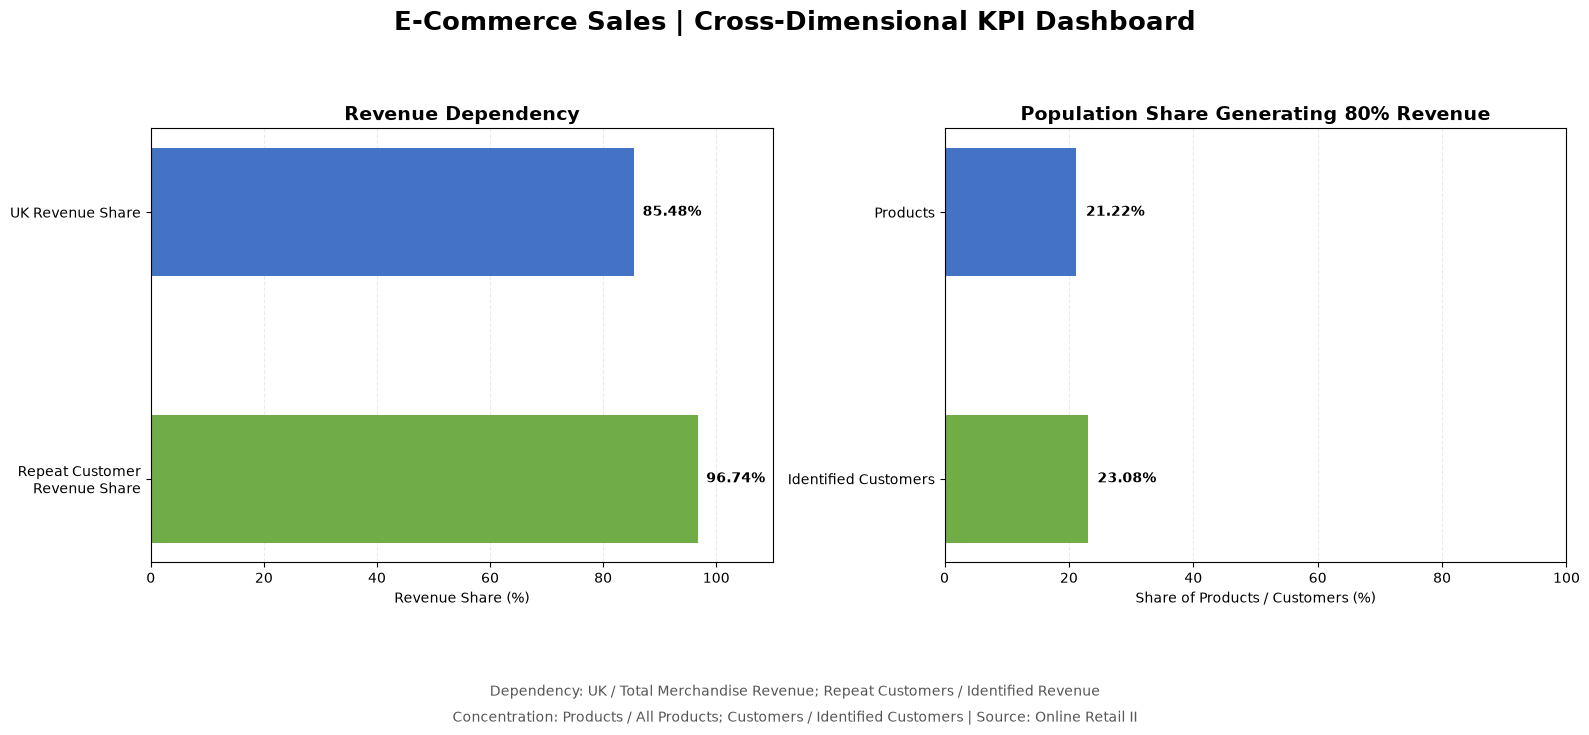

Chart saved: images\eda_04_06_cross_dimensional_kpi_dashboard.png
EDA-04-06-02-02 Cross-Dimensional Visualization: PASS


In [56]:
# EDA-04-06-02-02 | Cross-Dimensional Visualization

import matplotlib.pyplot as plt
from pathlib import Path

# --------------------------------------------------
# 1. Prepare KPI Data
# --------------------------------------------------

assert "cross_dimensional_df" in globals(), (
    "Run EDA-04-06-02-01 first."
)

kpi = cross_dimensional_df.set_index("Dimension")

dependency = kpi.loc[
    ["Geographic", "Repeat Customer"]
].copy()

concentration = kpi.loc[
    ["Product", "Customer"]
].copy()

# --------------------------------------------------
# 2. Create Dashboard
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6.5)
)

fig.suptitle(
    "E-Commerce Sales | Cross-Dimensional KPI Dashboard",
    fontsize=19,
    fontweight="bold",
    y=1.02
)

# Chart 1: Revenue Dependency

labels_1 = [
    "UK Revenue Share",
    "Repeat Customer\nRevenue Share"
]

values_1 = dependency["Value"].to_numpy()

bars1 = axes[0].barh(
    labels_1,
    values_1,
    color=["#4472C4", "#70AD47"],
    height=0.48
)

axes[0].invert_yaxis()
axes[0].set_xlim(0, 110)
axes[0].set_xlabel("Revenue Share (%)")
axes[0].set_title(
    "Revenue Dependency",
    fontsize=14,
    fontweight="bold"
)

for bar, value in zip(bars1, values_1):
    axes[0].text(
        value + 1.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontweight="bold"
    )

axes[0].grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

axes[0].set_axisbelow(True)

# Chart 2: Revenue Concentration

labels_2 = [
    "Products",
    "Identified Customers"
]

values_2 = concentration["Value"].to_numpy()

bars2 = axes[1].barh(
    labels_2,
    values_2,
    color=["#4472C4", "#70AD47"],
    height=0.48
)

axes[1].invert_yaxis()
axes[1].set_xlim(0, 100)
axes[1].set_xlabel(
    "Share of Products / Customers (%)"
)
axes[1].set_title(
    "Population Share Generating 80% Revenue",
    fontsize=14,
    fontweight="bold"
)

for bar, value in zip(bars2, values_2):
    axes[1].text(
        value + 1.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontweight="bold"
    )

axes[1].grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

axes[1].set_axisbelow(True)

# --------------------------------------------------
# 3. Add Data Scope Notes
# --------------------------------------------------

fig.text(
    0.5, -0.035,
    "Dependency: UK / Total Merchandise Revenue; "
    "Repeat Customers / Identified Revenue",
    ha="center",
    fontsize=10,
    color="#555555"
)

fig.text(
    0.5, -0.075,
    "Concentration: Products / All Products; "
    "Customers / Identified Customers | "
    "Source: Online Retail II",
    ha="center",
    fontsize=10,
    color="#555555"
)

plt.tight_layout(rect=[0, 0.08, 1, 0.96])

# --------------------------------------------------
# 4. Save Chart
# --------------------------------------------------

output_dir = Path("images")
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir /
    "eda_04_06_cross_dimensional_kpi_dashboard.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Chart saved: {output_path}")
print(
    "EDA-04-06-02-02 "
    "Cross-Dimensional Visualization: PASS"
)

### EDA-04-06-02-03 | Strategic Insights & Interpretation

**Objective**

Translate cross-dimensional KPI findings into actionable business insights related to revenue concentration, customer retention, product portfolio management, and international market development.

#### 1. Geographic Revenue Dependency

**Key Finding**
- The United Kingdom accounts for 85.48% of total merchandise revenue.
- International markets collectively contribute 14.52%.

**Business Implication**
- The business has substantial geographic revenue concentration.
- International market diversification may provide opportunities to reduce dependence on the UK market.

**Strategic Recommendation**
- Evaluate expansion opportunities in established international markets, particularly EIRE, the Netherlands, Germany, and France.
- Prioritize market development based on revenue potential, order frequency, and average order value.

#### 2. Customer Retention & Revenue Dependency

**Key Finding**
- Repeat customers account for 72.26% of identified customers.
- These customers generate 96.74% of identified customer revenue.
- The top 23.08% of identified customers contribute approximately 80% of identified revenue.

**Business Implication**
- Repeat purchasing is strongly associated with revenue contribution.
- Maintaining relationships with existing customers is an important commercial priority.

**Strategic Recommendation**
- Develop targeted retention campaigns for high-value and frequent customers.
- Use customer segmentation to differentiate loyalty, reactivation, and cross-selling strategies.
- Monitor revenue concentration among major customers to identify potential dependency risks.

#### 3. Product Portfolio Concentration

**Key Finding**
- The top 10 products generate 8.00% of total merchandise revenue.
- Approximately 21.22% of products contribute 80% of revenue.

**Business Implication**
- Revenue is concentrated within a subset of the product portfolio, although no single product dominates overall revenue.
- Product performance should be evaluated using both revenue and quantity sold.

**Strategic Recommendation**
- Prioritize inventory availability for consistently high-performing products.
- Investigate products with high sales volume but relatively low revenue contribution.
- Evaluate opportunities for bundling, cross-selling, and product assortment optimization.

#### 4. Integrated Business Priorities

**Priority 1 — Customer Retention**
- Protect revenue generated by repeat and high-value customers.
- Improve customer segmentation and retention monitoring.

**Priority 2 — Geographic Diversification**
- Evaluate opportunities to expand revenue contribution from established international markets.
- Reduce excessive reliance on a single geographic market over time.

**Priority 3 — Product Portfolio Optimization**
- Improve inventory and merchandising decisions using revenue and sales-volume analysis.
- Identify opportunities to increase revenue contribution from existing products.

#### 5. Analytical Limitations

- Customer-level analysis covers 86.87% of total merchandise revenue due to missing customer identifiers.
- Geographic, product, and customer concentration metrics use different denominators and should not be interpreted as directly equivalent measures of business risk.
- Findings are descriptive and do not establish causal relationships.
- Recommendations should be validated using additional profitability, customer acquisition cost, retention, and market demand data before implementation.

**Overall Conclusion**

The analysis identifies three important commercial priorities: strengthening repeat customer relationships, evaluating international diversification opportunities, and optimizing the product portfolio.

These findings provide an evidence-based foundation for further customer segmentation, marketing strategy development, and business performance monitoring.

### EDA-04-06-03 | Final EDA Validation & Summary

**Objective**

Validate the consistency, completeness, and reliability
of the integrated EDA results across four analytical dimensions.

**Validation Scope**

- Sales Revenue Reconciliation
- Geographic Revenue Reconciliation
- Product Revenue Reconciliation
- Customer Revenue Coverage
- Product and Customer Coverage
- Cross-Dimensional KPI Consistency
- Final EDA Quality Assessment

In [57]:
# EDA-04-06-03-01 | Final EDA Validation

import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. Required DataFrames
# --------------------------------------------------

required_dfs = [
    "merchandise_sales_df",
    "product_sales_df",
    "customer_summary_df",
    "cross_dimensional_df"
]

missing_dfs = [
    name for name in required_dfs
    if name not in globals()
]

assert not missing_dfs, (
    f"Missing DataFrames: {missing_dfs}"
)

# --------------------------------------------------
# 2. Reference Metrics
# --------------------------------------------------

total_revenue = merchandise_sales_df["Sales"].sum()

product_revenue = product_sales_df[
    "Total_Revenue_GBP"
].sum()

identified_revenue = customer_summary_df[
    "Total_Revenue_GBP"
].sum()

total_products = len(product_sales_df)

total_customers = len(customer_summary_df)

customer_coverage = (
    identified_revenue / total_revenue * 100
)

# --------------------------------------------------
# 3. Validation Checks
# --------------------------------------------------

validation_results = []

def add_check(name, condition):
    validation_results.append({
        "Validation": name,
        "Status": "PASS" if condition else "FAIL"
    })

add_check(
    "Sales Revenue Integrity",
    np.isclose(total_revenue, 19669952.77, atol=0.01)
)

add_check(
    "Product Revenue Reconciliation",
    np.isclose(
        product_revenue,
        total_revenue,
        atol=0.01
    )
)

add_check(
    "Customer Revenue Coverage",
    np.isclose(
        customer_coverage,
        86.87,
        atol=0.01
    )
)

add_check(
    "Product Coverage",
    total_products == 4911
)

add_check(
    "Customer Coverage",
    total_customers == 5862
)

add_check(
    "Cross-Dimensional KPI Coverage",
    len(cross_dimensional_df) == 4
)

add_check(
    "Cross-Dimensional KPI Range",
    cross_dimensional_df["Value"]
    .between(0, 100).all()
)

# --------------------------------------------------
# 4. Validation Summary
# --------------------------------------------------

final_validation_df = pd.DataFrame(
    validation_results
)

print("=== Final EDA Validation ===")

display(final_validation_df)

passed = (
    final_validation_df["Status"] == "PASS"
).sum()

failed = (
    final_validation_df["Status"] == "FAIL"
).sum()

print("\n=== Reconciliation Summary ===")

print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Product Revenue: £{product_revenue:,.2f}")
print(f"Identified Revenue: £{identified_revenue:,.2f}")
print(f"Customer Revenue Coverage: {customer_coverage:.2f}%")
print(f"Total Products: {total_products:,}")
print(f"Identified Customers: {total_customers:,}")

print("\n=== Final Assessment ===")

print(f"Validation Checks: {len(final_validation_df)}")
print(f"Passed: {passed}")
print(f"Failed: {failed}")

if failed == 0:
    print(
        "\nEDA-04-06-03-01 "
        "Final EDA Validation: PASS"
    )
else:
    print(
        "\nEDA-04-06-03-01 "
        "Final EDA Validation: REVIEW REQUIRED"
    )

=== Final EDA Validation ===


,Validation,Status
0,Sales Revenue Integrity,PASS
1,Product Revenue Reconciliation,PASS
2,Customer Revenue Coverage,PASS
3,Product Coverage,PASS
4,Customer Coverage,PASS
5,Cross-Dimensional KPI Coverage,PASS
6,Cross-Dimensional KPI Range,PASS



=== Reconciliation Summary ===
Total Revenue: £19,669,952.77
Product Revenue: £19,669,952.77
Identified Revenue: £17,086,472.20
Customer Revenue Coverage: 86.87%
Total Products: 4,911
Identified Customers: 5,862

=== Final Assessment ===
Validation Checks: 7
Passed: 7
Failed: 0

EDA-04-06-03-01 Final EDA Validation: PASS


### EDA-04-06-03-02 | Final EDA Summary & Limitations

**Objective**

Consolidate the main findings from sales, geographic, product, and customer analyses and document the limitations of the exploratory analysis.

#### 1. Executive Summary

The EDA examined £19.67M in merchandise revenue across 1,003,792 transaction records, 43 countries, and 4,911 products.

The analysis identified substantial geographic revenue concentration, strong revenue contributions from repeat customers, and meaningful differences in product and customer revenue distribution.

#### 2. Key Findings

**Sales Performance**
- Total merchandise revenue: £19.67M.
- Comparable Jan–Nov revenue increased by 2.88% from 2010 to 2011.
- Order volume declined by 4.03%, while average order value increased by 7.20%.
- Revenue growth was therefore driven by higher average order value rather than increased order volume.

**Geographic Performance**
- The United Kingdom generated 85.48% of total revenue.
- International markets accounted for 14.52%.
- EIRE, the Netherlands, Germany, and France were the leading international markets by revenue.

**Product Performance**
- The dataset contained 4,911 products.
- The top 10 products generated 8.00% of total revenue.
- Approximately 21.22% of products accounted for 80% of revenue.

**Customer Performance**
- The dataset contained 5,862 identified customers.
- Repeat customers represented 72.26% of identified customers.
- Repeat customers contributed 96.74% of identified customer revenue.
- Approximately 23.08% of identified customers generated 80% of identified customer revenue.

#### 3. Strategic Business Implications

**Customer Retention**
- Prioritize relationship management and retention initiatives for repeat and high-value customers.

**International Market Development**
- Evaluate international diversification opportunities to reduce geographic revenue concentration.

**Product Portfolio Optimization**
- Use product revenue, sales volume, and order frequency to support merchandising and inventory decisions.

#### 4. Analytical Limitations

1. **Historical Dataset**
   - The dataset covers transactions from December 2009 to December 2011. Findings describe historical business patterns and should not be treated as current market conditions.

2. **Customer Identification**
   - Identified customers account for 86.87% of merchandise revenue.
   - Customer-level conclusions exclude transactions without valid customer identifiers.

3. **Partial Reporting Period**
   - December 2011 is an incomplete month.
   - Year-over-year comparisons should use equivalent reporting periods.

4. **Revenue-Based Analysis**
   - Revenue does not directly measure profitability.
   - Product costs, acquisition costs, and operating expenses were not included.

5. **Descriptive Analysis**
   - The findings identify associations and concentration patterns rather than causal relationships.

6. **Data Scope**
   - Merchandise sales were analyzed using the project's defined transaction classification and filtering rules.
   - Findings depend on these rules and should be interpreted within the resulting analytical dataset.

#### 5. Final Conclusion

The exploratory analysis established a consistent and validated foundation for understanding the historical e-commerce business.

The results highlight three priorities: customer retention, geographic diversification, and product portfolio optimization.

These findings can support subsequent customer segmentation, marketing recommendations, and business performance reporting.

**EDA Status: Completed — Subject to Final Notebook QA**